# Open-Set Plant Disease Recognition — v7 (publication-hardening of v5.3; threshold rule corrected)
## Proposal-aligned: EfficientNetV2-B0, calibrated uncertainty, unseen diseases and domain shift

This notebook is written from scratch. It keeps what the v4.1 run showed to be good and **changes the protocol and the training**
where that run exposed real weaknesses. Every stage is **tracked** (progress table, log file, JSON state), training is **visible**
(live plots, progress bars, per-epoch table) and **resumable** (a crash or a stopped kernel never costs you a finished epoch).

| # | Weakness found in the v4.1 run | What v5 does |
|---|---|---|
| 1 | Only **2 unseen-disease classes** (84 % of them one class) | Class-level hold-out of **many** classes, split three ways: `unseen_test` / `unseen_oe` (outlier-exposure training) / `unseen_val` (tuning). Per-class reporting with Wilson intervals |
| 2 | Known diseases in **field photos: 15-22 % accuracy**, 97 % rejected | **Mixed-domain training**: field images of known diseases (from the label map) are split train / cal / test; oversampled; TrivialAugment + random-resized-crop. A/B/C experiments isolate the gain |
| 3 | Detectors only reacted to **image style** (domain-gap AUROC 0.99) | Domain-gap AUROC is recomputed **after** field training; t-SNE of lab vs field vs unknown |
| 4 | **Outlier Exposure silently disabled** (no eligible classes) | OE uses held-out unseen classes **and** held-out background groups; strict class- and group-level separation from every test pool |
| 5 | Background = textures only, tiny groups | Texture groups and your new real groups (soil, sky, hands, tools, weeds ...) are handled separately; at least one real group is **never** seen in OE/val (pure test); plant-like groups are flagged |
| 6 | ODIN untuned (AUROC 0.81) | `(T, epsilon)` grid tuned on `val_unknown` only |
| 7 | Near-duplicates inside PlantVillage can inflate accuracy | **Cluster-aware splits** (exact SHA-256 + perceptual-hash near-duplicate clusters); cluster bootstrap for confidence intervals |
| 8 | Single seed, ablation never finished, nothing saved for deployment | Optional seed study, full A/B/C comparison, and a **deployable bundle** with a `predict()` that returns *known / reject* |

**Experiments** (same data protocol, same test sets):
- `A_lab_only` — baseline: lab images only
- `B_mixed` — + field images of known diseases in training / calibration
- `C_mixed_OE` — + Outlier Exposure (held-out unseen classes + held-out background groups)

> **Honesty note.** v5.3 was executed end to end on Kaggle (no errors). v6 changes the protocol (field-domain outliers), the calibration/threshold rules, ODIN/OpenMax and several metrics, so **every v5.3 number is superseded and must be regenerated**: run top to bottom. Nothing in this notebook guarantees better numbers; compare v6 against the saved v5.3 tables.

> **Execution status:** outputs are cleared. Results exist only after a full run on the documented datasets.

## Research-positioning note (review before claiming novelty)

Do not claim that the broad intersection of calibration, selective prediction, OOD detection, and PlantVillage-to-PlantDoc shift has never been benchmarked. A 2026 study already evaluates this intersection and investigates visual shift, backbone choices, adaptation, and ensembles ([Xiang et al., 2026](https://doi.org/10.3389/fpls.2026.1826962)). Open-set plant-disease anomaly detection has also been studied with knowledge ensembles ([2025 study](https://doi.org/10.3389/fpls.2025.1623907)).

A defensible capstone contribution here is a **reproducible, class-held-out and cluster-audited comparison** of (A) lab-only training, (B) mixed known-class lab/field training, and (C) mixed training plus outlier exposure, with group-disjoint real-background evaluation, corruption tests, and calibration-derived operating points. Whether this is novel enough for publication must be established by a current literature review and direct comparison with those studies; running the notebook alone cannot establish novelty.

**Protocol safeguard:** the headline detector is selected using validation data only. Test-set metrics are for final reporting and must not select the model, detector, or threshold.


## What changed in v6 (vs the executed v5.3)

| # | Change | Why |
|---|---|---|
| 1 | Macro precision/recall/F1 averaged **only over classes with test images** (`n_classes_with_support` added) | v5.3 averaged zeros for 17 absent classes: field macro-F1 read 0.31 instead of ~0.83 |
| 2 | ODIN grid widened; tuned `ODIN` and fixed `ODIN_canonical` (T=1000, eps=0.0014) both reported; grid saved | tuning chose T=1, eps=0 (= plain MSP) in all runs |
| 3 | `OpenMax` is now original-style (logit space, top-alpha revision, explicit unknown class); old variant kept as `OpenMax-feat` | v5.3 variant was not the published method |
| 4 | Temperature fitted with **lab/field-balanced weights** (pooled T still reported, per-dataset calibration rows added) | pooled T made field calibration worse |
| 5 | Thresholds from a **balanced** calibration pool (`operating`), plain pooled thresholds kept (`operating_pooled`) | field coverage was 70% vs 97% lab |
| 6 | Field photos of OE/validation disease classes become field-domain outliers (`oe_train` / `val_unknown`) | unseen diseases in field photos were accepted ~46% of the time; no field-domain outliers were used before |
| 7 | Same-detector A/B/C table and claims | headline detectors differed between experiments, inflating the OE effect |
| 8 | Results written per class-split seed (`results/split<seed>/`) + aggregation cell at the end | one class split is not enough for a publication |
| 9 | 5 training seeds, quarantine / unreadable-image tables | disclosure and stability |

**Before publishing:** run the whole notebook for at least 3 values of `SPLIT_SEED` (e.g. `SPLIT_SEED=42`, `7`, `2026` via the environment variable), then run the last cell.

## v7 update (after the executed v6 run)

The executed v6 run showed that the **domain-balanced 95% threshold (v6 change #5) was wrong**: it accepted ~99.9% of lab images, so false-accept of the headline detector rose from 0.175 to 0.777, although the detector itself separates well (FPR@95 of MSP+kNN in C = 0.10). v7:

| # | Change | Why |
|---|---|---|
| 1 | `THRESHOLD_MODE` default is now `"pooled"` (proposal-faithful: 95% known coverage on the calibration pool). Three rules are **always** evaluated and exported: `operating_pooled`, `operating_balanced`, `operating_val_youden` | one rule must not silently decide the paper |
| 2 | New rule `val_youden`: maximise (balanced known acceptance - macro false-accept on `val_unknown`) subject to known coverage >= `VAL_MIN_COVERAGE`; validation data only | a deployable rule that does not sit at the lab edge. It uses validation unknown classes, which is a documented deviation from the proposal |
| 3 | `HEADLINE_METHOD = "MaxLogit"` fixed for every seed/split (validation-selection is still saved) | v6 headline flipped between MSP+kNN and MaxLogit across seeds |
| 4 | Seed study runs for **B and C** and writes a paired OE-effect table (`oe_effect_by_seed.csv`) | the OE claim compared 5 seeds of C with 1 seed of B |
| 5 | Fixed-detector columns (MSP, MaxLogit) for every threshold rule in the seed/summary tables | headline-free comparisons |
| 6 | Output file is `all_results_v7.xlsx` and the final message prints the real folder | v6 pointed to the old `results/` path |

Checkpoints from v6 are reused (run names unchanged), so only evaluation and the new B seeds are computed.


## Project layout and how to run

```text
project/
  data/
    metadata.csv                      # required: image_path,label,dataset
    crossdomain_label_map.csv         # required when external/field datasets are present: dataset,label,known_class
    background/<group>/*.jpg          # optional documented OOD/background images; sub-folder is group
  cache/                              # resized image cache, hashes, cached features
  checkpoints/                        # model checkpoints and resumable states
  results/                            # tables, figures, manifests, Excel report and deployment bundle
```

### Before running

1. Put the PlantVillage images and any external field datasets (for example PlantDoc or Plant Pathology 2020) in the project data location and create `data/metadata.csv`. Each row must point to an accessible image file and contain a dataset name and label.
2. If any external dataset is present, review the generated `crossdomain_label_map_TEMPLATE.csv` and save the approved mappings as `data/crossdomain_label_map.csv`. Use an empty `known_class` only when the external label is intentionally treated as unmapped/OOD; it will be reported as `cross_domain_unmapped`, not asserted to be a biologically novel disease. After reviewing every dataset+label against its source documentation, set `CROSSDOMAIN_MAP_REVIEWED = True` in the configuration cell.
3. Install the listed dependencies, including `timm` for the proposal's EfficientNetV2-B0 backbone. The model name used below is the TensorFlow-compatible EfficientNetV2-B0 implementation `tf_efficientnetv2_b0`.
4. Run all cells from top to bottom. If required data is absent, the notebook stops with a direct setup message. Outputs are only created after execution; opening this notebook alone does not constitute completed experiments.

`metadata.csv`'s existing split fields are not used for PlantVillage because this notebook creates its own cluster-aware train/calibration/test protocol. Review `results/tables/` and `results/run_manifest.json` after the run, and report only completed experiments. Checkpoint reuse is keyed by model/training settings and a fingerprint of the actual image hashes, labels, and split roles; changing the data map or split produces a different run directory. Delete the relevant run directory to force retraining.


In [1]:
# 0. Kaggle setup: make sure `timm` (EfficientNetV2-B0 backbone) is installed
# Requires the notebook's "Internet" setting to be ON the first time this runs.
import importlib.util, subprocess, sys
if importlib.util.find_spec("timm") is None:
    print("Installing timm ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
    print("timm installed.")
else:
    print("timm already available -- skipping install.")


timm already available -- skipping install.


## Kaggle run notes (read this before "Run All")

This notebook runs against the **`monjurmorshed7075/calibration-dataset`** Kaggle dataset
(`data/metadata.csv`, `data/raw/{PlantVillage,PlantDoc,PlantPathology2020}`, `data/background/{hand,sky,soil,tools,weeds}`).

- **Add the dataset** to this notebook via *Add Input* if it isn't attached yet.
- **Accelerator:** GPU T4 x2 (Settings -> Accelerator). The training code in this notebook uses a single GPU
  (`cuda:0`) -- it does **not** split a run across both T4s. You'll get one T4's worth of throughput; the second
  GPU sits idle. That's fine for this pipeline, just don't expect 2x speed from selecting the dual-GPU option.
- **Internet:** must be ON the first time you run this (to `pip install timm`). You can turn it off afterwards for later re-runs.
- **Scope selected:** full pipeline -- experiments `A_lab_only` / `B_mixed` / `C_mixed_OE`, plus the corruption-robustness
  study, plus a 2-extra-seed stability study on `C_mixed_OE` (seeds 43, 44). This is a long run (5 full training
  passes total: 3 experiments + 2 reseeded runs of the final one, each up to 14 fine-tuning epochs over ~24k training images (lab + field)). **It will very likely not finish inside a single 12-hour Kaggle session on one T4.**
  The notebook is built to be resumable (`CKPT_REUSE = True`, a `progress.json` tracker, per-epoch checkpoints) --
  if the session stops, re-run the notebook top to bottom and it will pick training back up from the last
  completed epoch rather than starting over, **as long as `/kaggle/working` still has last run's files**
  (true for "Save Version -> Run" continuations in the same session; a hard kernel restart with no saved
  version wipes `/kaggle/working`, so commit a version periodically if you want a safety net).
- **Outputs** (`cache/`, `checkpoints/`, `results/` incl. `all_results_v5_3.xlsx`, `AUTO_REPORT.md`, figures, the
  deployment bundle) are all written under `/kaggle/working/plant_openset_project/` -- visible and downloadable
  from the notebook's **Output** tab, since `/kaggle/input/...` is read-only.
- The cell below ("Kaggle data adapter") does the actual wiring: it rewrites `metadata.csv`'s image paths to
  absolute paths into the read-only input, points `BACKGROUND_DIR` at the real `data/background` folder, and
  switches the working directory to the writable project root. Nothing else in the pipeline below this point
  was changed from the original notebook logic.


In [2]:
# 1. Environment check
import sys, platform, importlib
print("Python", sys.version.split()[0], "|", platform.platform())
for pkg in ["torch", "torchvision", "timm", "numpy", "pandas", "scipy", "sklearn", "matplotlib", "PIL", "tqdm", "openpyxl"]:
    try:
        m = importlib.import_module(pkg)
        print(f"  {pkg:12s}", getattr(m, "__version__", "ok"))
    except Exception as e:
        print(f"  {pkg:12s} MISSING ->", e, "   (pip install", pkg if pkg not in ("sklearn", "PIL") else {"sklearn": "scikit-learn", "PIL": "pillow"}[pkg], ")")
import torch
print("CUDA available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only (training will be very slow)")

Python 3.13.15 | Linux-6.18.55+-x86_64-with-glibc2.39
  torch        2.11.0+cu128
  torchvision  0.26.0+cu128
  timm         1.0.29
  numpy        2.1.3
  pandas       2.3.3
  scipy        1.16.3
  sklearn      1.6.1
  matplotlib   3.10.0
  PIL          13.0.0
  tqdm         4.67.3
  openpyxl     3.1.5
CUDA available: True | Tesla T4


In [3]:
# 2. CONFIGURATION: every knob lives here
from pathlib import Path
import os, sys, json, math, random, hashlib, time, io, re, copy, platform, datetime, warnings, pickle
warnings.filterwarnings("ignore")

# ---------------- data protocol ----------------
SPLIT_SEED = int(os.environ.get("SPLIT_SEED", 42))                     # controls WHICH classes are unseen and where each image goes (not the training seed)
PV_DATASET_NAME = "plantvillage"    # rows whose `dataset` equals this (case-insensitive) are the lab images
REQUIRE_REVIEWED_LABEL_MAP = True  # fail closed when external/field labels are unmapped or the map is missing
CROSSDOMAIN_MAP_REVIEWED = True  # change to True ONLY after manually validating every external dataset+label mapping
N_UNSEEN_TEST, N_UNSEEN_OE, N_UNSEEN_VAL = 6, 3, 2      # unseen-disease classes: test / outlier-exposure / tuning
UNSEEN_TEST_CLASSES, UNSEEN_OE_CLASSES, UNSEEN_VAL_CLASSES = [], [], []   # optional manual override (exact class names); empty = automatic
KEEP_HEALTHY_KNOWN = True           # '*healthy' classes are never made unseen
PROTECT_MAPPED_CLASSES = True       # classes that field images map to stay known (relaxed automatically if too few candidates)
PV_SPLIT = (0.65, 0.05, 0.10, 0.20) # lab images per class: train / val_known / calibration / known_test
FIELD_SPLIT = (0.45, 0.05, 0.15, 0.35) # field images of known diseases: train / val_known / calibration / known_test
NEARDUP_HAMMING = 3                 # perceptual-hash distance (<= 3 bits of 64) treated as the same image; must be <= 7
CROSSDOMAIN_MAP_FILE = "data/crossdomain_label_map.csv"

# ---------------- background (non-plant) groups ----------------
BACKGROUND_DIR = "data/background"
BG_TEXTURE_NAMES = ["banded", "blotchy", "braided", "bubbly", "bumpy", "chequered", "cobwebbed", "cracked", "crosshatched",
                    "crystalline", "dotted", "fibrous", "flecked", "freckled", "frilly", "gauzy", "grid", "grooved", "honeycombed",
                    "interlaced", "knitted", "lacelike", "lined", "marbled", "matted", "meshed", "paisley", "perforated", "pitted",
                    "pleated", "polka-dotted", "porous", "potholed", "scaly", "smeared", "spiralled", "sprinkled", "stained",
                    "stratified", "striped", "studded", "swirly", "veined", "waffled", "woven", "wrinkled", "zigzagged"]
BG_TEXTURE_OE_FRAC, BG_TEXTURE_VAL_FRAC = 0.25, 0.10   # texture FOLDERS held out for OE / tuning (rest = test); group level
BG_REAL_OE_FRAC, BG_REAL_VAL_FRAC = 0.20, 0.10         # real groups (soil, sky ...): fraction of IMAGE CLUSTERS for OE / tuning (rest = test)
BG_N_PURE_TEST_REAL_GROUPS = 1      # this many real groups are NEVER used for OE/tuning (pure out-of-group test)
BG_PURE_TEST_GROUPS = []            # or name them explicitly, e.g. ["weeds"]
PLANT_LIKE_KEYWORDS = ("weed", "grass", "plant", "leaf", "crop", "foliage")   # groups with these words are flagged "plant-like (hard)"

# ---------------- model / training ----------------
BACKBONE = "tf_efficientnetv2_b0"  # proposal backbone: EfficientNetV2-B0 via timm; alternatives: efficientnet_v2_s | resnet50 | convnext_tiny
IMAGE_SIZE = 224
CACHE_SIZE = 256                    # images are cached once at CACHE_SIZE x CACHE_SIZE (squashed, like the evaluation resize)
BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
NUM_WORKERS = "auto"                # "auto": try 4 workers (Windows-safe, data code lives in plantlib_data.py), fall back to 0
AMP = True                          # mixed precision on CUDA
HEAD_EPOCHS, FT_EPOCHS = 2, 12      # head-only epochs, then full fine-tuning epochs
PATIENCE = 4                        # early stopping (fine-tuning epochs without improvement)
LR_HEAD, LR_BACKBONE, LR_HEAD_FT = 1e-3, 1e-4, 5e-4
WEIGHT_DECAY, LABEL_SMOOTHING, WARMUP_FRAC = 1e-2, 0.05, 0.05
ROBUST_AUG = True                   # blur + JPEG + low-res + random-resized-crop + TrivialAugment + erasing
TRIVIAL_AUGMENT = True
AUG_BLUR_P, AUG_JPEG_P, AUG_LOWRES_P, AUG_ERASE_P = 0.40, 0.40, 0.20, 0.25
FIELD_TARGET_FRACTION = 0.25        # share of field images per training epoch when field data is mixed in (oversampling)
OE_LAMBDA = 0.5                     # weight of the Outlier-Exposure loss (uniform-target cross-entropy on held-out outliers)
OE_BATCH = 8                        # outliers per step (memory-conscious default)
CKPT_REUSE = True                   # reuse finished runs / resume unfinished ones

# ---------------- experiments ----------------
EXPERIMENTS = {
    "A_lab_only": dict(mix_field=False, oe=False, desc="baseline: lab images only"),
    "B_mixed":    dict(mix_field=True,  oe=False, desc="+ field images of known diseases (train/cal/test)"),
    "C_mixed_OE": dict(mix_field=True,  oe=True,  desc="+ outlier exposure (held-out unseen classes + background groups)"),
}
RUN_EXPERIMENTS = ["A_lab_only", "B_mixed", "C_mixed_OE"]
FINAL_EXPERIMENT = "C_mixed_OE"     # used for corruption study, seed study, figures, bundle and demo
TRAIN_SEED = 42

# ---------------- detectors / operating point ----------------
TARGET_KNOWN_COVERAGE = 0.95
FEATURE_BANK_MAX = 15000
KNN_K, MAHA_SHRINKAGE = 50, 0.05
CAL_PART_FRACTION = 0.5             # calibration data split into cal_temp (fits calibrators) / cal_thresh (sets operating thresholds)
RUN_ODIN, RUN_OPENMAX = True, True
OPENMAX_ALPHA, OPENMAX_TAIL = 10, 20   # original-style OpenMax on logits: top-alpha revision, Weibull tail size
USE_FIELD_OUTLIERS = True           # field images of OE / validation disease classes become field-domain outliers (oe_train / val_unknown) instead of being excluded
CALIB_DOMAIN_BALANCED = True        # temperature fitted with lab/field domain-balanced weights (pooled T is still reported)
THRESHOLD_MODE = "pooled"           # rule used for `operating` / bundle: "pooled" (95% known coverage on the calibration pool) | "balanced" | "val_youden". ALL three are exported as operating_<rule>.
VAL_MIN_COVERAGE = 0.90             # val_youden rule: minimum balanced known coverage on val_known
HEADLINE_METHOD = "MaxLogit"        # detector fixed in advance for every seed/split (None = pick on validation per run). MSP is always reported as the baseline
FIXED_DETECTORS = ["MSP", "MaxLogit"]   # always get their own summary columns
SEED_STUDY_EXPERIMENTS = ["B_mixed", "C_mixed_OE"]   # seeds for both so the OE effect can be paired by seed
FIELD_CAL_WEIGHT = 0.5              # total weight of field images in the balanced calibration/threshold pools
ODIN_T_GRID, ODIN_EPS_GRID, ODIN_TUNE_CAP = [1, 10, 100, 1000], [0.0, 0.0005, 0.0014, 0.002, 0.004, 0.008], 2000
ODIN_CANONICAL = (1000.0, 0.0014)   # reported as "ODIN_canonical" next to the val-tuned "ODIN" (tuning chose T=1, eps=0 in v5.3, i.e. plain MSP)
N_BOOTSTRAP = 300                   # cluster bootstrap resamples (0 disables)
MIN_BIN_COUNT_MCE = 10

# ---------------- extra studies ----------------
RUN_CORRUPTION_STUDY = True
CORRUPTION_KINDS = ["blur", "jpeg", "lowres", "noise", "brightness_contrast", "occlusion"]
CORRUPTION_SEVERITIES = [1, 2, 3]
CORR_MAX_PER_GROUP = 700            # known (lab / field) and unknown scenarios are subsampled to this many images each
RUN_SEED_STUDY = os.environ.get("RUN_SEED_STUDY", "1") == "1"               # trains FINAL_EXPERIMENT again with other seeds (long)  [Kaggle: full scope requested]
SEED_STUDY_SEEDS = [43, 44, 45, 46]   # 5 seeds in total with TRAIN_SEED; publication needs >= 5
RUN_TSNE = True
TSNE_MAX_POINTS = 3000

BG_TEXTURE_SET = set(BG_TEXTURE_NAMES)
CONFIG_NAMES = [k for k in list(globals()) if k.isupper() and not k.startswith("_")]     # snapshot of the settings above for the run manifest
if BACKBONE in {"tf_efficientnetv2_b0", "efficientnetv2_b0", "efficientnet_v2_b0"}:
    import importlib.util
    if importlib.util.find_spec("timm") is None:
        raise ImportError("The proposal-aligned EfficientNetV2-B0 backbone requires timm. In this environment run `pip install timm`, restart the kernel, and run the notebook again.")

print("Configuration loaded. Experiments:", RUN_EXPERIMENTS, "| final:", FINAL_EXPERIMENT)

Configuration loaded. Experiments: ['A_lab_only', 'B_mixed', 'C_mixed_OE'] | final: C_mixed_OE


In [4]:
# 2b. Kaggle data adapter
# Prefer the dataset slug documented in the run notes, but support the older slug too.
import os, shutil
from pathlib import Path
import pandas as pd

KAGGLE_WORK_ROOT = Path("/kaggle/working/plant_openset_project")
KAGGLE_DATA_CANDIDATES = [
    Path("/kaggle/input/datasets/monjurmorshed7075/calibration-dataset/data"),
    Path("/kaggle/input/datasets/monjurmorshed7075/calibrated-plant-and-field-image-dataset/data"),
    Path("/kaggle/input/calibration-dataset/data"),
]
KAGGLE_DATA_SRC = next((p for p in KAGGLE_DATA_CANDIDATES if (p / "metadata.csv").is_file()), None)
if KAGGLE_DATA_SRC is None:
    checked = "\n".join(f"  - {p}" for p in KAGGLE_DATA_CANDIDATES)
    raise FileNotFoundError(
        "Could not find metadata.csv in the expected Kaggle dataset locations. Attach the calibration-dataset "
        "using Add Input and check these paths:\n" + checked
    )
print(f"Using dataset input: {KAGGLE_DATA_SRC}")

(KAGGLE_WORK_ROOT / "data").mkdir(parents=True, exist_ok=True)
DATASET_ROOT = KAGGLE_DATA_SRC.parent  # metadata paths are expected to be relative to the directory containing data/
src_meta_path = KAGGLE_DATA_SRC / "metadata.csv"
meta_raw = pd.read_csv(src_meta_path)
for col in ("image_path", "label", "dataset"):
    if col not in meta_raw.columns:
        raise ValueError(f"metadata.csv at {src_meta_path} is missing required column '{col}'")

def _to_abs(p):
    raw = str(p).strip().replace("\\", "/")
    candidate = Path(raw)
    if candidate.is_absolute() and candidate.exists():
        return str(candidate.resolve())
    # Metadata uses paths such as data/raw/PlantVillage/...; don't prepend the root twice.
    candidate = DATASET_ROOT / raw.lstrip("/")
    return str(candidate.resolve())

meta_raw["image_path"] = meta_raw["image_path"].map(_to_abs)
work_meta_path = KAGGLE_WORK_ROOT / "data" / "metadata.csv"
meta_raw.to_csv(work_meta_path, index=False)
print(f"Wrote {len(meta_raw)} rows -> {work_meta_path} (absolute image paths)")
print(meta_raw["dataset"].value_counts().to_string())

# Copy an approved map if one exists. The next cell will never overwrite it.
src_map_path = KAGGLE_DATA_SRC / "crossdomain_label_map.csv"
work_map_path = KAGGLE_WORK_ROOT / "data" / "crossdomain_label_map.csv"
if work_map_path.is_file():
    # Preserve a user-reviewed working copy; /kaggle/input is read-only in Kaggle.
    print(f"Existing working label map preserved: {work_map_path}. Review it before enabling CROSSDOMAIN_MAP_REVIEWED.")
elif src_map_path.is_file():
    shutil.copy2(src_map_path, work_map_path)
    print(f"Copied dataset label map -> {work_map_path}; validate it before enabling CROSSDOMAIN_MAP_REVIEWED.")
else:
    print("No approved crossdomain_label_map.csv found. The next cell will create a TEMPLATE only; mappings must be reviewed before experiments.")

BACKGROUND_DIR = str(KAGGLE_DATA_SRC / "background")
print(f"BACKGROUND_DIR -> {BACKGROUND_DIR} (exists: {Path(BACKGROUND_DIR).exists()})")

# Sample path check per dataset; full image readability is checked by the cache stage.
_bad = []
for ds, grp in meta_raw.groupby("dataset"):
    sample = grp["image_path"].sample(min(10, len(grp)), random_state=0)
    missing = [p for p in sample if not Path(p).is_file()]
    _bad += missing
    print(f"  sanity check [{ds}]: {len(sample) - len(missing)}/{len(sample)} sampled files found on disk")
if _bad:
    raise FileNotFoundError(
        "Some sampled image paths do not exist after rewriting. First missing path: " + _bad[0] +
        "\nCheck that metadata.csv paths match the attached dataset's folder layout."
    )

os.chdir(KAGGLE_WORK_ROOT)
print(f"\nWorking directory -> {Path.cwd()}")
print("Kaggle adapter done.")

Using dataset input: /kaggle/input/datasets/monjurmorshed7075/calibrated-plant-and-field-image-dataset/data
Wrote 59019 rows -> /kaggle/working/plant_openset_project/data/metadata.csv (absolute image paths)
dataset
PlantVillage          54283
PlantDoc               2916
PlantPathology2020     1820
No approved crossdomain_label_map.csv found. The next cell will create a TEMPLATE only; mappings must be reviewed before experiments.
BACKGROUND_DIR -> /kaggle/input/datasets/monjurmorshed7075/calibrated-plant-and-field-image-dataset/data/background (exists: True)
  sanity check [PlantDoc]: 10/10 sampled files found on disk
  sanity check [PlantPathology2020]: 10/10 sampled files found on disk
  sanity check [PlantVillage]: 10/10 sampled files found on disk

Working directory -> /kaggle/working/plant_openset_project
Kaggle adapter done.


In [5]:
# 2c. Cross-domain label-map template (non-destructive)
# Existing approved mappings are preserved. If none exists, write a TEMPLATE from observed metadata labels;
# review it and save as data/crossdomain_label_map.csv before experiments.
import pandas as pd

MAP_PATH = KAGGLE_WORK_ROOT / "data" / "crossdomain_label_map.csv"
TEMPLATE_PATH = KAGGLE_WORK_ROOT / "data" / "crossdomain_label_map_TEMPLATE.csv"

# Only map disease-specific labels with a defensible one-to-one PlantVillage equivalent.
# Generic "*_leaf" labels do NOT prove that an image is healthy, so they are left unmapped for human review.
SUGGESTED_MAP = {
    ("plantdoc", "Apple_Scab_Leaf"): ("Apple___Apple_scab", "disease-specific label"),
    ("plantdoc", "Apple_rust_leaf"): ("Apple___Cedar_apple_rust", "disease-specific label"),
    ("plantdoc", "Bell_pepper_leaf_spot"): ("Pepper,_bell___Bacterial_spot", "disease-specific label; verify class ontology"),
    ("plantdoc", "Corn_Gray_leaf_spot"): ("Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot", "disease-specific label"),
    ("plantdoc", "Corn_leaf_blight"): ("Corn_(maize)___Northern_Leaf_Blight", "disease-specific label; verify label definition"),
    ("plantdoc", "Corn_rust_leaf"): ("Corn_(maize)___Common_rust_", "disease-specific label"),
    ("plantdoc", "Potato_leaf_early_blight"): ("Potato___Early_blight", "disease-specific label"),
    ("plantdoc", "Potato_leaf_late_blight"): ("Potato___Late_blight", "disease-specific label"),
    ("plantdoc", "Squash_Powdery_mildew_leaf"): ("Squash___Powdery_mildew", "disease-specific label"),
    ("plantdoc", "Tomato_Early_blight_leaf"): ("Tomato___Early_blight", "disease-specific label"),
    ("plantdoc", "Tomato_Septoria_leaf_spot"): ("Tomato___Septoria_leaf_spot", "disease-specific label"),
    ("plantdoc", "Tomato_leaf_bacterial_spot"): ("Tomato___Bacterial_spot", "disease-specific label"),
    ("plantdoc", "Tomato_leaf_late_blight"): ("Tomato___Late_blight", "disease-specific label"),
    ("plantdoc", "Tomato_leaf_mosaic_virus"): ("Tomato___Tomato_mosaic_virus", "disease-specific label"),
    ("plantdoc", "Tomato_leaf_yellow_virus"): ("Tomato___Tomato_Yellow_Leaf_Curl_Virus", "disease-specific label"),
    ("plantdoc", "Tomato_mold_leaf"): ("Tomato___Leaf_Mold", "disease-specific label"),
    ("plantdoc", "Tomato_two_spotted_spider_mites_leaf"): ("Tomato___Spider_mites Two-spotted_spider_mite", "disease-specific label; very small class may need exclusion"),
    ("plantdoc", "grape_leaf_black_rot"): ("Grape___Black_rot", "disease-specific label"),
    ("plantpathology2020", "Apple_healthy"): ("Apple___healthy", "disease-specific label"),
    ("plantpathology2020", "Apple_rust"): ("Apple___Cedar_apple_rust", "disease-specific label"),
    ("plantpathology2020", "Apple_scab"): ("Apple___Apple_scab", "disease-specific label"),
}

if MAP_PATH.is_file():
    approved = pd.read_csv(MAP_PATH, dtype=str).fillna("")
    print(f"Preserving existing map ({len(approved)} rows): {MAP_PATH}")
    print("No mapping values were overwritten. Review the table below and keep a copy of the approved map with the dataset.")
    display(approved.head(20))
else:
    field_rows = meta_raw[meta_raw["dataset"].astype(str).str.strip().str.lower() != "plantvillage"]
    pairs = field_rows[["dataset", "label"]].drop_duplicates().sort_values(["dataset", "label"])
    rows = []
    for row in pairs.itertuples(index=False):
        # Normalize only the dataset identifier for suggestion lookup; preserve its exact value in the CSV key.
        ds_key = re.sub(r"[^a-z0-9]", "", str(row.dataset).strip().lower())
        key = (ds_key, str(row.label).strip())
        suggestion, note = SUGGESTED_MAP.get(key, ("", "No safe automatic mapping; inspect label definition and image protocol"))
        rows.append({"dataset": str(row.dataset).strip(), "label": str(row.label).strip(),
                     "known_class": suggestion, "review_note": note})
    template = pd.DataFrame(rows, columns=["dataset", "label", "known_class", "review_note"])
    template.to_csv(TEMPLATE_PATH, index=False)
    print(f"Wrote {len(template)} observed external labels to TEMPLATE: {TEMPLATE_PATH}")
    print("This is NOT an approved map. Review every row; then save the approved three-column mapping as data/crossdomain_label_map.csv and rerun from the top.")
    display(template)

Wrote 32 observed external labels to TEMPLATE: /kaggle/working/plant_openset_project/data/crossdomain_label_map_TEMPLATE.csv
This is NOT an approved map. Review every row; then save the approved three-column mapping as data/crossdomain_label_map.csv and rerun from the top.


,dataset,label,known_class,review_note
0,PlantDoc,Apple_Scab_Leaf,Apple___Apple_scab,disease-specific label
1,PlantDoc,Apple_leaf,,No safe automatic mapping; inspect label defin...
2,PlantDoc,Apple_rust_leaf,Apple___Cedar_apple_rust,disease-specific label
3,PlantDoc,Bell_pepper_leaf,,No safe automatic mapping; inspect label defin...
4,PlantDoc,Bell_pepper_leaf_spot,"Pepper,_bell___Bacterial_spot",disease-specific label; verify class ontology
5,PlantDoc,Blueberry_leaf,,No safe automatic mapping; inspect label defin...
6,PlantDoc,Cherry_leaf,,No safe automatic mapping; inspect label defin...
7,PlantDoc,Corn_Gray_leaf_spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,disease-specific label
8,PlantDoc,Corn_leaf_blight,Corn_(maize)___Northern_Leaf_Blight,disease-specific label; verify label definition
9,PlantDoc,Corn_rust_leaf,Corn_(maize)___Common_rust_,disease-specific label


In [6]:
# 3. Project root, folders, logging, progress tracker
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

try:
    display
except NameError:                                   # running outside Jupyter
    def display(*a, **k):
        for x in a:
            print(x)

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for base in [start, *start.parents]:
        if (base / "data" / "metadata.csv").exists():
            return base
    raise FileNotFoundError("Could not find data/metadata.csv in the working directory or any parent folder. "
                            "Open the notebook inside the project folder.")

ROOT = find_project_root()
RESULTS = ROOT / "results" / f"split{SPLIT_SEED}"          # one folder per class-split seed (multi-split study)
FIGURES, TABLES, EXP_DIR = RESULTS / "figures", RESULTS / "tables", RESULTS / "experiments"
CKPT_DIR, CACHE, LOGS = ROOT / "checkpoints", ROOT / "cache", ROOT / "logs"
for p in [RESULTS, FIGURES, TABLES, EXP_DIR, CKPT_DIR, CACHE, LOGS, CACHE / "images"]:
    p.mkdir(parents=True, exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))                   # DataLoader workers (Windows 'spawn') import plantlib_data from here

LOG_FILE = LOGS / f"run_{datetime.datetime.now():%Y%m%d_%H%M%S}.log"
def log(msg):
    line = f"[{datetime.datetime.now():%H:%M:%S}] {msg}"
    tqdm.write(line)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(line + "\n")

def fmt_time(s):
    s = int(max(0, s))
    return f"{s // 3600}h{(s % 3600) // 60:02d}m{s % 60:02d}s" if s >= 3600 else f"{s // 60}m{s % 60:02d}s"

def save_json(obj, path):
    def conv(x):
        if isinstance(x, np.integer): return int(x)
        if isinstance(x, np.floating): return float(x)
        if isinstance(x, np.bool_): return bool(x)
        if isinstance(x, np.ndarray): return x.tolist()
        if isinstance(x, Path): return str(x)
        raise TypeError(type(x).__name__)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=conv)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

def slug(s):
    return re.sub(r"\W+", "_", str(s)).strip("_").lower()

class Tracker:
    ICON = {"pending": "[  ]", "running": "[>>]", "done": "[OK]", "failed": "[!!]", "interrupted": "[~~]"}
    def __init__(self, path, stages):
        self.path, self.stages = Path(path), list(stages)
        saved = {}
        if self.path.exists():
            try: saved = json.load(open(self.path, encoding="utf-8"))
            except Exception: saved = {}
        self.state = {s: saved.get(s, {"status": "pending"}) for s in self.stages}
        for v in self.state.values():
            if v.get("status") == "running": v["status"] = "interrupted"
    def _save(self):
        save_json(self.state, self.path)
    def begin(self, s, note=""):
        self.state.setdefault(s, {}); self.state[s].update(status="running", t0=time.time(), note=note); self._save()
    def end(self, s, note=""):
        st = self.state[s]; st.update(status="done", seconds=time.time() - st.get("t0", time.time()),
                                      finished=datetime.datetime.now().isoformat(timespec="seconds"))
        if note: st["note"] = note
        self._save()
    def fail(self, s, err):
        self.state[s].update(status="failed", note=repr(err)[:200]); self._save()
    @contextmanager
    def stage(self, s, note=""):
        self.begin(s, note)
        try:
            yield
        except BaseException as e:
            self.fail(s, e); raise
        self.end(s)
    def show(self):
        rows = [{"": self.ICON.get(v.get("status"), "?"), "stage": s, "status": v.get("status"),
                 "time": fmt_time(v["seconds"]) if "seconds" in v else "", "note": str(v.get("note", ""))[:70]}
                for s, v in self.state.items()]
        df = pd.DataFrame(rows)
        print(f"\n===== PIPELINE PROGRESS ({sum(r['status'] == 'done' for r in rows)}/{len(rows)} done) =====")
        display(df)

STAGES = ["1 image cache + hashes", "2 near-duplicate clusters", "3 label map", "4 class split", "5 role assignment",
          "6 data loaders", "7 training A_lab_only", "7 training B_mixed", "7 training C_mixed_OE",
          "8 pools + detectors + evaluation", "9 experiment comparison", "10 corruption study", "11 seed study",
          "12 figures", "13 deployable bundle + demo", "14 claims check + export"]
tracker = Tracker(RESULTS / "progress.json", STAGES)
log(f"Project root: {ROOT}")
log(f"Log file: {LOG_FILE}")
tracker.show()

[02:43:25] Project root: /kaggle/working/plant_openset_project
[02:43:25] Log file: /kaggle/working/plant_openset_project/logs/run_20261030_024325.log

===== PIPELINE PROGRESS (0/16 done) =====


,,stage,status,time,note
0,[ ],1 image cache + hashes,pending,,
1,[ ],2 near-duplicate clusters,pending,,
2,[ ],3 label map,pending,,
3,[ ],4 class split,pending,,
4,[ ],5 role assignment,pending,,
5,[ ],6 data loaders,pending,,
6,[ ],7 training A_lab_only,pending,,
7,[ ],7 training B_mixed,pending,,
8,[ ],7 training C_mixed_OE,pending,,
9,[ ],8 pools + detectors + evaluation,pending,,


## 4. Data module for DataLoader workers
The dataset class and all image transforms live in a real module file (`plantlib_data.py`). That is what makes
`num_workers > 0` work on Windows, where notebook-defined classes cannot be sent to worker processes.

In [7]:
PLANTLIB_SRC = r'''
import io, random
import numpy as np
from PIL import Image, ImageFile, ImageFilter, ImageEnhance
import torch
from torch.utils.data import Dataset
from torchvision import transforms

ImageFile.LOAD_TRUNCATED_IMAGES = True
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class RandomGaussianBlur:
    def __init__(self, p, sigma=(0.3, 3.0)):
        self.p, self.sigma = p, sigma
    def __call__(self, img):
        if random.random() < self.p:
            img = img.filter(ImageFilter.GaussianBlur(random.uniform(*self.sigma)))
        return img


class RandomJPEG:
    def __init__(self, p, quality=(8, 60)):
        self.p, self.quality = p, quality
    def __call__(self, img):
        if random.random() < self.p:
            buf = io.BytesIO()
            img.save(buf, format="JPEG", quality=random.randint(*self.quality))
            buf.seek(0)
            img = Image.open(buf).convert("RGB")
        return img


class RandomLowRes:
    def __init__(self, p, scale=(0.2, 0.6)):
        self.p, self.scale = p, scale
    def __call__(self, img):
        if random.random() < self.p:
            w, h = img.size
            s = random.uniform(*self.scale)
            img = img.resize((max(8, int(w * s)), max(8, int(h * s))), Image.BILINEAR).resize((w, h), Image.BILINEAR)
        return img


def build_train_tfms(size, robust=True, blur_p=0.4, jpeg_p=0.4, lowres_p=0.2, erase_p=0.25, trivial=True):
    norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    if not robust:
        return transforms.Compose([transforms.Resize((size, size)), transforms.RandomHorizontalFlip(),
                                   transforms.RandomRotation(10), transforms.ColorJitter(0.15, 0.15, 0.10),
                                   transforms.ToTensor(), norm])
    steps = [RandomGaussianBlur(blur_p), RandomJPEG(jpeg_p), RandomLowRes(lowres_p),
             transforms.RandomResizedCrop(size, scale=(0.55, 1.0), ratio=(0.85, 1.18)),
             transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(0.15), transforms.RandomRotation(15)]
    if trivial:
        steps.append(transforms.TrivialAugmentWide())
    steps += [transforms.ColorJitter(0.35, 0.35, 0.20, 0.02), transforms.ToTensor(), norm,
              transforms.RandomErasing(p=erase_p, scale=(0.02, 0.2), value=0)]
    return transforms.Compose(steps)


def build_eval_tfms(size):
    return transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(),
                               transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)])


def apply_corruption(img, kind, severity, seed=0):
    if severity == 0:
        return img
    i = severity - 1
    if kind == "blur":
        return img.filter(ImageFilter.GaussianBlur([0.8, 2.0, 3.5][i]))
    if kind == "brightness_contrast":
        f = [0.85, 0.65, 0.45][i]
        return ImageEnhance.Contrast(ImageEnhance.Brightness(img).enhance(f)).enhance(f)
    if kind == "jpeg":
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=[40, 20, 8][i])
        buf.seek(0)
        return Image.open(buf).convert("RGB")
    if kind == "lowres":
        w, h = img.size
        s = [0.5, 0.3, 0.15][i]
        return img.resize((max(8, int(w * s)), max(8, int(h * s))), Image.BILINEAR).resize((w, h), Image.BILINEAR)
    if kind == "noise":
        rng = np.random.default_rng(seed)
        a = np.asarray(img, dtype=np.float32) + rng.normal(0, [8, 18, 35][i], size=(img.size[1], img.size[0], 3))
        return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    if kind == "occlusion":
        rng = random.Random(seed)
        w, h = img.size
        frac = [0.10, 0.20, 0.35][i]
        side = int((frac * w * h) ** 0.5)
        x0, y0 = rng.randint(0, max(0, w - side)), rng.randint(0, max(0, h - side))
        out = img.copy()
        out.paste((127, 127, 127), (x0, y0, min(w, x0 + side), min(h, y0 + side)))
        return out
    raise ValueError(kind)


class ImageTable(Dataset):
    # paths: list of image files; labels: int array (-1 = not a known class); returns (tensor, label, row index)
    def __init__(self, paths, labels, transform, corruption=None):
        self.paths = [str(p) for p in paths]
        self.labels = np.asarray(labels, dtype=np.int64)
        self.transform = transform
        self.corruption = corruption
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        try:
            img = Image.open(self.paths[i]).convert("RGB")
        except Exception:
            img = Image.new("RGB", (256, 256), (128, 128, 128))
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption[0], self.corruption[1], seed=i)
        return self.transform(img), int(self.labels[i]), i
'''
(ROOT / "plantlib_data.py").write_text(PLANTLIB_SRC, encoding="utf-8")
import importlib
import plantlib_data
importlib.reload(plantlib_data)
from plantlib_data import ImageTable, build_train_tfms, build_eval_tfms, IMAGENET_MEAN, IMAGENET_STD
log("plantlib_data.py written to " + str(ROOT / "plantlib_data.py"))

[02:43:25] plantlib_data.py written to /kaggle/working/plant_openset_project/plantlib_data.py


## 5. Collect images, build the image cache, hashes and near-duplicate clusters
One pass over every image: SHA-256 of the file, readability check, a `CACHE_SIZE` squashed JPEG copy (training and evaluation read this cache,
so a 4000-pixel field photo is decoded only once) and a 64-bit perceptual hash. Exact **and near-identical** images form **clusters**; every split
below keeps a cluster inside one split, so a leaf photographed twice cannot sit in both train and test.

In [8]:
tracker.begin("1 image cache + hashes")
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
ImageFile.LOAD_TRUNCATED_IMAGES = True

metadata_path = ROOT / "data" / "metadata.csv"
if not metadata_path.exists():
    raise FileNotFoundError(f"Required metadata file not found: {metadata_path}. Follow the setup instructions in Section 1.")
meta = pd.read_csv(metadata_path)
need = {"image_path", "label", "dataset"}
if need - set(meta.columns):
    raise ValueError(f"metadata.csv is missing columns: {sorted(need - set(meta.columns))}")
if meta.empty:
    raise ValueError("metadata.csv has no rows. Add at least the PlantVillage image records before running.")
invalid = meta[list(need)].isna().any(axis=1)
for col in need:
    invalid |= meta[col].astype(str).str.strip().eq("")
if invalid.any():
    bad_rows = (np.flatnonzero(invalid.to_numpy())[:10] + 2).tolist()  # CSV line numbers including header
    raise ValueError(f"metadata.csv has missing/blank image_path, label, or dataset values (example CSV rows: {bad_rows}). Fix these rows first.")
meta["image_path"] = meta["image_path"].astype(str).str.strip()
meta["dataset"] = meta["dataset"].astype(str).str.strip()
meta["label"] = meta["label"].astype(str).str.strip()

def resolve_path(x):
    p = Path(str(x))
    return p if p.is_absolute() else ROOT / p

def is_bg_dataset(s):
    return re.search(r"background|nonplant|non-plant", str(s).lower()) is not None

meta = meta[~meta["dataset"].map(is_bg_dataset)].copy()          # background is rebuilt from the folder below
meta["orig_path"] = meta["image_path"].map(lambda x: str(resolve_path(x)))
meta["domain"] = np.where(meta["dataset"].str.lower() == PV_DATASET_NAME, "lab", "field")
imgs = meta[["orig_path", "label", "dataset", "domain"]].copy()
imgs["bg_group"] = ""

bg_dir = resolve_path(BACKGROUND_DIR)
BG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
if bg_dir.exists():
    files = sorted(p for p in bg_dir.rglob("*") if p.is_file() and p.suffix.lower() in BG_EXT)
    bg = pd.DataFrame({"orig_path": [str(p) for p in files], "label": "background", "dataset": "Background", "domain": "bg",
                       "bg_group": [(p.relative_to(bg_dir).parts[0] if len(p.relative_to(bg_dir).parts) > 1 else "root") for p in files]})
    imgs = pd.concat([imgs, bg], ignore_index=True)
    log(f"Background folder: {len(files)} images in {bg['bg_group'].nunique()} groups")
else:
    log(f"WARNING: {bg_dir} not found. No background scenario will exist.")
imgs = imgs.drop_duplicates("orig_path").reset_index(drop=True)
log(f"Images listed: {len(imgs)}  ({imgs['domain'].value_counts().to_dict()})")

INDEX_PATH = CACHE / "image_index.csv"
def dhash64(im):
    g = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    bits = (g[:, 1:] > g[:, :-1]).flatten()
    return f"{int(np.packbits(bits).view('>u8')[0]):016x}"

def process_one(path):
    try:
        st = os.stat(path)
        raw = open(path, "rb").read()
        sha = hashlib.sha256(raw).hexdigest()
        im = Image.open(io.BytesIO(raw))
        w, h = im.size
        try: im.draft("RGB", (CACHE_SIZE * 2, CACHE_SIZE * 2))
        except Exception: pass
        im = im.convert("RGB").resize((CACHE_SIZE, CACHE_SIZE), Image.BICUBIC)
        out = CACHE / "images" / sha[:2] / f"{sha}_{CACHE_SIZE}.jpg"
        if not out.exists():
            out.parent.mkdir(parents=True, exist_ok=True)
            im.save(out, format="JPEG", quality=95)
        return dict(orig_path=path, size=st.st_size, mtime=st.st_mtime_ns, sha256=sha, dhash=dhash64(im),
                    cache_path=str(out), width=w, height=h, ok=True, error="")
    except Exception as e:
        return dict(orig_path=path, size=-1, mtime=-1, sha256="", dhash="", cache_path="", width=0, height=0, ok=False, error=repr(e)[:150])

index = pd.read_csv(INDEX_PATH, dtype={"sha256": str, "dhash": str, "error": str}).fillna({"error": "", "sha256": "", "dhash": ""}) \
        if INDEX_PATH.exists() else pd.DataFrame()
done = {}
if len(index):
    ok_rows = index[index["ok"].astype(bool)]
    done = {r.orig_path: (r.size, r.mtime) for r in ok_rows.itertuples() if Path(r.cache_path).exists()}
todo = []
for p in imgs["orig_path"]:
    if p in done:
        try:
            st = os.stat(p)
            if (st.st_size, st.st_mtime_ns) == tuple(done[p]):
                continue
        except OSError:
            pass
    todo.append(p)
log(f"Image cache: {len(imgs) - len(todo)} already cached, {len(todo)} to process")
if todo:
    new_rows, n_threads = [], min(16, (os.cpu_count() or 4) * 2)
    with ThreadPoolExecutor(max_workers=n_threads) as ex:
        for k, r in enumerate(tqdm(ex.map(process_one, todo), total=len(todo), desc="caching images", dynamic_ncols=True)):
            new_rows.append(r)
            if (k + 1) % 10000 == 0:
                pd.concat([index, pd.DataFrame(new_rows)]).drop_duplicates("orig_path", keep="last").to_csv(INDEX_PATH, index=False)
    index = pd.concat([index, pd.DataFrame(new_rows)]).drop_duplicates("orig_path", keep="last")
    index.to_csv(INDEX_PATH, index=False)

index["ok"] = index["ok"].astype(bool)
D0 = imgs.merge(index[["orig_path", "sha256", "dhash", "cache_path", "width", "height", "ok", "error"]], on="orig_path", how="left")
bad = D0[~D0["ok"].fillna(False).astype(bool)]
if len(bad):
    bad.to_csv(TABLES / "unreadable_images.csv", index=False)
    log("Unreadable images by class (disclose in the paper):\n" + bad.groupby(["dataset", "label"]).size().to_string())
    log(f"WARNING: {len(bad)} unreadable images skipped (results/tables/unreadable_images.csv)")
D0 = D0[D0["ok"].fillna(False).astype(bool)].reset_index(drop=True)
tracker.end("1 image cache + hashes", f"{len(D0)} images cached")
display(D0.groupby(["domain", "dataset"]).size().reset_index(name="n_images"))

[02:43:27] Background folder: 2014 images in 5 groups
[02:43:27] Images listed: 61033  ({'lab': 54283, 'field': 4736, 'bg': 2014})
[02:43:27] Image cache: 0 already cached, 61033 to process


caching images:   0%|          | 0/61033 [00:00<?, ?it/s]

[02:54:06] Unreadable images by class (disclose in the paper):
dataset       label                                             
PlantVillage  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    67
              Corn_(maize)___healthy                                 2
              Tomato___Late_blight                                   4
[02:54:06] WARNING: 73 unreadable images skipped (results/tables/unreadable_images.csv)


,domain,dataset,n_images
0,bg,Background,2014
1,field,PlantDoc,2916
2,field,PlantPathology2020,1820
3,lab,PlantVillage,54210


In [9]:
import shutil
from pathlib import Path

template_path = Path('/kaggle/working/plant_openset_project/data/crossdomain_label_map_TEMPLATE.csv')
target_path = Path('/kaggle/working/plant_openset_project/data/crossdomain_label_map.csv')

if template_path.exists():
    shutil.copy(template_path, target_path)
    print(f"✅ Successfully created {target_path.name} from the template.")
else:
    print("❌ Template not found. Please re-run Cell 4 and Cell 5.")

✅ Successfully created crossdomain_label_map.csv from the template.


In [10]:
import pandas as pd

# Path to the label map file
map_path = '/kaggle/working/plant_openset_project/data/crossdomain_label_map.csv'
df = pd.read_csv(map_path)

# These generic labels lack a disease-specific token and should NOT be assumed "healthy"
generic_labels = [
    'Apple_leaf', 'Bell_pepper_leaf', 'Blueberry_leaf', 'Cherry_leaf', 
    'Peach_leaf', 'Raspberry_leaf', 'Strawberry_leaf', 'Tomato_leaf', 
    'grape_leaf', 'Soyabean_leaf'
]

# Clear the known_class for these rows so they are safely treated as unmapped/OOD
df.loc[df['label'].isin(generic_labels), 'known_class'] = ""
df.loc[df['label'].isin(generic_labels), 'review_note'] = "Generic leaf label; treated as unmapped/OOD per protocol"

# Save the corrected CSV
df.to_csv(map_path, index=False)
print("✅ Fixed crossdomain_label_map.csv. Generic '_leaf' labels are now unmapped.")

✅ Fixed crossdomain_label_map.csv. Generic '_leaf' labels are now unmapped.


In [11]:
tracker.begin("2 near-duplicate clusters")
POPCNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

def cluster_near_duplicates(sha, dhex, max_ham, max_bucket=2000):
    n = len(sha)
    parent = np.arange(n)
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[max(ra, rb)] = min(ra, rb)
    first = {}
    for i, s in enumerate(sha):                      # exact duplicates
        if s in first: union(first[s], i)
        else: first[s] = i
    H = np.array([int(h, 16) for h in dhex], dtype=np.uint64)
    if max_ham >= 0:
        n_chunks = int(max_ham) + 1                  # pigeonhole: <= max_ham differing bits leave at least one identical chunk
        edges = np.linspace(0, 64, n_chunks + 1).astype(int)
        for c in range(n_chunks):
            lo, hi = int(edges[c]), int(edges[c + 1])
            mask = np.uint64((1 << (hi - lo)) - 1)
            key = ((H >> np.uint64(lo)) & mask).astype(np.int64)
            order = np.argsort(key, kind="stable")
            for grp in np.split(order, np.flatnonzero(np.diff(key[order])) + 1):
                m = len(grp)
                if m < 2 or m > max_bucket:
                    continue
                hh = H[grp]
                for a in range(m - 1):
                    x = (hh[a] ^ hh[a + 1:]).view(np.uint8).reshape(-1, 8)
                    d = POPCNT[x].sum(axis=1)
                    for b in np.flatnonzero(d <= max_ham):
                        union(grp[a], grp[a + 1 + b])
    return np.array([find(i) for i in range(n)])

D0["cluster"] = cluster_near_duplicates(D0["sha256"].tolist(), D0["dhash"].tolist(), NEARDUP_HAMMING)
csz = D0.groupby("cluster").size()
log(f"Clusters: {len(csz)} for {len(D0)} images | multi-image clusters: {(csz > 1).sum()} "
    f"(images inside them: {int(csz[csz > 1].sum())}) | largest cluster: {int(csz.max())}")
mixed = D0.groupby("cluster")["domain"].nunique()
mixed = mixed[mixed > 1]
if len(mixed):
    log(f"NOTE: {len(mixed)} clusters contain images from more than one domain (e.g. a background image that is a plant photo). "
        "They are resolved by the leakage filter after role assignment.")
D0.groupby("cluster").filter(lambda g: len(g) > 1).sort_values("cluster")[["cluster", "domain", "dataset", "label", "bg_group", "orig_path"]] \
    .to_csv(TABLES / "near_duplicate_clusters.csv", index=False)
tracker.end("2 near-duplicate clusters", f"{(csz > 1).sum()} multi-image clusters")

[02:54:09] Clusters: 59889 for 60960 images | multi-image clusters: 583 (images inside them: 1654) | largest cluster: 166
[02:54:09] NOTE: 22 clusters contain images from more than one domain (e.g. a background image that is a plant photo). They are resolved by the leakage filter after role assignment.


## 6. Label map, class-level split and role assignment
Roles: `train`, `val_known`, `cal_temp`, `cal_thresh`, `known_test_lab`, `known_test_field` (known classes) and `oe_train`, `val_unknown`, `test_unknown` (unknown). `val_known` selects checkpoints using known-class performance only; `cal_temp` fits probability calibration; `cal_thresh` sets rejection thresholds; `val_unknown` is reserved for detector/ODIN selection; final test pools are used only for final reporting.
Unseen classes are split **by class**, background **by group** (textures) or **by cluster** (real groups), field images **by cluster**. A global near-duplicate audit quarantines any active cluster spanning roles or conflicting supervised labels.

**External-label distinction:** a mapped label whose PlantVillage class is held out is reported as `cross_domain_novel`; an unmapped external label is reported separately as `cross_domain_unmapped`. The latter is not claimed to be a confirmed novel biological disease.


In [12]:
tracker.begin("3 label map")
STOP_TOKENS = {"leaf", "leaves", "plant", "plants", "disease", "diseases", "of", "the", "a", "on", "in", "and"}
def name_tokens(s):
    s = re.sub(r"[_\-\(\)\[\],]+", " ", str(s).lower())
    out = set()
    for t in (re.sub(r"[^a-z0-9]", "", w) for w in s.split()):
        if not t or t in STOP_TOKENS: continue
        if len(t) > 3 and t.endswith("s") and not t.endswith("ss"): t = t[:-1]
        out.add(t)
    return out

def crop_of(label):
    s = str(label)
    c = s.split("___")[0] if "___" in s else re.split(r"[ _,\-]+", s.strip())[0]
    return re.sub(r"[^a-z0-9]+", " ", c.lower()).strip()

pv_classes = sorted(D0.loc[D0["domain"] == "lab", "label"].unique())
crop_words = set().union(*[name_tokens(crop_of(c)) for c in pv_classes]) if pv_classes else set()
def with_healthy(tokens):
    return (tokens | {"healthy"}) if tokens and tokens <= crop_words else tokens
pv_tok = {c: name_tokens(c) for c in pv_classes}

field_labels = D0[D0["domain"] == "field"].groupby(["dataset", "label"]).size().reset_index(name="n_images")
map_path = resolve_path(CROSSDOMAIN_MAP_FILE)
if len(field_labels) == 0:
    label_map = pd.DataFrame(columns=["dataset", "label", "known_class"])
    log("No field datasets in metadata.csv: cross-domain parts are skipped.")
elif map_path.exists():
    label_map = pd.read_csv(map_path, dtype=str).fillna("")
    for c in ("dataset", "label", "known_class"):
        if c not in label_map.columns: raise ValueError(f"label map is missing column '{c}'")
    label_map["known_class"] = label_map["known_class"].str.strip()
    bad = sorted(set(label_map["known_class"]) - {""} - set(pv_classes))
    if bad: raise ValueError(f"known_class values that are not PlantVillage class names: {bad[:10]}")
    log(f"Label map loaded: {map_path.name} ({(label_map['known_class'] != '').sum()} mapped / {(label_map['known_class'] == '').sum()} unmapped labels)")
else:
    # The previous cell wrote a dataset-specific template with conservative suggestions.
    # Never overwrite that reviewed-workflow template with an automatic name-similarity guess.
    tpl_path = map_path.with_name("crossdomain_label_map_TEMPLATE.csv")
    if tpl_path.exists():
        tpl = pd.read_csv(tpl_path, dtype=str).fillna("")
        required_tpl = {"dataset", "label", "known_class"}
        if required_tpl - set(tpl.columns):
            raise ValueError(f"Existing template {tpl_path} is missing columns: {sorted(required_tpl - set(tpl.columns))}")
        label_map = tpl[["dataset", "label", "known_class"]].copy()
        log(f"Using existing non-approved label-map template: {tpl_path}. It will not be accepted as the final map.")
        display(tpl)
    else:
        rows = []
        for ds, lab, n in field_labels.itertuples(index=False):
            t = with_healthy(name_tokens(lab)); best, score = "", 0.0
            for c, kt in pv_tok.items():
                s = len(t & kt) / max(1, len(t | kt))
                if s > score: best, score = c, s
            rows.append({"dataset": ds, "label": lab, "n_images": n, "suggested_known_class": best, "score": round(score, 3),
                         "known_class": "", "review_note": "No approved mapping; inspect source label definition"})
        tpl = pd.DataFrame(rows)
        tpl_path.parent.mkdir(parents=True, exist_ok=True)
        tpl.to_csv(tpl_path, index=False)
        label_map = tpl[["dataset", "label", "known_class"]].copy()
        log(f"A non-approved template was written to {tpl_path}; review it before creating {map_path.name}.")
        display(tpl)
# Validate external label mapping before any model experiment. A dataset label should occur once in the map.
label_map["dataset"] = label_map["dataset"].astype(str).str.strip()
label_map["label"] = label_map["label"].astype(str).str.strip()
label_map["known_class"] = label_map["known_class"].astype(str).str.strip()
# A generic crop/leaf label (no disease-specific token) is not evidence for a particular disease or "healthy".
generic_mapped = label_map[(label_map["known_class"] != "") & label_map["label"].map(
    lambda lab: bool(name_tokens(lab)) and name_tokens(lab).issubset(crop_words))]
if len(generic_mapped):
    examples = generic_mapped[["dataset", "label", "known_class"]].head(12).to_dict("records")
    raise ValueError("Ambiguous crop-only external labels have been mapped to a specific PlantVillage class. "
                     "Verify the source dataset label definition; do not assume generic leaf labels are healthy. "
                     f"Examples: {examples}. Edit data/crossdomain_label_map.csv and rerun.")
dup_map = label_map.duplicated(["dataset", "label"], keep=False)
if dup_map.any():
    dup_rows = label_map.loc[dup_map, ["dataset", "label", "known_class"]]
    dup_rows.to_csv(TABLES / "duplicate_crossdomain_mappings.csv", index=False)
    raise ValueError("crossdomain_label_map.csv contains duplicate dataset+label entries. Resolve duplicates; see results/tables/duplicate_crossdomain_mappings.csv.")
if len(field_labels):
    provided_keys = set(zip(label_map["dataset"], label_map["label"]))
    required_keys = set(zip(field_labels["dataset"].astype(str).str.strip(), field_labels["label"].astype(str).str.strip()))
    missing_keys = sorted(required_keys - provided_keys)
    if missing_keys:
        missing_df = pd.DataFrame(missing_keys, columns=["dataset", "label"])
        missing_df["known_class"] = ""
        missing_df.to_csv(TABLES / "missing_crossdomain_mappings.csv", index=False)
        raise ValueError("Some external dataset labels are absent from crossdomain_label_map.csv. Review results/tables/missing_crossdomain_mappings.csv, append an explicit known_class or leave blank for labels intentionally treated as unmapped/OOD, then rerun.")
    if REQUIRE_REVIEWED_LABEL_MAP and not map_path.exists():
        raise ValueError(f"External/field data are present but {map_path.name} is missing. Review the generated template and save it as {map_path} before running experiments.")
if len(field_labels) and REQUIRE_REVIEWED_LABEL_MAP and not CROSSDOMAIN_MAP_REVIEWED:
    raise ValueError("Cross-domain labels are present. Review data/crossdomain_label_map.csv against the dataset's label documentation, then set CROSSDOMAIN_MAP_REVIEWED = True in the configuration cell and rerun from the top.")
label_map.to_csv(TABLES / "crossdomain_label_map_used.csv", index=False)
mapped_targets = set(label_map.loc[label_map["known_class"] != "", "known_class"])
unmapped_field_labels = label_map.loc[label_map["known_class"] == "", "label"].tolist()
tracker.end("3 label map", f"{len(mapped_targets)} PlantVillage classes are map targets")

[02:54:10] Label map loaded: crossdomain_label_map.csv (21 mapped / 11 unmapped labels)


In [13]:
tracker.begin("4 class split")
rng_cls = np.random.default_rng(SPLIT_SEED)
# A crop-only label such as "Apple_leaf" does not establish a disease identity.
# Only disease-specific unmapped labels can force a matching PlantVillage class to stay unseen.
unmapped_disease_tok = [with_healthy(name_tokens(l)) for l in unmapped_field_labels
             if (name_tokens(l) - crop_words - {"multiple", "multiple_disease"})]
def same_disease_as_novel(c):
    t = with_healthy(name_tokens(c))
    return any(len(t & n) / max(1, len(t | n)) >= 0.5 for n in unmapped_disease_tok)

is_healthy = lambda c: "healthy" in c.lower()
cand = [c for c in pv_classes if not (KEEP_HEALTHY_KNOWN and is_healthy(c))]
manual = bool(UNSEEN_TEST_CLASSES or UNSEEN_OE_CLASSES or UNSEEN_VAL_CLASSES)
if manual:
    unseen_test, unseen_oe, unseen_val = list(UNSEEN_TEST_CLASSES), list(UNSEEN_OE_CLASSES), list(UNSEEN_VAL_CLASSES)
    allm = unseen_test + unseen_oe + unseen_val
    if set(allm) - set(pv_classes): raise ValueError("manual unseen classes not found: " + str(sorted(set(allm) - set(pv_classes))))
    if len(allm) != len(set(allm)): raise ValueError("a class appears in more than one unseen list")
else:
    forced_test = [c for c in cand if same_disease_as_novel(c)]      # same disease as a disease-specific unmapped field label: keep unseen for evaluation
    protected = set(mapped_targets) if PROTECT_MAPPED_CLASSES else set()
    pool = [c for c in cand if c not in forced_test and c not in protected]
    n_test_extra = max(0, N_UNSEEN_TEST - len(forced_test))
    wanted = n_test_extra + N_UNSEEN_OE + N_UNSEEN_VAL
    if len(pool) < wanted and PROTECT_MAPPED_CLASSES:
        log(f"Only {len(pool)} unprotected candidate classes for {wanted} requested: relaxing PROTECT_MAPPED_CLASSES "
            "(field images of classes that become unseen are handled safely below).")
        pool = [c for c in cand if c not in forced_test]
    if len(pool) < wanted:
        scale = len(pool) / max(1, wanted)
        n_oe, n_val = max(1, int(round(N_UNSEEN_OE * scale))), max(1, int(round(N_UNSEEN_VAL * scale)))
        n_test_extra = max(0, len(pool) - n_oe - n_val)
        log(f"WARNING: too few candidate classes ({len(pool)}); using OE={n_oe}, val={n_val}, extra test={n_test_extra}.")
    else:
        n_oe, n_val = N_UNSEEN_OE, N_UNSEEN_VAL
    perm = list(rng_cls.permutation(pool))
    unseen_oe, unseen_val = sorted(perm[:n_oe]), sorted(perm[n_oe:n_oe + n_val])
    unseen_test = sorted(forced_test + perm[n_oe + n_val:n_oe + n_val + n_test_extra])
unseen_all = set(unseen_test) | set(unseen_oe) | set(unseen_val)
known_classes = [c for c in pv_classes if c not in unseen_all]
class_to_idx = {c: i for i, c in enumerate(known_classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
N_CLASSES = len(known_classes)
SPLIT_TAG = f"sp{SPLIT_SEED}_k{N_CLASSES}_u{len(unseen_test)}{len(unseen_oe)}{len(unseen_val)}"
cls_counts = D0[D0["domain"] == "lab"].groupby("label").size()
cls_table = pd.DataFrame({"class": pv_classes, "n_images": [int(cls_counts.get(c, 0)) for c in pv_classes]})
cls_table["role"] = ["unseen_test" if c in unseen_test else "unseen_oe" if c in unseen_oe else "unseen_val" if c in unseen_val else "known" for c in pv_classes]
cls_table["field_map_target"] = cls_table["class"].isin(mapped_targets)
save_json({"known": known_classes, "unseen_test": unseen_test, "unseen_oe": unseen_oe, "unseen_val": unseen_val, "tag": SPLIT_TAG},
          RESULTS / "class_split.json")
log(f"Known classes: {N_CLASSES} | unseen test {len(unseen_test)} | unseen OE {len(unseen_oe)} | unseen val {len(unseen_val)}  [{SPLIT_TAG}]")
display(cls_table.sort_values(["role", "class"]).reset_index(drop=True))
tracker.end("4 class split", f"{N_CLASSES} known, {len(unseen_test)}/{len(unseen_oe)}/{len(unseen_val)} unseen test/OE/val")

[02:54:10] Only 8 unprotected candidate classes for 11 requested: relaxing PROTECT_MAPPED_CLASSES (field images of classes that become unseen are handled safely below).
[02:54:10] Known classes: 27 | unseen test 6 | unseen OE 3 | unseen val 2  [sp42_k27_u632]


,class,n_images,role,field_map_target
0,Apple___Apple_scab,630,known,True
1,Apple___Black_rot,621,known,False
2,Apple___Cedar_apple_rust,275,known,True
3,Apple___healthy,1638,known,True
4,Blueberry___healthy,1502,known,False
5,Cherry_(including_sour)___Powdery_mildew,1052,known,False
6,Cherry_(including_sour)___healthy,854,known,False
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,446,known,True
8,Corn_(maize)___healthy,1160,known,False
9,Grape___Esca_(Black_Measles),1383,known,False


In [14]:
tracker.begin("5 role assignment")
def split_clusters(frame, class_col, fractions, rng):
    # cluster-aware split inside every class: a cluster is never divided. Returns an int array (index into fractions)
    out = np.zeros(len(frame), dtype=int)
    pos = {ix: k for k, ix in enumerate(frame.index)}
    edges = np.cumsum(fractions)[:-1]
    for cls, g in frame.groupby(class_col):
        csize = g.groupby("cluster").size()
        ids = csize.index.to_numpy().copy(); rng.shuffle(ids)
        sizes = csize.loc[ids].to_numpy().astype(float)
        mid = (np.cumsum(sizes) - sizes / 2) / sizes.sum()
        sp = np.searchsorted(edges, mid, side="right")
        cl2sp = dict(zip(ids, sp))
        for ix, c in zip(g.index, g["cluster"]):
            out[pos[ix]] = cl2sp[c]
    return out

rng = np.random.default_rng(SPLIT_SEED)
D = D0.copy()
D["role"], D["scenario"], D["label_eval"], D["y"] = "", "", "", -1
D["unseen_class"], D["bg_kind"], D["bg_pure"], D["note"] = "", "", False, ""

# --- lab images (PlantVillage) ---
lab = D[D["domain"] == "lab"]
kn = lab[lab["label"].isin(known_classes)]
sp = split_clusters(kn, "label", PV_SPLIT, rng)
D.loc[kn.index, "role"] = np.array(["train", "val_known", "cal", "known_test_lab"])[sp]
D.loc[kn.index, "scenario"] = "known_lab"
D.loc[kn.index, "label_eval"] = kn["label"]
for names, role in [(unseen_oe, "oe_train"), (unseen_val, "val_unknown"), (unseen_test, "test_unknown")]:
    m = lab["label"].isin(names)
    D.loc[lab.index[m], "role"] = role
    D.loc[lab.index[m], "scenario"] = "unseen_disease"
    D.loc[lab.index[m], "unseen_class"] = lab.loc[m, "label"]

# --- field images ---
fd = D[D["domain"] == "field"].copy()
lm = {(r.dataset, r.label): r.known_class for r in label_map.itertuples()}
fd["target"] = [lm.get((d, l), "") for d, l in zip(fd["dataset"], fd["label"])]
f_known = fd[fd["target"].isin(known_classes)]
if len(f_known):
    sp = split_clusters(f_known.assign(tgt=f_known["target"]), "tgt", FIELD_SPLIT, rng)
    D.loc[f_known.index, "role"] = np.array(["train", "val_known", "cal", "known_test_field"])[sp]
    D.loc[f_known.index, "scenario"] = "known_field"
    D.loc[f_known.index, "label_eval"] = f_known["target"]
# Labels mapped to a held-out disease are confirmed cross-domain examples of that unseen disease.
f_nov = fd[fd["target"].isin(unseen_test)]
D.loc[f_nov.index, ["role", "scenario"]] = ["test_unknown", "cross_domain_novel"]
D.loc[f_nov.index, "note"] = "external image mapped to a disease class held out from model training"
# An unmapped label is OOD by the declared protocol, but is NOT asserted to be a biologically novel disease.
f_unmapped = fd[fd["target"] == ""]
D.loc[f_unmapped.index, ["role", "scenario"]] = ["test_unknown", "cross_domain_unmapped"]
D.loc[f_unmapped.index, "note"] = "external label not mapped to a known class; not asserted to be a novel disease"
f_oe, f_val = fd[fd["target"].isin(unseen_oe)], fd[fd["target"].isin(unseen_val)]
if USE_FIELD_OUTLIERS:
    # Field photos of OE / validation disease classes are field-domain outliers. Their classes are disjoint from every test class.
    D.loc[f_oe.index, ["role", "scenario", "note"]] = ["oe_train", "unseen_disease", "field image of an outlier-exposure disease class"]
    D.loc[f_oe.index, "unseen_class"] = f_oe["target"]
    D.loc[f_val.index, ["role", "scenario", "note"]] = ["val_unknown", "cross_domain_novel", "field image of a validation-only disease class"]
    D.loc[f_val.index, "unseen_class"] = f_val["target"]
else:
    f_exc = pd.concat([f_oe, f_val])
    D.loc[f_exc.index, ["role", "scenario", "note"]] = ["excluded", "excluded", "same disease as an OE/val class (kept out of every pool)"]

# --- background ---
bgm = D["domain"] == "bg"
if bgm.any():
    D.loc[bgm, "bg_kind"] = np.where(D.loc[bgm, "bg_group"].str.lower().isin(BG_TEXTURE_SET), "texture", "real")
    tex_groups = sorted(D.loc[bgm & (D["bg_kind"] == "texture"), "bg_group"].unique())
    real_groups = sorted(D.loc[bgm & (D["bg_kind"] == "real"), "bg_group"].unique())
    pure = [g for g in BG_PURE_TEST_GROUPS if g in real_groups]
    if not pure and BG_N_PURE_TEST_REAL_GROUPS > 0 and len(real_groups) >= 2:
        pure = sorted(str(g) for g in rng.permutation(real_groups)[:min(BG_N_PURE_TEST_REAL_GROUPS, len(real_groups) - 1)])
    D.loc[bgm & D["bg_group"].isin(pure), "bg_pure"] = True
    if tex_groups:
        perm = list(rng.permutation(tex_groups))
        n_oe_g = int(round(BG_TEXTURE_OE_FRAC * len(perm))); n_val_g = int(round(BG_TEXTURE_VAL_FRAC * len(perm)))
        grp_role = {g: "oe_train" for g in perm[:n_oe_g]}
        grp_role.update({g: "val_unknown" for g in perm[n_oe_g:n_oe_g + n_val_g]})
        for g in perm[n_oe_g + n_val_g:]: grp_role[g] = "test_unknown"
        for g, r in grp_role.items():
            D.loc[bgm & (D["bg_group"] == g), "role"] = r
    rg = D[bgm & (D["bg_kind"] == "real") & ~D["bg_pure"]]
    if len(rg):
        sp = split_clusters(rg, "bg_group", (BG_REAL_OE_FRAC, BG_REAL_VAL_FRAC, 1 - BG_REAL_OE_FRAC - BG_REAL_VAL_FRAC), rng)
        D.loc[rg.index, "role"] = np.array(["oe_train", "val_unknown", "test_unknown"])[sp]
    D.loc[bgm & D["bg_pure"], "role"] = "test_unknown"
    bg_eval = bgm & D["role"].isin(["val_unknown", "test_unknown"])
    D.loc[bg_eval, "scenario"] = np.where(D.loc[bg_eval, "bg_kind"] == "texture", "background_texture", "background_real")
    D.loc[bgm & ~D["role"].isin(["val_unknown", "test_unknown"]), "scenario"] = "background_other_role"
    log(f"Background: {len(tex_groups)} texture folders, {len(real_groups)} real groups; pure-test real groups: {pure}; "
        f"plant-like groups: {[g for g in real_groups if any(k in g.lower() for k in PLANT_LIKE_KEYWORDS)]}")

# --- calibration halves ---
cal = D[D["role"] == "cal"]
if len(cal):
    sp = split_clusters(cal, "label_eval", (CAL_PART_FRACTION, 1 - CAL_PART_FRACTION), rng)
    D.loc[cal.index, "role"] = np.array(["cal_temp", "cal_thresh"])[sp]

# --- strict cluster-level leakage audit ---
# Near-duplicate clusters must not cross any active split (train/OE/calibration/validation/test).
# If they do, quarantine the WHOLE active cluster rather than leaving train/calibration leakage behind.
RANK = {"train": 0, "oe_train": 0, "val_known": 1, "cal_temp": 1, "cal_thresh": 1, "val_unknown": 1,
        "known_test_lab": 2, "known_test_field": 2, "test_unknown": 2}
active = D["role"].isin(RANK)
cluster_role_n = D.loc[active].groupby("cluster")["role"].nunique()
conflict_role_clusters = set(cluster_role_n[cluster_role_n > 1].index)

# Also quarantine clusters carrying conflicting mapped labels among supervised known-class examples.
supervised = active & D["label_eval"].notna() & D["label_eval"].astype(str).str.strip().ne("")
cluster_label_n = D.loc[supervised].groupby("cluster")["label_eval"].nunique()
conflict_label_clusters = set(cluster_label_n[cluster_label_n > 1].index)
bad_clusters = conflict_role_clusters | conflict_label_clusters
if bad_clusters:
    bad_rows = active & D["cluster"].isin(bad_clusters)
    n_bad_rows = int(bad_rows.sum())
    D.loc[bad_rows, "note"] = "near-duplicate cluster spans split roles or conflicting known labels; quarantined"
    D.loc[bad_rows, "role"] = "dropped_leak"
    D.loc[bad_rows, "scenario"] = "dropped_leak"
    log(f"Leakage audit quarantined {n_bad_rows} active images across {len(bad_clusters)} conflicting near-duplicate clusters")
    D.loc[bad_rows].groupby(["domain", "dataset", "label"]).size().rename("n_quarantined").reset_index().to_csv(TABLES / "quarantined_by_class.csv", index=False)
else:
    log("Leakage audit: no near-duplicate clusters span active split roles or conflicting known labels")

D["y"] = D["label_eval"].map(class_to_idx).fillna(-1).astype(int)
D["load_path"] = D["cache_path"]

# Post-checks: no active cluster may cross roles, and unseen disease test classes must remain disjoint.
active_after = D[D["role"].isin(RANK)]
clusters_roles = active_after.groupby("cluster")["role"].nunique()
assert not (clusters_roles > 1).any(), "near-duplicate cluster still spans active split roles after quarantine"
label_after = active_after[active_after["label_eval"].astype(str).str.strip().ne("")].groupby("cluster")["label_eval"].nunique()
assert not (label_after > 1).any(), "conflicting supervised labels remain inside an active near-duplicate cluster"
assert not (set(D.loc[D["role"] == "test_unknown", "unseen_class"]) & set(known_classes)), "known class inside the unknown test pool"
assert not (set(D.loc[D["role"].isin(["oe_train", "val_unknown"]) & (D["domain"] == "lab"), "label"]) & set(unseen_test)), "OE/val classes overlap test classes"
_ou = set(D.loc[D["role"].isin(["oe_train", "val_unknown"]) & (D["unseen_class"] != ""), "unseen_class"])
assert not (_ou & set(unseen_test)), "OE/val disease (incl. field images) overlaps unseen test classes"
oe_groups = set(D.loc[(D["role"] == "oe_train") & (D["domain"] == "bg") & (D["bg_kind"] == "texture"), "bg_group"])
te_groups = set(D.loc[(D["role"] == "test_unknown") & (D["domain"] == "bg") & (D["bg_kind"] == "texture"), "bg_group"])
assert not (oe_groups & te_groups), "texture group used for both OE and test"
role_counts = D["role"].value_counts()
for required_role in ("train", "val_known", "cal_temp", "cal_thresh", "known_test_lab", "test_unknown"):
    if int(role_counts.get(required_role, 0)) == 0:
        raise RuntimeError(f"Required pool '{required_role}' is empty after leakage quarantine. Check dataset labels, class split, and duplicate clusters.")
if int(role_counts.get("val_unknown", 0)) == 0:
    log("WARNING: val_unknown is empty. ODIN/headline detector selection will fall back to a predeclared default; no test-set selection will be performed.")
if int(role_counts.get("oe_train", 0)) == 0:
    log("WARNING: oe_train is empty. C_mixed_OE cannot demonstrate an outlier-exposure effect; resolve data/role assignment before interpreting experiment C.")
PROTOCOL_OK = True
D.drop(columns=["orig_path"]).to_csv(RESULTS / "data_roles_v5_3.csv", index=False)
role_tab = pd.crosstab(D["role"], D["scenario"])
display(role_tab)
role_tab.to_csv(TABLES / "protocol_role_by_scenario.csv")
tracker.end("5 role assignment", f"{int((D['role'] == 'train').sum())} train | {int((D['role'] == 'test_unknown').sum())} unknown test")

[02:54:10] Background: 0 texture folders, 5 real groups; pure-test real groups: ['tools']; plant-like groups: ['weeds']
[02:54:10] Leakage audit quarantined 901 active images across 226 conflicting near-duplicate clusters


scenario,background_other_role,background_real,cross_domain_novel,cross_domain_unmapped,dropped_leak,known_field,known_lab,unseen_disease
role,,,,,,,,
cal_temp,0,0,0,0,0,205,1801,0
cal_thresh,0,0,0,0,0,216,1784,0
dropped_leak,0,0,0,0,901,0,0,0
known_test_field,0,0,0,0,0,977,0,0
known_test_lab,0,0,0,0,0,0,7161,0
oe_train,367,0,0,0,0,0,0,5122
test_unknown,0,1431,439,901,0,0,0,9870
train,0,0,0,0,0,1256,23227,0
val_known,0,0,0,0,0,139,1792,0


## 7. Data loaders, experiment frames and an augmentation preview

[02:54:12] DataLoader workers: 4 | device: cuda | AMP: True


,lab-only experiments,mixed experiments
train,23227,24483
val_known,1792,1931
cal_temp,1801,2006
cal_thresh,1784,2000
known_test_lab,7161,7161
known_test_field,977,977
oe_train,5489,5489
val_unknown,3371,3371
test_unknown,12641,12641


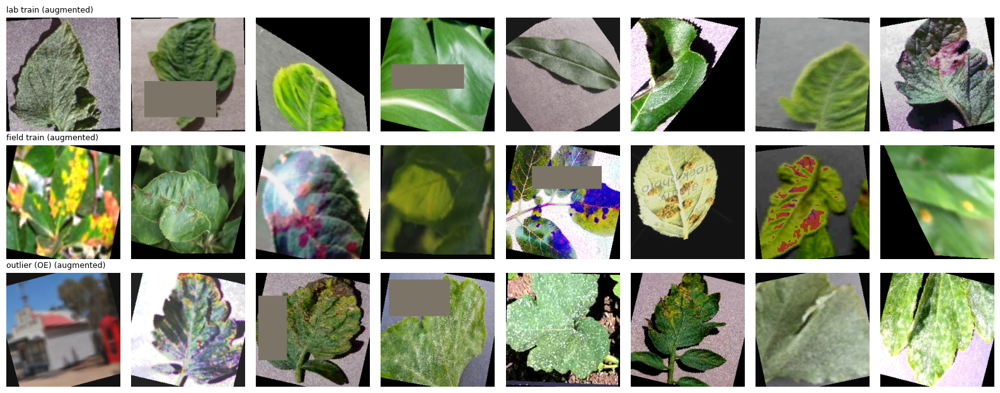

In [15]:
tracker.begin("6 data loaders")
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(AMP and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True            # faster; runs are seeded but not bit-exact reproducible
EVAL_TFMS = build_eval_tfms(IMAGE_SIZE)
TRAIN_TFMS = build_train_tfms(IMAGE_SIZE, ROBUST_AUG, AUG_BLUR_P, AUG_JPEG_P, AUG_LOWRES_P, AUG_ERASE_P, TRIVIAL_AUGMENT)

def probe_workers(n):
    try:
        s = D[D["role"] == "train"].head(8)
        dl = DataLoader(ImageTable(s["load_path"].tolist(), s["y"].to_numpy(), EVAL_TFMS), batch_size=4, num_workers=n)
        next(iter(dl))
        return True
    except Exception as e:
        log(f"DataLoader workers={n} failed ({type(e).__name__}: {str(e)[:80]}) -> falling back to 0 workers")
        return False

if NUM_WORKERS == "auto":
    want = min(4 if platform.system() == "Windows" else 8, os.cpu_count() or 1)
    NW = want if (want > 0 and probe_workers(want)) else 0
else:
    NW = int(NUM_WORKERS)
log(f"DataLoader workers: {NW} | device: {DEVICE} | AMP: {USE_AMP}")

def make_loader(frame, tfms, shuffle=False, sampler=None, corruption=None, batch_size=None, drop_last=False, workers=None, persistent=False):
    ds = ImageTable(frame["load_path"].tolist(), frame["y"].to_numpy(), tfms, corruption)
    nw = NW if workers is None else min(workers, NW)
    kw = dict(batch_size=batch_size or EVAL_BATCH_SIZE, num_workers=nw, pin_memory=(DEVICE.type == "cuda"), drop_last=drop_last)
    if nw > 0:
        kw.update(prefetch_factor=4, persistent_workers=persistent)
    return DataLoader(ds, sampler=sampler, **kw) if sampler is not None else DataLoader(ds, shuffle=shuffle, **kw)

def get_frames(mix_field):
    def sel(roles, lab_only=False):
        m = D["role"].isin(roles)
        if lab_only: m &= (D["domain"] == "lab")
        return D[m].reset_index(drop=True)
    lo = not mix_field
    return {"train": sel(["train"], lo), "val_known": sel(["val_known"], lo),
            "cal_temp": sel(["cal_temp"], lo), "cal_thresh": sel(["cal_thresh"], lo),
            "known_test_lab": sel(["known_test_lab"]), "known_test_field": sel(["known_test_field"]),
            "oe_train": sel(["oe_train"]), "val_unknown": sel(["val_unknown"]), "test_unknown": sel(["test_unknown"])}

fsize = pd.DataFrame({tag: {k: len(v) for k, v in get_frames(mf).items()} for tag, mf in [("lab-only experiments", False), ("mixed experiments", True)]})
display(fsize)

# augmentation preview: what the network actually sees during training
def denorm(t):
    m = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); s = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()
prev = get_frames(True)
rows = []
for name, fr in [("lab train", prev["train"][prev["train"]["domain"] == "lab"]), ("field train", prev["train"][prev["train"]["domain"] == "field"]),
                 ("outlier (OE)", prev["oe_train"])]:
    if len(fr): rows.append((name, fr.sample(min(8, len(fr)), random_state=0)))
if rows:
    fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (name, fr) in enumerate(rows):
        ds = ImageTable(fr["load_path"].tolist(), fr["y"].to_numpy(), TRAIN_TFMS)
        for c in range(8):
            ax = axes[r, c]; ax.axis("off")
            if c < len(ds):
                ax.imshow(denorm(ds[c][0]))
        axes[r, 0].set_title(name + " (augmented)", loc="left", fontsize=9)
    fig.tight_layout(); fig.savefig(FIGURES / "augmentation_preview.png", dpi=150, bbox_inches="tight"); plt.show()
tracker.end("6 data loaders", f"workers={NW}")

## 8. Model, metrics and training utilities

In [16]:
from torchvision import models

class _ConvNeXtHead(nn.Module):
    def __init__(self, classifier):
        super().__init__(); self.classifier = classifier
    def forward(self, f):
        return self.classifier(f[:, :, None, None])

class _TimmEfficientNetV2B0(nn.Module):
    """Thin wrapper: pooled features and classifier are explicit for feature scoring and staged fine-tuning."""
    def __init__(self, num_classes, pretrained=True):
        super().__init__()
        try:
            import timm
        except ImportError as e:
            raise ImportError("EfficientNetV2-B0 requires timm. Install it with `pip install timm` and rerun the environment cell.") from e
        try:
            self.backbone = timm.create_model("tf_efficientnetv2_b0", pretrained=pretrained, num_classes=0)
        except Exception as e:
            if not pretrained:
                raise
            raise RuntimeError("Could not load ImageNet-pretrained tf_efficientnetv2_b0 weights. Check that timm is installed and the pretrained weights are available in the local cache or can be downloaded. The proposal requires transfer learning, so the notebook will not silently continue with random initialization.") from e
        self.classifier_head = nn.Linear(int(self.backbone.num_features), num_classes)
    def forward_features(self, x):
        spatial = self.backbone.forward_features(x)
        return self.backbone.forward_head(spatial, pre_logits=True)
    def forward(self, x):
        return self.classifier_head(self.forward_features(x))

def _load(builder, weights_enum, pretrained=True):
    if not pretrained:
        return builder(weights=None)
    try:
        return builder(weights=weights_enum.DEFAULT)
    except Exception as e:
        log(f"WARNING: pretrained weights unavailable ({type(e).__name__}); using random initialisation. Accuracy will suffer.")
        return builder(weights=None)

def build_model(name, num_classes, pretrained=True):
    name = name.lower()
    if name in {"tf_efficientnetv2_b0", "efficientnetv2_b0", "efficientnet_v2_b0"}:
        net = _TimmEfficientNetV2B0(num_classes=num_classes, pretrained=pretrained)
    elif name == "efficientnet_v2_s":
        net = _load(models.efficientnet_v2_s, models.EfficientNet_V2_S_Weights, pretrained)
        net.classifier[1] = nn.Linear(net.classifier[1].in_features, num_classes); head = net.classifier
        def ff(x, _n=net): return torch.flatten(_n.avgpool(_n.features(x)), 1)
        net.forward_features, net.classifier_head = ff, head
    elif name == "resnet50":
        net = _load(models.resnet50, models.ResNet50_Weights, pretrained)
        net.fc = nn.Linear(net.fc.in_features, num_classes); head = net.fc
        def ff(x, _n=net):
            f = _n.maxpool(_n.relu(_n.bn1(_n.conv1(x))))
            return torch.flatten(_n.avgpool(_n.layer4(_n.layer3(_n.layer2(_n.layer1(f))))), 1)
        net.forward_features, net.classifier_head = ff, head
    elif name == "convnext_tiny":
        net = _load(models.convnext_tiny, models.ConvNeXt_Tiny_Weights, pretrained)
        net.classifier[2] = nn.Linear(net.classifier[2].in_features, num_classes); head = _ConvNeXtHead(net.classifier)
        def ff(x, _n=net): return torch.flatten(_n.avgpool(_n.features(x)), 1)
        net.forward_features, net.classifier_head = ff, head
    else:
        raise ValueError("unsupported backbone " + name)
    # torchvision alternatives use custom feature/head attributes; the timm wrapper defines them itself.
    return net

def split_params(model):
    head = list(model.classifier_head.parameters()); ids = {id(p) for p in head}
    return [p for p in model.parameters() if id(p) not in ids], head

# ---------------- metrics ----------------
from scipy.stats import rankdata
_trapz = getattr(np, "trapezoid", None) or getattr(np, "trapz")

def softmax_np(z):
    z = z - z.max(axis=1, keepdims=True); p = np.exp(z); return p / p.sum(axis=1, keepdims=True)

def fast_auroc(ks, us):
    # unknown = positive, higher score = more unknown
    ks, us = np.asarray(ks, float), np.asarray(us, float)
    n_k, n_u = len(ks), len(us)
    if n_k == 0 or n_u == 0: return np.nan
    r = rankdata(np.concatenate([ks, us]))
    return float((r[n_k:].sum() - n_u * (n_u + 1) / 2) / (n_k * n_u))

def fast_ood_metrics(ks, us):
    ks, us = np.asarray(ks, float), np.asarray(us, float)
    n_k, n_u = len(ks), len(us)
    if n_k == 0 or n_u == 0: return {"AUROC": np.nan, "FPR@95TPR": np.nan, "AUPR": np.nan}
    s = np.concatenate([ks, us])
    t = np.sort(us)[int(np.floor(0.05 * n_u))]
    y = np.concatenate([np.zeros(n_k), np.ones(n_u)])
    order = np.argsort(-s, kind="mergesort"); s_sorted, ys = s[order], y[order]
    last = np.r_[np.where(np.diff(s_sorted) != 0)[0], len(s) - 1]
    tp = np.cumsum(ys)[last]; prec = tp / (last + 1); rec = tp / n_u
    return {"AUROC": fast_auroc(ks, us), "FPR@95TPR": float((ks >= t).mean()), "AUPR": float(np.sum(np.diff(np.r_[0.0, rec]) * prec))}

def oscr_from_scores(ks, correct, us):
    order = np.argsort(ks, kind="mergesort"); ks_sorted = ks[order]
    cum = np.concatenate([[0], np.cumsum(correct[order])]); us_sorted = np.sort(us)
    thr = np.unique(np.concatenate([ks, us]))
    ccr = cum[np.searchsorted(ks_sorted, thr, side="right")] / max(1, len(ks))
    fpr = np.searchsorted(us_sorted, thr, side="right") / max(1, len(us))
    return float(_trapz(np.concatenate([[0.0], ccr]), np.concatenate([[0.0], fpr])))

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - h) / d, (c + h) / d)

def nll_score(p, y):
    v = y >= 0
    if not v.any(): return np.nan
    return float(-np.mean(np.log(np.clip(p[v][np.arange(v.sum()), y[v]], 1e-12, 1))))

def calib_curve(p, y, n_bins=15):
    v = y >= 0; conf, pred, yy = p[v].max(1), p[v].argmax(1), y[v]
    edges = np.linspace(0, 1, n_bins + 1); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf < hi if hi < 1 else conf <= hi)
        if m.any(): rows.append({"count": int(m.sum()), "confidence": float(conf[m].mean()), "accuracy": float((pred[m] == yy[m]).mean())})
    return pd.DataFrame(rows)

def ece_mce(p, y, n_bins=15, min_count=1):
    c = calib_curve(p, y, n_bins)
    if len(c) == 0: return np.nan, np.nan
    gap = (c["confidence"] - c["accuracy"]).abs(); ece = float((c["count"] * gap).sum() / c["count"].sum())
    big = c["count"] >= min_count
    return ece, (float(gap[big].max()) if big.any() else np.nan)

# ---------------- training utilities ----------------
@torch.no_grad()
def collect_logits(model, loader):
    model.eval(); Ls, Ys = [], []
    for x, y, _ in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            l = model(x)
        Ls.append(l.float().cpu().numpy()); Ys.append(y.numpy())
    return np.concatenate(Ls), np.concatenate(Ys)

class LivePlot:
    def __init__(self, title):
        self.title = title
        self.fig, self.axes = plt.subplots(1, 4, figsize=(17, 3.5)); plt.close(self.fig)
        self.handle = None
    def update(self, hist, best_epoch=None):
        h = pd.DataFrame(hist)
        if len(h) == 0: return
        x = h["global_epoch"]
        for ax in self.axes: ax.clear()
        a = self.axes
        a[0].plot(x, h["train_loss"], "o-", label="train loss")
        if "oe_loss" in h and h["oe_loss"].notna().any(): a[0].plot(x, h["oe_loss"], "s--", label="OE loss")
        a[0].set_title("loss"); a[0].legend(fontsize=7)
        a[1].plot(x, h["train_acc"], "o-", label="train"); a[1].plot(x, h["val_acc_lab"], "o-", label="val lab")
        if h["val_acc_field"].notna().any(): a[1].plot(x, h["val_acc_field"], "o-", label="val field")
        a[1].set_title("accuracy"); a[1].legend(fontsize=7); a[1].set_ylim(max(0, min(0.5, h["train_acc"].min() - 0.02)), 1.005)
        a[2].plot(x, h["val_nll"], "o-", color="tab:green"); a[2].set_title("known validation NLL (lower is better)")
        a[3].plot(x, h["lr"], "o-", color="tab:red"); a[3].set_yscale("log"); a[3].set_title("learning rate")
        a2 = a[3].twinx(); a2.plot(x, h["img_per_s"], "k:", label="img/s"); a2.set_ylabel("img/s")
        for ax in a:
            ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
            hb = h.loc[h["stage"] == "head", "global_epoch"].max()
            if pd.notna(hb) and (h["stage"] == "ft").any(): ax.axvline(hb + 0.5, color="gray", ls="--", lw=0.8)
            if best_epoch is not None: ax.axvline(best_epoch, color="gold", lw=2, alpha=0.5)
        self.fig.suptitle(self.title + "   (grey dashed = head -> fine-tune, gold = best epoch)", fontsize=10)
        self.fig.tight_layout()
        if self.handle is None: self.handle = display(self.fig, display_id=True)
        else: self.handle.update(self.fig)

def train_signature():
    sig = json.dumps([BACKBONE, IMAGE_SIZE, BATCH_SIZE, HEAD_EPOCHS, FT_EPOCHS, LR_HEAD, LR_BACKBONE, LR_HEAD_FT, WEIGHT_DECAY, LABEL_SMOOTHING,
                      ROBUST_AUG, TRIVIAL_AUGMENT, AUG_BLUR_P, AUG_JPEG_P, AUG_LOWRES_P, AUG_ERASE_P, FIELD_TARGET_FRACTION, OE_LAMBDA, OE_BATCH, PATIENCE])
    return hashlib.md5(sig.encode()).hexdigest()[:6]

# Include actual image hashes, labels and final role assignments so a changed map/split cannot reuse a stale checkpoint.
_SIG_COLS = [c for c in ("sha256", "dataset", "label", "domain", "role", "scenario", "label_eval", "y") if c in D.columns]
_DATA_ROLE_SIGNATURE = hashlib.sha256(D[_SIG_COLS].fillna("").astype(str).to_csv(index=False).encode("utf-8")).hexdigest()[:10]
def run_name(exp, seed):
    return f"v5_3_{exp}_{BACKBONE}_s{seed}_{SPLIT_TAG}_{train_signature()}_{_DATA_ROLE_SIGNATURE}"

def oe_sample_weights(oe):
    isbg = (oe["domain"] == "bg").to_numpy(); w = np.zeros(len(oe))
    share = 0.5 if (isbg.any() and (~isbg).any()) else 1.0
    for mask, key in [(~isbg, oe["unseen_class"]), (isbg, oe["bg_group"])]:
        if mask.any():
            g = key[mask]; w[mask] = share / g.nunique() / g.map(g.value_counts()).to_numpy()
    return w

def train_one_run(exp_name, seed, show_plot=True):
    cfg = EXPERIMENTS[exp_name]
    frames = get_frames(cfg["mix_field"])
    rn = run_name(exp_name, seed); rdir = CKPT_DIR / rn; rdir.mkdir(parents=True, exist_ok=True)
    # Seed BEFORE model construction so the randomly initialized classification head is controlled by this seed.
    seed_everything(seed)
    model = build_model(BACKBONE, N_CLASSES).to(DEVICE).to(memory_format=torch.channels_last)
    if CKPT_REUSE and (rdir / "final.pt").exists():
        model.load_state_dict(torch.load(rdir / "final.pt", map_location=DEVICE))
        hist = pd.read_csv(rdir / "history.csv") if (rdir / "history.csv").exists() else pd.DataFrame()
        log(f"[{rn}] finished run found -> loaded (delete {rdir.name}/ to retrain)")
        if show_plot and len(hist):
            lp = LivePlot(rn); lp.update(hist.to_dict("records"), best_epoch=int(hist.loc[hist["crit"].idxmax(), "global_epoch"]))
        return model, hist, rn
    tr = frames["train"]
    use_oe = bool(cfg["oe"] and len(frames["oe_train"]) > 0)
    if cfg["oe"] and not use_oe: log("WARNING: OE requested but no oe_train images exist; training without OE.")
    steps_per_epoch = max(1, len(tr) // BATCH_SIZE)
    n_f, n_l = int((tr["domain"] == "field").sum()), int((tr["domain"] == "lab").sum())
    if cfg["mix_field"] and n_f > 0 and n_l > 0:
        f = FIELD_TARGET_FRACTION
        w = np.where(tr["domain"] == "field", (f / (1 - f)) * n_l / n_f, 1.0)
        train_loader = make_loader(tr, TRAIN_TFMS, sampler=WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), len(tr), replacement=True),
                                   batch_size=BATCH_SIZE, drop_last=True, persistent=True)
        log(f"[{rn}] mixed-domain training: {n_l} lab + {n_f} field images, field share per epoch ~ {f:.0%}")
    else:
        train_loader = make_loader(tr, TRAIN_TFMS, shuffle=True, batch_size=BATCH_SIZE, drop_last=True, persistent=True)
    oe_loader = None
    if use_oe:
        oe = frames["oe_train"]
        oe_loader = make_loader(oe, TRAIN_TFMS, sampler=WeightedRandomSampler(torch.as_tensor(oe_sample_weights(oe), dtype=torch.double),
                                                                             steps_per_epoch * OE_BATCH + OE_BATCH, replacement=True),
                                batch_size=OE_BATCH, workers=2, persistent=True)
        log(f"[{rn}] outlier exposure: {len(oe)} outlier images ({oe['unseen_class'].replace('', np.nan).nunique()} disease classes, "
            f"{oe.loc[oe['domain'] == 'bg', 'bg_group'].nunique()} background groups), lambda={OE_LAMBDA}")
    # Dedicated known validation only: checkpoint selection must not consume calibration or unknown samples.
    vframe = frames["val_known"].reset_index(drop=True)
    v_known = vframe["y"].to_numpy() >= 0
    v_field = (vframe["domain"] == "field").to_numpy()
    if len(vframe) == 0:
        raise RuntimeError("val_known is empty after the leakage audit; cannot select a checkpoint without a dedicated known validation split.")
    vloader = make_loader(vframe, EVAL_TFMS, workers=2)

    backbone_params, head_params = split_params(model)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    schedule = [("head", e) for e in range(1, HEAD_EPOCHS + 1)] + [("ft", e) for e in range(1, FT_EPOCHS + 1)]
    hist, best_crit, bad, start_idx, resume = [], -np.inf, 0, 0, None
    if CKPT_REUSE and (rdir / "last.pt").exists():
        resume = torch.load(rdir / "last.pt", map_location="cpu", weights_only=False)
        model.load_state_dict(resume["model"]); hist, best_crit, bad = resume["history"], resume["best_crit"], resume["bad"]
        start_idx = resume["epoch_idx"] + 1
        log(f"[{rn}] RESUMING after epoch {start_idx}/{len(schedule)} (last.pt)")
        if start_idx >= len(schedule) or resume.get("stopped"): start_idx = len(schedule)
    plot = LivePlot(rn) if show_plot else None
    if plot is not None and hist: plot.update(hist)

    def build_stage(stage):
        if stage == "head":
            for p in backbone_params: p.requires_grad = False
            return torch.optim.AdamW(head_params, lr=LR_HEAD, weight_decay=WEIGHT_DECAY), None
        for p in backbone_params: p.requires_grad = True
        opt = torch.optim.AdamW([{"params": backbone_params, "lr": LR_BACKBONE}, {"params": head_params, "lr": LR_HEAD_FT}], weight_decay=WEIGHT_DECAY)
        total = FT_EPOCHS * steps_per_epoch; warm = max(1, int(WARMUP_FRAC * total))
        lam = lambda s: (s + 1) / warm if s < warm else 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
        return opt, torch.optim.lr_scheduler.LambdaLR(opt, lam)

    cur_stage, opt, sched = None, None, None
    t_run = time.time(); epoch_times = []
    log(f"[{rn}] training: {HEAD_EPOCHS} head + {FT_EPOCHS} fine-tune epochs, {steps_per_epoch} steps/epoch, batch {BATCH_SIZE}")
    try:
        for gi in range(start_idx, len(schedule)):
            stage, ep = schedule[gi]
            if stage != cur_stage:
                opt, sched = build_stage(stage); cur_stage = stage
                if resume is not None and resume["stage"] == stage:
                    opt.load_state_dict(resume["opt"]); scaler.load_state_dict(resume["scaler"])
                    if sched is not None and resume.get("sched") is not None: sched.load_state_dict(resume["sched"])
            if stage == "head":
                model.eval(); model.classifier_head.train()
            else:
                model.train()
            t0 = time.time(); n = 0; loss_sum = 0.0; oe_sum = 0.0; correct = 0
            oe_iter = iter(oe_loader) if oe_loader is not None else None
            bar = tqdm(train_loader, desc=f"{exp_name} {stage} {ep}/{HEAD_EPOCHS if stage == 'head' else FT_EPOCHS}", leave=False, dynamic_ncols=True)
            for it, (x, y, _) in enumerate(bar):
                x = x.to(DEVICE, non_blocking=True); y = y.to(DEVICE, non_blocking=True)
                if oe_iter is not None:
                    try: xo = next(oe_iter)[0]
                    except StopIteration:
                        oe_iter = iter(oe_loader); xo = next(oe_iter)[0]
                    xin = torch.cat([x, xo.to(DEVICE, non_blocking=True)])
                else:
                    xin = x
                xin = xin.contiguous(memory_format=torch.channels_last)
                opt.zero_grad(set_to_none=True)
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                    out = model(xin)
                out = out.float(); logits = out[:len(y)]
                loss = F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING)
                if oe_iter is not None:
                    l_oe = -(F.log_softmax(out[len(y):], dim=1).mean(dim=1)).mean()
                    loss = loss + OE_LAMBDA * l_oe; oe_sum += float(l_oe.detach()) * len(y)
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
                scaler.step(opt); scaler.update()
                if sched is not None: sched.step()
                n += len(y); loss_sum += float(loss.detach()) * len(y); correct += int((logits.argmax(1) == y).sum())
                if it % 10 == 0:
                    bar.set_postfix(loss=f"{loss_sum / n:.3f}", acc=f"{correct / n:.3f}", lr=f"{opt.param_groups[-1]['lr']:.1e}", ips=f"{n / (time.time() - t0):.0f}")
            bar.close()
            t_train = time.time() - t0
            Lv, yv = collect_logits(model, vloader); pv = softmax_np(Lv); pred = Lv.argmax(1)
            lab_m, fld_m = v_known & ~v_field, v_known & v_field
            acc_lab = float((pred[lab_m] == yv[lab_m]).mean()) if lab_m.any() else np.nan
            acc_fld = float((pred[fld_m] == yv[fld_m]).mean()) if fld_m.any() else np.nan
            # Monitor known-class performance on val_known; unknown rejection is tuned later on val_unknown.
            vauc = np.nan
            valid_acc = [a for a in (acc_lab, acc_fld) if np.isfinite(a)]
            crit = float(np.mean(valid_acc)) if valid_acc else -np.inf
            rec = {"run": rn, "stage": stage, "epoch": ep, "global_epoch": gi + 1, "train_loss": loss_sum / max(1, n), "train_acc": correct / max(1, n),
                   "oe_loss": (oe_sum / max(1, n)) if oe_iter is not None else np.nan, "val_acc_lab": acc_lab, "val_acc_field": acc_fld,
                   "val_nll": nll_score(pv[v_known], yv[v_known]), "val_auroc": vauc, "crit": crit, "lr": opt.param_groups[-1]["lr"],
                   "img_per_s": n / max(1e-9, t_train), "epoch_seconds": time.time() - t0,
                   "gpu_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else 0.0}
            hist.append(rec); epoch_times.append(rec["epoch_seconds"])
            improved = crit > best_crit + 1e-5
            if improved:
                best_crit, bad = crit, 0; torch.save(model.state_dict(), rdir / "best.pt")
            elif stage == "ft":
                bad += 1
            eta = np.mean(epoch_times) * (len(schedule) - gi - 1)
            tqdm.write(f"[{exp_name} s{seed}] {stage:4s} {ep:2d}/{HEAD_EPOCHS if stage == 'head' else FT_EPOCHS:<2d} | loss {rec['train_loss']:.3f} acc {rec['train_acc']:.3f}"
                       f" | val lab {acc_lab:.4f} field {acc_fld if not np.isnan(acc_fld) else float('nan'):.4f} | valNLL {rec['val_nll']:.4f} | lr {rec['lr']:.1e}"
                       f" | {rec['img_per_s']:.0f} img/s | {fmt_time(rec['epoch_seconds'])} | ETA {fmt_time(eta)}{'  *best*' if improved else ''}")
            pd.DataFrame(hist).to_csv(rdir / "history.csv", index=False)
            stop = stage == "ft" and bad >= PATIENCE
            torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict() if sched is not None else None,
                        "scaler": scaler.state_dict(), "stage": stage, "epoch_idx": gi, "history": hist, "best_crit": best_crit, "bad": bad,
                        "stopped": stop}, rdir / "last.pt")
            if plot is not None:
                plot.update(hist, best_epoch=int(pd.DataFrame(hist).loc[lambda d: d["crit"].idxmax(), "global_epoch"]))
            if stop:
                log(f"[{rn}] early stopping: no improvement for {PATIENCE} fine-tuning epochs")
                break
    except KeyboardInterrupt:
        log(f"[{rn}] interrupted. Re-run this cell: training resumes from the last finished epoch.")
        raise
    if (rdir / "best.pt").exists():
        model.load_state_dict(torch.load(rdir / "best.pt", map_location=DEVICE))
    torch.save(model.state_dict(), rdir / "final.pt")
    hdf = pd.DataFrame(hist); hdf.to_csv(rdir / "history.csv", index=False)
    log(f"[{rn}] done in {fmt_time(time.time() - t_run)} | best epoch {int(hdf.loc[hdf['crit'].idxmax(), 'global_epoch'])} | checkpoint {rdir.name}/final.pt")
    return model, hdf, rn

RUNS = {}
log("Training utilities ready.")

[02:54:15] Training utilities ready.


## 9. Training — one cell per experiment
Each cell shows a **live plot** (loss / accuracy per domain / validation AUROC / learning rate and throughput), a **progress bar** per epoch
and one summary line per epoch with an ETA. Runs are checkpointed every epoch; if the kernel stops, re-run the cell and it resumes.

model.safetensors: reconstructing file:   0%|          |  0.00B / 28.8MB            

model.safetensors: downloading bytes:           |  0.00B            

[02:54:17] [v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1451 steps/epoch, batch 16


A_lab_only head 1/2:   0%|          | 0/1451 [00:00<?, ?it/s]

[A_lab_only s42] head  1/2  | loss 1.174 acc 0.768 | val lab 0.9319 field nan | valNLL 0.3000 | lr 1.0e-03 | 212 img/s | 1m56s | ETA 25m15s  *best*


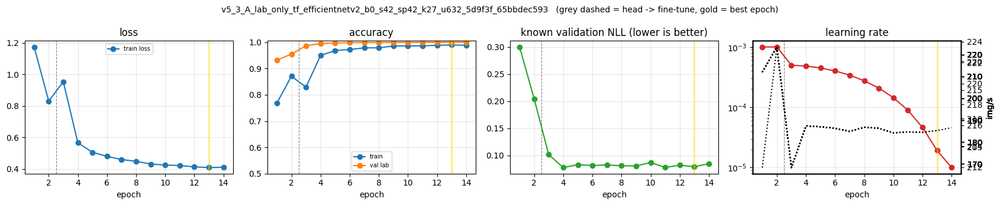

A_lab_only head 2/2:   0%|          | 0/1451 [00:00<?, ?it/s]

[A_lab_only s42] head  2/2  | loss 0.830 acc 0.871 | val lab 0.9548 field nan | valNLL 0.2044 | lr 1.0e-03 | 223 img/s | 1m47s | ETA 22m22s  *best*


A_lab_only ft 1/12:   0%|          | 0/1451 [00:00<?, ?it/s]

[A_lab_only s42] ft    2/12 | loss 0.566 acc 0.949 | val lab 0.9950 field nan | valNLL 0.0773 | lr 4.8e-04 | 187 img/s | 2m07s | ETA 20m30s  *best*


A_lab_only ft 3/12:   0%|          | 0/1451 [00:00<?, ?it/s]

[A_lab_only s42] ft    3/12 | loss 0.505 acc 0.968 | val lab 0.9972 field nan | valNLL 0.0827 | lr 4.5e-04 | 187 img/s | 2m07s | ETA 18m35s  *best*


... (15 outputs left out)

[A_lab_only s42] ft   11/12 | loss 0.408 acc 0.990 | val lab 1.0000 field nan | valNLL 0.0788 | lr 1.9e-05 | 185 img/s | 2m08s | ETA 2m06s  *best*


A_lab_only ft 12/12:   0%|          | 0/1451 [00:00<?, ?it/s]

[A_lab_only s42] ft   12/12 | loss 0.410 acc 0.989 | val lab 1.0000 field nan | valNLL 0.0845 | lr 1.0e-05 | 187 img/s | 2m07s | ETA 0m00s
[03:24:12] [v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] done in 29m55s | best epoch 13 | checkpoint v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593/final.pt

===== PIPELINE PROGRESS (7/16 done) =====


,,stage,status,time,note
0,[OK],1 image cache + hashes,done,10m40s,60960 images cached
1,[OK],2 near-duplicate clusters,done,0m03s,583 multi-image clusters
2,[OK],3 label map,done,0m00s,19 PlantVillage classes are map targets
3,[OK],4 class split,done,0m00s,"27 known, 6/3/2 unseen test/OE/val"
4,[OK],5 role assignment,done,0m01s,24483 train | 12641 unknown test
5,[OK],6 data loaders,done,0m02s,workers=4
6,[OK],7 training A_lab_only,done,29m57s,v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_...
7,[ ],7 training B_mixed,pending,,
8,[ ],7 training C_mixed_OE,pending,,
9,[ ],8 pools + detectors + evaluation,pending,,


In [17]:
EXP = "A_lab_only"
if EXP in RUN_EXPERIMENTS:
    tracker.begin("7 training " + EXP, EXPERIMENTS[EXP]["desc"])
    m, h, rn = train_one_run(EXP, TRAIN_SEED)
    RUNS[EXP] = {"model": m, "hist": h, "run_name": rn, "seed": TRAIN_SEED}
    tracker.end("7 training " + EXP, rn)
else:
    log(f"{EXP} not in RUN_EXPERIMENTS: skipped")
tracker.show()

[03:24:13] [v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[03:24:13] [v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


B_mixed head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s42] head  1/2  | loss 1.309 acc 0.703 | val lab 0.9124 field 0.6978 | valNLL 0.4033 | lr 1.0e-03 | 220 img/s | 1m58s | ETA 25m39s  *best*


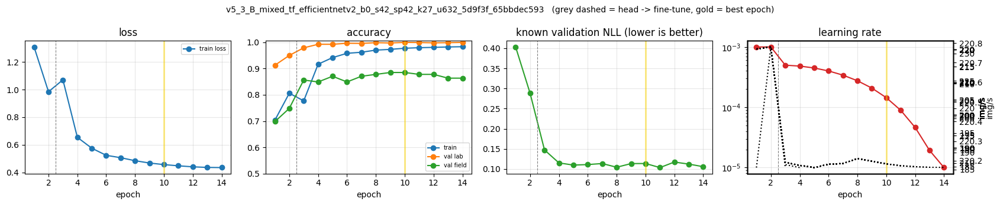

B_mixed head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s42] head  2/2  | loss 0.985 acc 0.806 | val lab 0.9498 field 0.7482 | valNLL 0.2883 | lr 1.0e-03 | 221 img/s | 1m54s | ETA 23m17s  *best*


B_mixed ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s42] ft    1/12 | loss 1.071 acc 0.777 | val lab 0.9788 field 0.8561 | valNLL 0.1473 | lr 5.0e-04 | 186 img/s | 2m15s | ETA 22m30s  *best*


B_mixed ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s42] ft    2/12 | loss 0.654 acc 0.917 | val lab 0.9922 field 0.8489 | valNLL 0.1150 | lr 4.8e-04 | 185 img/s | 2m16s | ETA 21m00s  *best*


... (17 outputs left out)

[B_mixed s42] ft   11/12 | loss 0.436 acc 0.982 | val lab 0.9983 field 0.8633 | valNLL 0.1120 | lr 1.9e-05 | 184 img/s | 2m16s | ETA 2m12s


B_mixed ft 12/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s42] ft   12/12 | loss 0.435 acc 0.983 | val lab 0.9994 field 0.8633 | valNLL 0.1056 | lr 1.0e-05 | 184 img/s | 2m16s | ETA 0m00s
[03:55:56] [v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] early stopping: no improvement for 4 fine-tuning epochs
[03:55:56] [v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] done in 31m43s | best epoch 10 | checkpoint v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593/final.pt

===== PIPELINE PROGRESS (8/16 done) =====


,,stage,status,time,note
0,[OK],1 image cache + hashes,done,10m40s,60960 images cached
1,[OK],2 near-duplicate clusters,done,0m03s,583 multi-image clusters
2,[OK],3 label map,done,0m00s,19 PlantVillage classes are map targets
3,[OK],4 class split,done,0m00s,"27 known, 6/3/2 unseen test/OE/val"
4,[OK],5 role assignment,done,0m01s,24483 train | 12641 unknown test
5,[OK],6 data loaders,done,0m02s,workers=4
6,[OK],7 training A_lab_only,done,29m57s,v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_...
7,[OK],7 training B_mixed,done,31m43s,v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27...
8,[ ],7 training C_mixed_OE,pending,,
9,[ ],8 pools + detectors + evaluation,pending,,


In [18]:
EXP = "B_mixed"
if EXP in RUN_EXPERIMENTS:
    tracker.begin("7 training " + EXP, EXPERIMENTS[EXP]["desc"])
    m, h, rn = train_one_run(EXP, TRAIN_SEED)
    RUNS[EXP] = {"model": m, "hist": h, "run_name": rn, "seed": TRAIN_SEED}
    tracker.end("7 training " + EXP, rn)
else:
    log(f"{EXP} not in RUN_EXPERIMENTS: skipped")
tracker.show()

[03:55:56] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[03:55:56] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] outlier exposure: 5489 outlier images (3 disease classes, 4 background groups), lambda=0.5
[03:55:56] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


C_mixed_OE head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s42] head  1/2  | loss 3.194 acc 0.699 | val lab 0.9180 field 0.7194 | valNLL 0.5084 | lr 1.0e-03 | 147 img/s | 2m50s | ETA 36m50s  *best*


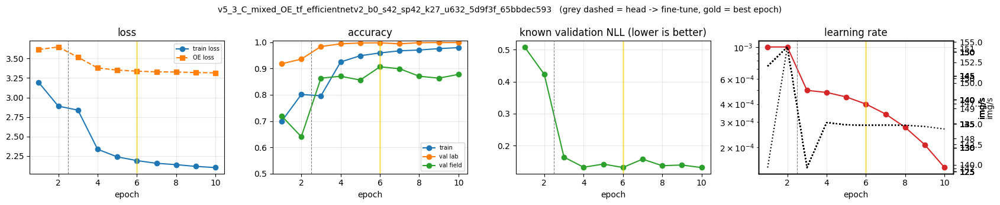

C_mixed_OE head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s42] head  2/2  | loss 2.889 acc 0.801 | val lab 0.9358 field 0.6403 | valNLL 0.4225 | lr 1.0e-03 | 151 img/s | 2m45s | ETA 33m33s


C_mixed_OE ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s42] ft    1/12 | loss 2.839 acc 0.796 | val lab 0.9838 field 0.8633 | valNLL 0.1639 | lr 5.0e-04 | 126 img/s | 3m18s | ETA 32m36s  *best*


C_mixed_OE ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s42] ft    2/12 | loss 2.337 acc 0.925 | val lab 0.9939 field 0.8705 | valNLL 0.1322 | lr 4.8e-04 | 135 img/s | 3m04s | ETA 29m55s  *best*


... (9 outputs left out)

[C_mixed_OE s42] ft    7/12 | loss 2.118 acc 0.976 | val lab 0.9989 field 0.8633 | valNLL 0.1391 | lr 2.1e-04 | 134 img/s | 3m05s | ETA 15m13s


C_mixed_OE ft 8/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s42] ft    8/12 | loss 2.103 acc 0.980 | val lab 0.9989 field 0.8777 | valNLL 0.1311 | lr 1.4e-04 | 134 img/s | 3m06s | ETA 12m12s
[04:27:01] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] early stopping: no improvement for 4 fine-tuning epochs
[04:27:01] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593] done in 31m04s | best epoch 6 | checkpoint v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_k27_u632_5d9f3f_65bbdec593/final.pt

===== PIPELINE PROGRESS (9/16 done) =====


,,stage,status,time,note
0,[OK],1 image cache + hashes,done,10m40s,60960 images cached
1,[OK],2 near-duplicate clusters,done,0m03s,583 multi-image clusters
2,[OK],3 label map,done,0m00s,19 PlantVillage classes are map targets
3,[OK],4 class split,done,0m00s,"27 known, 6/3/2 unseen test/OE/val"
4,[OK],5 role assignment,done,0m01s,24483 train | 12641 unknown test
5,[OK],6 data loaders,done,0m02s,workers=4
6,[OK],7 training A_lab_only,done,29m57s,v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_...
7,[OK],7 training B_mixed,done,31m43s,v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27...
8,[OK],7 training C_mixed_OE,done,31m04s,v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_...
9,[ ],8 pools + detectors + evaluation,pending,,


In [19]:
EXP = "C_mixed_OE"
if EXP in RUN_EXPERIMENTS:
    tracker.begin("7 training " + EXP, EXPERIMENTS[EXP]["desc"])
    m, h, rn = train_one_run(EXP, TRAIN_SEED)
    RUNS[EXP] = {"model": m, "hist": h, "run_name": rn, "seed": TRAIN_SEED}
    tracker.end("7 training " + EXP, rn)
else:
    log(f"{EXP} not in RUN_EXPERIMENTS: skipped")
tracker.show()

## 10. Pools, calibration and unknown-detectors
For each trained model: logits + penultimate features of every pool (cached), temperature / vector calibration (fit on `cal_temp`),
and the detectors. **Thresholds** are set on `cal_thresh` (known images only) for `TARGET_KNOWN_COVERAGE`. ODIN's `(T, epsilon)` is tuned on `val_unknown`
(held-out classes and groups that are in no test pool).

In [20]:
from types import SimpleNamespace
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

@torch.no_grad()
def collect_arrays(model, frame, corruption=None, desc=""):
    loader = make_loader(frame, EVAL_TFMS, corruption=corruption)
    model.eval(); Ls, Fs, Ys = [], [], []
    for x, y, _ in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        f = model.forward_features(x.to(DEVICE, non_blocking=True)); l = model.classifier_head(f)
        Ls.append(l.float().cpu().numpy()); Fs.append(f.float().cpu().numpy()); Ys.append(y.numpy())
    return {"L": np.concatenate(Ls), "F": np.concatenate(Fs), "y": np.concatenate(Ys)}

EVAL_POOLS = ["val_known", "cal_thresh", "known_test_lab", "known_test_field", "val_unknown", "test_unknown"]
def _sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk_size)
            if not block: break
            h.update(block)
    return h.hexdigest()

def _frame_fingerprint(frame):
    h = hashlib.sha256()
    cols = [c for c in ("orig_path", "sha256", "y", "role", "cluster") if c in frame.columns]
    for col in cols:
        h.update(col.encode("utf-8")); h.update(b"\0")
        for v in frame[col].fillna("").astype(str).to_numpy():
            h.update(v.encode("utf-8", errors="replace")); h.update(b"\n")
    return h.hexdigest()

def get_pools(model, frames, tag):
    bank = frames["train"].sample(min(FEATURE_BANK_MAX, len(frames["train"])), random_state=SPLIT_SEED).reset_index(drop=True)
    fm = {"bank": bank, "val_known": frames["val_known"], "cal_temp": frames["cal_temp"], "cal_thresh": frames["cal_thresh"],
          "known_test_lab": frames["known_test_lab"], "known_test_field": frames["known_test_field"],
          "val_unknown": frames["val_unknown"], "test_unknown": frames["test_unknown"]}
    path = CACHE / f"pools_{tag}.npz"
    checkpoint = CKPT_DIR / tag / "final.pt"
    if not checkpoint.is_file():
        raise FileNotFoundError(f"Expected completed checkpoint before pooling features: {checkpoint}")
    fp = hashlib.sha256()
    fp.update(tag.encode("utf-8")); fp.update(_sha256_file(checkpoint).encode("ascii"))
    for name, fr in fm.items():
        fp.update(name.encode("utf-8")); fp.update(_frame_fingerprint(fr).encode("ascii"))
    fingerprint = fp.hexdigest()

    cached = {}
    if CKPT_REUSE and path.exists():
        try:
            with np.load(path, allow_pickle=False) as z:
                saved_fp = str(z["__fingerprint__"].item()) if "__fingerprint__" in z.files else ""
                if saved_fp == fingerprint:
                    cached = {k: z[k] for k in z.files if k != "__fingerprint__"}
                else:
                    log(f"Feature cache invalidated for {tag}: checkpoint/data fingerprint changed")
        except Exception as e:
            log(f"Feature cache unreadable for {tag} ({type(e).__name__}); recomputing")
            cached = {}

    pools = {}
    for name, fr in fm.items():
        if len(fr) == 0:
            pools[name] = None; continue
        if f"{name}_L" in cached and len(cached[f"{name}_L"]) == len(fr):
            pools[name] = {"L": cached[f"{name}_L"].astype(np.float32), "F": cached[f"{name}_F"].astype(np.float32), "y": cached[f"{name}_y"].astype(int)}
        else:
            pools[name] = collect_arrays(model, fr, desc=f"features {name}")
    save = {"__fingerprint__": np.array(fingerprint)}
    for name, p in pools.items():
        if p is not None:
            save.update({f"{name}_L": p["L"].astype(np.float32), f"{name}_F": p["F"].astype(np.float32), f"{name}_y": p["y"].astype(np.int64)})
    np.savez(path, **save)
    return pools

# ---------------- calibrators ----------------
def fit_temperature(L, y, w=None):
    # 1-D convex NLL minimisation over log T (pure numpy/scipy; optional per-sample weights)
    from scipy.optimize import minimize_scalar
    v = np.asarray(y) >= 0
    Lv, yv = np.asarray(L, dtype=np.float64)[v], np.asarray(y)[v]
    wv = np.ones(len(yv)) if w is None else np.asarray(w, dtype=np.float64)[v]
    wv = wv / wv.sum()
    idx = np.arange(len(yv))
    def nll(lt):
        z = Lv / math.exp(lt); z = z - z.max(axis=1, keepdims=True)
        return float(-(wv * (z[idx, yv] - np.log(np.exp(z).sum(axis=1)))).sum())
    r = minimize_scalar(nll, bounds=(math.log(0.05), math.log(20.0)), method="bounded", options={"xatol": 1e-6})
    return float(math.exp(r.x))

def fit_vector_scaler(L, y, k):
    v = y >= 0
    lg = torch.tensor(L[v], dtype=torch.float32, device=DEVICE); lb = torch.tensor(y[v], dtype=torch.long, device=DEVICE)
    ls = torch.zeros(k, device=DEVICE, requires_grad=True); b = torch.zeros(k, device=DEVICE, requires_grad=True)
    opt = torch.optim.LBFGS([ls, b], lr=0.02, max_iter=200)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(lg * ls.exp() + b, lb); loss.backward(); return loss
    opt.step(closure)
    return ls.detach().cpu().numpy(), b.detach().cpu().numpy()

def probs_T(L, T): return softmax_np(L / T)

def wquantile(v, w, q):
    # smallest value whose cumulative normalised weight reaches q
    v = np.asarray(v, dtype=np.float64); w = np.asarray(w, dtype=np.float64)
    o = np.argsort(v, kind="mergesort"); cw = np.cumsum(w[o]) / w.sum()
    return float(v[o][min(int(np.searchsorted(cw, q, side="left")), len(v) - 1)])

def domain_weights(frame, w_field):
    # lab/field balanced weights (sum 1). All-lab or all-field pools get uniform weights.
    isf = (frame["domain"] == "field").to_numpy(); w = np.ones(len(frame))
    if isf.any() and (~isf).any():
        w[isf] = w_field / isf.sum(); w[~isf] = (1.0 - w_field) / (~isf).sum()
    return w / w.sum()

def youden_threshold(kn, wk, un, uscen, min_cov, fallback):
    # Validation-only rule: maximise J = (weighted known acceptance) - (macro false-accept over validation unknown scenarios)
    # subject to known acceptance >= min_cov. Accept = score <= threshold. Test data is never touched.
    kn, un, wk = np.asarray(kn, dtype=np.float64), np.asarray(un, dtype=np.float64), np.asarray(wk, dtype=np.float64)
    if len(kn) == 0 or len(un) == 0: return float(fallback)
    scen = list(dict.fromkeys(np.asarray(uscen).tolist())); wk = wk / wk.sum()
    best, best_key = None, None
    for t in np.unique(np.quantile(kn, np.linspace(0.5, 1.0, 201))):
        cov = float((wk * (kn <= t)).sum())
        if cov < min_cov: continue
        fa = float(np.mean([(un[np.asarray(uscen) == s] <= t).mean() for s in scen]))
        key = (cov - fa, cov)
        if best_key is None or key > best_key: best, best_key = float(t), key
    return float(fallback) if best is None else best
def probs_vec(L, vs): return softmax_np(L * np.exp(vs[0]) + vs[1])

# ---------------- detectors ----------------
def msp_score(L, T=1.0): return 1.0 - probs_T(L, T).max(1)
def entropy_score(L, T=1.0):
    p = probs_T(L, T); return -(p * np.log(np.clip(p, 1e-12, 1))).sum(1)
def energy_score(L, T=1.0):
    z = L / T; m = z.max(1, keepdims=True); return -T * (np.log(np.exp(z - m).sum(1)) + m[:, 0])
def _clean(v): return np.nan_to_num(np.asarray(v, dtype=np.float64), nan=1e12, posinf=1e12, neginf=-1e12)

try:
    from scipy.stats import weibull_min
    SCIPY_OK = True
except Exception:
    SCIPY_OK = False

class OODScorer:
    # every detector for ONE model. Fitted on known data only. HIGHER score = MORE LIKELY UNKNOWN; accept when score <= threshold
    def __init__(self, T): self.T, self.om, self.omx, self.thr, self.thr_pooled, self.thr_balanced = T, None, None, {}, {}, {}
    def fit(self, bank_F, bank_y, ct_L, ct_F, ct_y, norm_L, norm_F, th_L, th_F, th_w=None):
        ok = bank_y >= 0; Fb, yb = bank_F[ok].astype(np.float64), bank_y[ok]
        if len(Fb) == 0:
            raise ValueError("OODScorer requires at least one labelled known-class training feature.")
        gm = Fb.mean(0)
        self.mu = np.stack([Fb[yb == c].mean(0) if (yb == c).any() else gm for c in range(N_CLASSES)])
        Xc = Fb - self.mu[yb]; S = Xc.T @ Xc / max(1, len(Xc)); d = S.shape[0]
        S = (1 - MAHA_SHRINKAGE) * S + MAHA_SHRINKAGE * np.trace(S) / max(1, d) * np.eye(d)
        self.P = np.linalg.pinv(S); self.muP = self.mu @ self.P; self.mu_quad = (self.muP * self.mu).sum(1)
        self.bank = (bank_F / (np.linalg.norm(bank_F, axis=1, keepdims=True) + 1e-12)).astype(np.float32)
        self.k = int(min(KNN_K, len(self.bank)))
        if RUN_OPENMAX and SCIPY_OK:
            good = (ct_y >= 0) & (ct_L.argmax(1) == ct_y)
            means, weib = self._fit_openmax(ct_F[good], ct_y[good])
            if means: self.om = (means, weib)
            lm, lw = self._fit_openmax(ct_L[good], ct_y[good], OPENMAX_TAIL)   # original-style: mean activation vectors in LOGIT space
            if lm: self.omx = (lm, lw)
        # Fit score-normalisation constants on the dedicated known-validation pool.
        # Use a separate cal_thresh pool only to set the final operating thresholds.
        if len(norm_L) == 0 or len(norm_F) == 0 or len(th_L) == 0 or len(th_F) == 0:
            raise ValueError("Known validation and threshold-calibration pools must both be non-empty.")
        base = self._parts(norm_L, norm_F)
        self.fz = {"msp": (np.log(base["msp"] + 1e-6).mean(), np.log(base["msp"] + 1e-6).std() + 1e-12),
                   "knn": (base["knn"].mean(), base["knn"].std() + 1e-12),
                   "maha": (np.log(base["maha"] + 1e-6).mean(), np.log(base["maha"] + 1e-6).std() + 1e-12)}
        sc = self.scores(th_L, th_F)
        self.thr_pooled = {m: float(np.quantile(v, TARGET_KNOWN_COVERAGE)) for m, v in sc.items()}
        self.thr_balanced = {m: wquantile(v, th_w, TARGET_KNOWN_COVERAGE) for m, v in sc.items()} if th_w is not None else dict(self.thr_pooled)
        self.thr = dict(self.thr_balanced) if THRESHOLD_MODE == "balanced" else dict(self.thr_pooled)
        return self
    def _fit_openmax(self, Fe, y, tail=20):
        means, weib = {}, {}
        for c in range(N_CLASSES):
            X = Fe[y == c]
            if len(X) < 5: continue
            mu = X.mean(0); dist = np.sort(np.linalg.norm(X - mu, axis=1))[-min(tail, len(X)):]
            try: shape, loc, scale = weibull_min.fit(dist, floc=0)
            except Exception: continue
            means[c], weib[c] = mu, (shape, loc, max(scale, 1e-8))
        return means, weib
    def _knn(self, Fe):
        Fn = (Fe / (np.linalg.norm(Fe, axis=1, keepdims=True) + 1e-12)).astype(np.float32)
        out = np.empty(len(Fn)); nb = self.bank.shape[0]
        for i in range(0, len(Fn), 2048):
            sims = Fn[i:i + 2048] @ self.bank.T
            out[i:i + 2048] = -np.partition(sims, nb - self.k, axis=1)[:, nb - self.k]
        return out
    def _maha(self, Fe):
        out = np.empty(len(Fe))
        for i in range(0, len(Fe), 4096):
            X = Fe[i:i + 4096].astype(np.float64); A = X @ self.P
            q = (A * X).sum(1)[:, None] - 2.0 * (A @ self.mu.T) + self.mu_quad[None, :]
            out[i:i + 4096] = q.min(1)
        return out
    def _openmax(self, Fe, L):
        adj = softmax_np(L)
        for c, mu in self.om[0].items():
            shape, loc, scale = self.om[1][c]
            adj[:, c] *= 1.0 - weibull_min.cdf(np.linalg.norm(Fe - mu, axis=1), shape, loc=loc, scale=scale)
        return 1.0 - adj.sum(1)
    def _openmax_logit(self, L, alpha=None):
        # Bendale & Boult style: revise the top-alpha activations with Weibull outlier probabilities, put the removed mass on an
        # explicit unknown logit and softmax over K+1 entries. Returns P(unknown) (higher = more unknown).
        means, weib = self.omx
        K = L.shape[1]; a = int(min(alpha or OPENMAX_ALPHA, K))
        order = np.argsort(-L, axis=1)[:, :a]; adj = L.astype(np.float64).copy(); unk = np.zeros(len(L))
        for r in range(a):
            rw = (a - r) / a
            for c in np.unique(order[:, r]):
                if c not in means: continue
                rows = np.flatnonzero(order[:, r] == c)
                shape, loc, scale = weib[c]
                w = weibull_min.cdf(np.linalg.norm(L[rows] - means[c], axis=1), shape, loc=loc, scale=scale)
                new = L[rows, c] * (1.0 - w * rw)
                unk[rows] += L[rows, c] - new; adj[rows, c] = new
        z = np.concatenate([adj, unk[:, None]], axis=1); z = z - z.max(axis=1, keepdims=True); p = np.exp(z)
        return p[:, -1] / p.sum(axis=1)
    def _parts(self, L, Fe):
        return {"msp": msp_score(L, self.T), "knn": self._knn(Fe), "maha": np.maximum(self._maha(Fe), 0)}
    def scores(self, L, Fe):
        p = self._parts(L, Fe); z = lambda a, k: (a - self.fz[k][0]) / self.fz[k][1] if hasattr(self, "fz") else a
        out = {"MSP": p["msp"], "Entropy": entropy_score(L, self.T), "Energy": energy_score(L, 1.0), "MaxLogit": -L.max(1),
               "kNN": p["knn"], "Mahalanobis": p["maha"]}
        if hasattr(self, "fz"):
            out["MSP+kNN"] = z(np.log(p["msp"] + 1e-6), "msp") + z(p["knn"], "knn")
            out["MSP+Maha"] = z(np.log(p["msp"] + 1e-6), "msp") + z(np.log(p["maha"] + 1e-6), "maha")
        if self.om is not None: out["OpenMax-feat"] = self._openmax(Fe, L)      # v5.3 feature-space variant (kept for comparison)
        if self.omx is not None: out["OpenMax"] = self._openmax_logit(L)
        return {k: _clean(v) for k, v in out.items()}
    def state(self):
        return {"T": self.T, "mu": self.mu, "P": self.P, "bank": self.bank.astype(np.float16), "k": self.k, "fz": self.fz, "thr": self.thr, "thr_pooled": self.thr_pooled, "om": self.om, "omx": self.omx}
    @classmethod
    def from_state(cls, s):
        o = cls(s["T"]); o.mu, o.P, o.k, o.fz, o.thr = s["mu"], s["P"], s["k"], s["fz"], s["thr"]
        o.om = s.get("om"); o.omx = s.get("omx"); o.thr_pooled = s.get("thr_pooled", dict(s["thr"]))
        o.muP = o.mu @ o.P; o.mu_quad = (o.muP * o.mu).sum(1); o.bank = s["bank"].astype(np.float32); return o

def odin_multi(model, frame, Ts, epss, desc="ODIN", corruption=None):
    # one backward pass per T, then every epsilon: returns {(T, eps): scores}
    loader = make_loader(frame, EVAL_TFMS, batch_size=64, corruption=corruption)
    std = torch.tensor(IMAGENET_STD, device=DEVICE).view(1, 3, 1, 1)
    out = {(T, e): [] for T in Ts for e in epss}
    model.eval()
    for x, _, _ in tqdm(loader, desc=desc, leave=False, dynamic_ncols=True):
        x = x.to(DEVICE).requires_grad_(True)
        logits = model(x)
        for T in Ts:
            loss = F.cross_entropy(logits / T, logits.argmax(1))
            g = torch.autograd.grad(loss, x, retain_graph=True)[0].sign()
            for e in epss:
                if e == 0: lp = logits.detach()
                else:
                    with torch.no_grad(): lp = model((x - e * g / std).detach())
                out[(T, e)].append((1.0 - F.softmax(lp.float() / T, dim=1).max(1).values).detach().cpu().numpy())
    return {k: _clean(np.concatenate(v)) for k, v in out.items()}

def tune_and_score_odin(model, frames):
    cap = lambda fr: fr.sample(min(ODIN_TUNE_CAP, len(fr)), random_state=0).reset_index(drop=True)
    if len(frames["val_unknown"]) == 0:
        best = (1000.0, 0.0014); log("ODIN: no val_unknown images; using literature defaults T=1000 eps=0.0014")
    else:
        kk = odin_multi(model, cap(frames["val_known"]), ODIN_T_GRID, ODIN_EPS_GRID, "ODIN tune (known validation)")
        uu = odin_multi(model, cap(frames["val_unknown"]), ODIN_T_GRID, ODIN_EPS_GRID, "ODIN tune (val unknown)")
        grid = pd.DataFrame([{"T": T, "eps": e, "val_AUROC": fast_auroc(kk[(T, e)], uu[(T, e)])} for (T, e) in kk]).sort_values("val_AUROC", ascending=False)
        grid.to_csv(TABLES / "odin_tuning_grid.csv", index=False)
        best = (float(grid.iloc[0]["T"]), float(grid.iloc[0]["eps"]))
        log(f"ODIN tuned on val_unknown: T={best[0]:g} eps={best[1]:g} (val AUROC {grid.iloc[0]['val_AUROC']:.4f}); grid saved to odin_tuning_grid.csv")
    can = (float(ODIN_CANONICAL[0]), float(ODIN_CANONICAL[1]))
    Ts, es = sorted({best[0], can[0]}), sorted({best[1], can[1]})
    res, res_can = {}, {}
    for name in EVAL_POOLS:
        fr = frames[name]
        if len(fr):
            d = odin_multi(model, fr, Ts, es, f"ODIN {name}"); res[name], res_can[name] = d[best], d[can]
        else:
            res[name] = res_can[name] = np.array([])
    return res, res_can, {"T": best[0], "eps": best[1], "tuned_is_plain_msp": bool(best[0] == 1.0 and best[1] == 0.0)}

def build_context(exp_name, model, frames, rn, seed):
    pools = get_pools(model, frames, rn)
    ct = pools["cal_temp"]
    T_pooled = fit_temperature(ct["L"], ct["y"])
    T_bal = fit_temperature(ct["L"], ct["y"], domain_weights(frames["cal_temp"], FIELD_CAL_WEIGHT)) if CALIB_DOMAIN_BALANCED else T_pooled
    T = T_bal
    vs = fit_vector_scaler(ct["L"], ct["y"], N_CLASSES)
    th = pools["cal_thresh"]; vk = pools["val_known"]
    w_th = domain_weights(frames["cal_thresh"], FIELD_CAL_WEIGHT)
    scorer = OODScorer(T).fit(pools["bank"]["F"], pools["bank"]["y"], ct["L"], ct["F"], ct["y"], vk["L"], vk["F"], th["L"], th["F"], th_w=w_th)
    S = {}
    for name in EVAL_POOLS:
        p = pools[name]
        S[name] = scorer.scores(p["L"], p["F"]) if p is not None else {m: np.array([]) for m in scorer.thr}
    assert THRESHOLD_MODE in ("pooled", "balanced", "val_youden"), THRESHOLD_MODE
    modes, odin_info = {"pooled": dict(scorer.thr_pooled), "balanced": dict(scorer.thr_balanced)}, None
    if RUN_ODIN:
        os_, os_can, odin_info = tune_and_score_odin(model, frames)
        for name in EVAL_POOLS:
            S[name]["ODIN"] = os_[name]; S[name]["ODIN_canonical"] = os_can[name]
        for nm, arr in (("ODIN", os_["cal_thresh"]), ("ODIN_canonical", os_can["cal_thresh"])):
            modes["pooled"][nm] = float(np.quantile(arr, TARGET_KNOWN_COVERAGE))
            modes["balanced"][nm] = wquantile(arr, w_th, TARGET_KNOWN_COVERAGE)
    wk_val = domain_weights(frames["val_known"], FIELD_CAL_WEIGHT)
    vu_scen = frames["val_unknown"]["scenario"].astype(str).to_numpy()
    modes["val_youden"] = {m: youden_threshold(S["val_known"][m], wk_val, S["val_unknown"][m], vu_scen, VAL_MIN_COVERAGE, modes["pooled"][m]) for m in modes["pooled"]}
    thr, thr_pooled = dict(modes[THRESHOLD_MODE]), dict(modes["pooled"])
    empty = lambda: {"L": np.zeros((0, N_CLASSES)), "F": np.zeros((0, 1)), "y": np.zeros(0, int)}
    for n in EVAL_POOLS:
        if pools[n] is None: pools[n] = empty()
    methods = list(S["test_unknown"].keys())
    log(f"[{exp_name}] T pooled={T_pooled:.3f} balanced={T_bal:.3f} (used {T:.3f}) | threshold mode: {THRESHOLD_MODE}")
    return SimpleNamespace(exp=exp_name, seed=seed, run_name=rn, model=model, frames=frames, pools=pools, T=T, T_pooled=T_pooled, T_bal=T_bal, vec=vs, scorer=scorer,
                           S=S, thr=thr, thr_pooled=thr_pooled, thr_modes=modes, methods=methods, odin=odin_info)
log("Detector framework ready.")

[04:27:01] Detector framework ready.


## 11. Evaluation of one experiment
Known test sets: `known_lab` (lab-style) and `known_field` (field-style, known diseases). Unknown test scenarios: `unseen_disease`,
`cross_domain_novel`, `background_texture`, `background_real`. Every number below uses the **same** test pools for A, B and C.

In [21]:
SCEN_ORDER = ["unseen_disease", "cross_domain_novel", "cross_domain_unmapped", "background_texture", "background_real"]
HEADLINE_CANDIDATES = ["MSP", "MSP+kNN", "MSP+Maha", "Mahalanobis", "kNN", "Entropy", "Energy", "MaxLogit", "OpenMax", "OpenMax-feat", "ODIN", "ODIN_canonical"]

def known_all(ctx, m):
    return np.concatenate([ctx.S["known_test_lab"][m], ctx.S["known_test_field"][m]])

def known_correct(ctx):
    kl, kf = ctx.pools["known_test_lab"], ctx.pools["known_test_field"]
    return np.concatenate([kl["L"].argmax(1) == kl["y"], kf["L"].argmax(1) == kf["y"]])

def evaluate(ctx, out_dir=None, light=False):
    R = {}
    m_list, S, P, fr = ctx.methods, ctx.S, ctx.pools, ctx.frames
    u_frame = fr["test_unknown"].reset_index(drop=True)
    u_scen = u_frame["scenario"].to_numpy()
    scen_present = [s for s in SCEN_ORDER if (u_scen == s).any()]
    
    kcorr = known_correct(ctx)
    n_lab = len(P["known_test_lab"]["y"])
    n_fld = len(P["known_test_field"]["y"])
    is_lab = np.r_[np.ones(n_lab, bool), np.zeros(n_fld, bool)]

    # --- classification: explicitly report all requested macro metrics and confusion matrices ---
    rows = []
    def _class_metrics(pool_name, pool, matrix_name, per_class_name):
        y_true = np.asarray(pool["y"], dtype=int)
        y_pred = np.asarray(pool["L"]).argmax(1)
        valid = (y_true >= 0) & (y_true < N_CLASSES)
        y_true, y_pred = y_true[valid], y_pred[valid]
        if len(y_true) == 0:
            R[matrix_name] = pd.DataFrame()
            R[per_class_name] = pd.DataFrame()
            return
        pr, rc, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(N_CLASSES), zero_division=0)
        sup = support > 0      # macro metrics are averaged ONLY over classes that have test images (v5.3 averaged zeros for absent classes)
        rows.append({"pool": pool_name, "n": len(y_true), "accuracy": float((y_pred == y_true).mean()), "n_classes_with_support": int(sup.sum()),
                     "macro_precision": float(pr[sup].mean()), "macro_recall": float(rc[sup].mean()), "macro_F1": float(f1[sup].mean())})
        pc = pd.DataFrame({"class": known_classes, "precision": pr, "recall": rc, "f1": f1, "support": support})
        R[per_class_name] = pc
        cm = confusion_matrix(y_true, y_pred, labels=np.arange(N_CLASSES))
        cm_df = pd.DataFrame(cm, columns=[f"pred_{name}" for name in known_classes])
        cm_df.insert(0, "true_class", known_classes)
        R[matrix_name] = cm_df
        
    kl = P["known_test_lab"]
    _class_metrics("known_lab", kl, "confusion_matrix_lab", "per_class_lab")
    if n_fld:
        kf = P["known_test_field"]
        _class_metrics("known_field (all)", kf, "confusion_matrix_field", "per_class_field")
        for d in sorted(fr["known_test_field"]["dataset"].unique()):
            mk = (fr["known_test_field"]["dataset"] == d).to_numpy()
            y_d, pred_d = kf["y"][mk], kf["L"][mk].argmax(1)
            valid_d = (y_d >= 0) & (y_d < N_CLASSES)
            y_d, pred_d = y_d[valid_d], pred_d[valid_d]
            if len(y_d):
                pr_d, rc_d, f1_d, sup_d = precision_recall_fscore_support(y_d, pred_d, labels=np.arange(N_CLASSES), zero_division=0)
                sm = sup_d > 0
                rows.append({"pool": f"known_field: {d}", "n": len(y_d), "accuracy": float((pred_d == y_d).mean()), "n_classes_with_support": int(sm.sum()),
                             "macro_precision": float(pr_d[sm].mean()), "macro_recall": float(rc_d[sm].mean()), "macro_F1": float(f1_d[sm].mean())})
    else:
        R["confusion_matrix_field"] = pd.DataFrame()
        R["per_class_field"] = pd.DataFrame()
    R["classification"] = pd.DataFrame(rows)

    # --- calibration per domain: deployed T, pooled T, vector scaling; field also split by source dataset ---
    rows = []
    cal_sets = [("lab", P["known_test_lab"], None), ("field", P["known_test_field"], None)]
    if n_fld:
        fds = fr["known_test_field"]["dataset"].to_numpy()
        cal_sets += [(f"field: {d}", P["known_test_field"], fds == d) for d in sorted(set(fds))]
    for dom, p, mk in cal_sets:
        L_, y_ = (p["L"], p["y"]) if mk is None else (p["L"][mk], p["y"][mk])
        if len(y_) == 0: continue
        variants = [("raw", softmax_np(L_)), ("temperature", probs_T(L_, ctx.T))]
        if abs(ctx.T_pooled - ctx.T) > 1e-9: variants.append(("temperature_pooled", probs_T(L_, ctx.T_pooled)))
        variants.append(("vector", probs_vec(L_, ctx.vec)))
        for nm, pp in variants:
            e, mce = ece_mce(pp, y_, min_count=MIN_BIN_COUNT_MCE)
            rows.append({"domain": dom, "calibration": nm, "n": int(len(y_)), "NLL": nll_score(pp, y_), "ECE": e, "MCE": mce})
    R["calibration"] = pd.DataFrame(rows)

    # --- main OOD table: three known sets vs pooled unknown ---
    rows = []
    for m in m_list:
        us = S["test_unknown"][m]
        for kname, ks, kc in [("known_lab", S["known_test_lab"][m], kcorr[is_lab]), 
                              ("known_field", S["known_test_field"][m], kcorr[~is_lab]),
                              ("known_all", known_all(ctx, m), kcorr)]:
            if len(ks) == 0: continue
            rows.append({"method": m, "known_set": kname, **fast_ood_metrics(ks, us), "OSCR": oscr_from_scores(ks, kc, us)})
    R["ood_main"] = pd.DataFrame(rows)

    # --- per scenario (known_all) + macro ---
    rows = []
    for m in m_list:
        ks = known_all(ctx, m)
        for sc in scen_present:
            mt = fast_ood_metrics(ks, S["test_unknown"][m][u_scen == sc])
            rows.append({"method": m, "scenario": sc, "n_unknown": int((u_scen == sc).sum()), **mt})
    sc_tab = pd.DataFrame(rows)
    R["ood_scenario"] = sc_tab
    R["ood_scenario_macro"] = sc_tab.groupby("method")[["AUROC", "FPR@95TPR", "AUPR"]].mean().reindex(m_list).reset_index()

    # --- operating point (selected threshold mode) and the plain pooled-calibration thresholds for comparison ---
    def op_table(thr_map):
        rows = []
        for m in m_list:
            thr = thr_map[m]
            us = S["test_unknown"][m]
            ks = known_all(ctx, m)
            acc_k = ks <= thr
            row = {"method": m, "threshold": thr,
                   "coverage_lab": float((S["known_test_lab"][m] <= thr).mean()),
                   "coverage_field": float((S["known_test_field"][m] <= thr).mean()) if n_fld else np.nan,
                   "coverage_all": float(acc_k.mean()),
                   "selective_acc": float(kcorr[acc_k].mean()) if acc_k.any() else np.nan,
                   "FA_pooled": float((us <= thr).mean())}
            for sc in scen_present:
                k_ = int((us[u_scen == sc] <= thr).sum()); n_ = int((u_scen == sc).sum())
                lo, hi = wilson(k_, n_)
                row[f"FA@{sc}"], row[f"FA_lo@{sc}"], row[f"FA_hi@{sc}"] = k_ / max(1, n_), lo, hi
            row["FA_macro"] = float(np.mean([row[f"FA@{s}"] for s in scen_present]))
            rows.append(row)
        return pd.DataFrame(rows)
    op = op_table(ctx.thr)
    ops = {mode: op_table(thr_m) for mode, thr_m in ctx.thr_modes.items()}      # every threshold rule is exported
    for mode, t_ in ops.items(): R[f"operating_{mode}"] = t_
    R["operating"] = op

    # --- domain gap: can the detector tell lab known from field known? 0.5 = style invisible ---
    if n_fld:
        R["domain_gap"] = pd.DataFrame([{"method": m, "AUROC_lab_vs_field": fast_auroc(S["known_test_lab"][m], S["known_test_field"][m])} for m in m_list])

    # --- select headline method on validation data only (never inspect test AUROC for selection) ---
    # val_known supplies known validation scores; val_unknown supplies unseen disease/background validation OODs.
    val_frame = fr["val_unknown"].reset_index(drop=True)
    val_scenarios = val_frame["scenario"].astype(str).to_numpy() if len(val_frame) else np.array([], dtype=str)
    val_scen_present = list(dict.fromkeys(val_scenarios.tolist()))
    selection_rows = []
    for method in HEADLINE_CANDIDATES:
        if method not in m_list: continue
        known_val = S["val_known"][method]
        per_scenario = []
        for scenario in val_scen_present:
            unknown_val = S["val_unknown"][method][val_scenarios == scenario]
            auc_val = fast_auroc(known_val, unknown_val)
            if np.isfinite(auc_val): per_scenario.append(float(auc_val))
            selection_rows.append({"method": method, "validation_scenario": scenario, "validation_AUROC": auc_val})
        selection_rows.append({"method": method, "validation_scenario": "MACRO",
                               "validation_AUROC": float(np.mean(per_scenario)) if per_scenario else np.nan})
    selection_df = pd.DataFrame(selection_rows)
    macro_rows = selection_df[selection_df["validation_scenario"] == "MACRO"].dropna(subset=["validation_AUROC"])
    if len(macro_rows):
        # Candidate list order makes ties deterministic. Test-set scores are not consulted here.
        macro_scores = macro_rows.set_index("method")["validation_AUROC"]
        eligible = [m for m in HEADLINE_CANDIDATES if m in macro_scores.index]
        ctx.headline = max(eligible, key=lambda m: float(macro_scores[m]))
    else:
        ctx.headline = "MSP" if "MSP" in m_list else m_list[0]
        log("WARNING: no usable validation unknown pool; using the predeclared fallback detector, not selecting from test metrics.")
    R["method_selection_validation"] = selection_df
    log(f"Headline method selected from validation data only: {ctx.headline}")
    if HEADLINE_METHOD and HEADLINE_METHOD in m_list:
        if HEADLINE_METHOD != ctx.headline: log(f"Headline detector fixed in advance: {HEADLINE_METHOD} (validation would have picked {ctx.headline}; selection table is exported)")
        ctx.headline = HEADLINE_METHOD
    ana = [ctx.headline] + [m for m in ["MSP"] if m != ctx.headline and m in m_list]

    # --- false-accept breakdowns ---
    pred = P["test_unknown"]["L"].argmax(1)
    pred_cls = np.array([idx_to_class[int(i)] for i in pred]) if len(pred) else np.array([])
    fa_rows = []
    for m in ana:
        thr = ctx.thr[m]
        acc = S["test_unknown"][m] <= thr
        def add(kind, key, extra=None):
            g = pd.DataFrame({"g": key, "acc": acc}).groupby("g")["acc"].agg(["sum", "count"])
            for gname, r in g.iterrows():
                if gname == "-": continue
                lo, hi = wilson(int(r["sum"]), int(r["count"]))
                fa_rows.append({"method": m, "kind": kind, "group": gname, "n": int(r["count"]), "false_accepted": int(r["sum"]),
                                "FA_rate": r["sum"] / r["count"], "FA_lo": lo, "FA_hi": hi, **(extra(gname) if extra else {})})
        add("scenario", u_scen)
        mbg = (u_frame["domain"] == "bg").to_numpy()
        if mbg.any():
            info = u_frame[mbg].drop_duplicates("bg_group").set_index("bg_group")
            add("bg_group", np.where(mbg, u_frame["bg_group"].to_numpy(), "-"),
                lambda g: {"bg_kind": info["bg_kind"].get(g, ""), "pure_test_group": bool(info["bg_pure"].get(g, False)),
                           "plant_like": any(k in str(g).lower() for k in PLANT_LIKE_KEYWORDS)})
        mu_ = (u_scen == "unseen_disease")
        if mu_.any():
            add("unseen_class", np.where(mu_, u_frame["unseen_class"].to_numpy(), "-"))
            ucrop = u_frame["unseen_class"].map(crop_of).to_numpy()
            fa_idx = np.where(mu_ & acc)[0]
            if len(fa_idx):
                same = np.mean([crop_of(pred_cls[i]) == ucrop[i] for i in fa_idx])
                fa_rows.append({"method": m, "kind": "same_crop_rate_among_false_accepts", "group": "unseen_disease", "n": len(fa_idx),
                                "false_accepted": len(fa_idx), "FA_rate": float(same), "FA_lo": np.nan, "FA_hi": np.nan})
        mc = (u_scen == "cross_domain_novel")
        if mc.any(): add("cross_domain_dataset_unseen_disease", np.where(mc, u_frame["dataset"].to_numpy(), "-"))
        mm = (u_scen == "cross_domain_unmapped")
        if mm.any(): add("cross_domain_dataset_unmapped", np.where(mm, u_frame["dataset"].to_numpy(), "-"))
        add("predicted_class", np.where(acc, pred_cls, "(rejected)"))
    R["false_accept"] = pd.DataFrame(fa_rows)

    # --- risk-coverage curve and AURC (selective prediction on known_all) ---
    aurc_rows, rc_rows = [], []
    for m in m_list:
        scores = known_all(ctx, m)
        if len(scores) == 0:
            continue
        order = np.argsort(scores, kind="mergesort")  # low OOD score = accepted first
        correct_sorted = kcorr[order].astype(float)
        n_acc = np.arange(1, len(correct_sorted) + 1)
        coverage = n_acc / len(correct_sorted)
        risk = 1.0 - np.cumsum(correct_sorted) / n_acc
        # Include the origin so numeric integration and plotting begin at zero coverage.
        rows_m = [{"method": m, "coverage": 0.0, "risk": 0.0, "accepted": 0, "n_known": int(len(scores))}]
        rows_m += [{"method": m, "coverage": float(cv), "risk": float(rv), "accepted": int(na), "n_known": int(len(scores))}
                   for cv, rv, na in zip(coverage, risk, n_acc)]
        rc_rows.extend(rows_m)
        aurc_rows.append({"method": m, "AURC": float(_trapz(np.r_[0.0, risk], np.r_[0.0, coverage]))})
    R["risk_coverage"] = pd.DataFrame(rc_rows)
    R["aurc"] = pd.DataFrame(aurc_rows)

    # --- cluster bootstrap ---
    if not light and N_BOOTSTRAP > 0 and len(kcorr) and len(u_frame):
        kcl = np.concatenate([fr["known_test_lab"]["cluster"].to_numpy(), fr["known_test_field"]["cluster"].to_numpy()])
        ucl = u_frame["cluster"].to_numpy()
        ck, nck = pd.factorize(kcl)[0], pd.factorize(kcl)[0].max() + 1
        cu, ncu = pd.factorize(ucl)[0], pd.factorize(ucl)[0].max() + 1
        Ks = {m: known_all(ctx, m) for m in m_list}
        Us = {m: S["test_unknown"][m] for m in m_list}
        rng = np.random.default_rng(0)
        acc_b = {m: {"AUROC": [], "FPR95": [], "coverage": [], "FA": []} for m in m_list}
        for _ in tqdm(range(N_BOOTSTRAP), desc="cluster bootstrap", leave=False, dynamic_ncols=True):
            ik = np.repeat(np.arange(len(ck)), np.bincount(rng.integers(0, nck, nck), minlength=nck)[ck])
            iu = np.repeat(np.arange(len(cu)), np.bincount(rng.integers(0, ncu, ncu), minlength=ncu)[cu])
            for m in m_list:
                ks, us = Ks[m][ik], Us[m][iu]
                t = np.partition(us, int(0.05 * len(us)))[int(0.05 * len(us))]
                acc_b[m]["AUROC"].append(fast_auroc(ks, us))
                acc_b[m]["FPR95"].append(float((ks >= t).mean()))
                acc_b[m]["coverage"].append(float((ks <= ctx.thr[m]).mean()))
                acc_b[m]["FA"].append(float((us <= ctx.thr[m]).mean()))
        rows = []
        for m in m_list:
            for k, v in acc_b[m].items():
                v = np.asarray(v)
                rows.append({"method": m, "metric": k, "mean": v.mean(), "ci_low": np.percentile(v, 2.5), "ci_high": np.percentile(v, 97.5)})
            if m != "MSP" and "MSP" in m_list:
                for k in ("AUROC", "FA"):
                    d = np.asarray(acc_b[m][k]) - np.asarray(acc_b["MSP"][k])
                    rows.append({"method": m, "metric": f"{k} diff vs MSP", "mean": d.mean(), "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5)})
        R["bootstrap_ci"] = pd.DataFrame(rows)

    # --- summary row ---
    hm = ctx.headline
    g = lambda df, col, **kw: (df.query(" and ".join(f"{k}=='{v}'" for k, v in kw.items()))[col].iloc[0] if len(df.query(" and ".join(f"{k}=='{v}'" for k, v in kw.items()))) else np.nan)
    clf = R["classification"]
    cal = R["calibration"]
    
    summ = {"experiment": ctx.exp, "seed": ctx.seed, "headline_method": hm, "T": ctx.T,
            "acc_lab": g(clf, "accuracy", pool="known_lab"), "acc_field": g(clf, "accuracy", pool="known_field (all)"),
            "macro_precision_lab": g(clf, "macro_precision", pool="known_lab"),
            "macro_recall_lab": g(clf, "macro_recall", pool="known_lab"),
            "macro_F1_lab": g(clf, "macro_F1", pool="known_lab"),
            "macro_precision_field": g(clf, "macro_precision", pool="known_field (all)"),
            "macro_recall_field": g(clf, "macro_recall", pool="known_field (all)"),
            "macro_F1_field": g(clf, "macro_F1", pool="known_field (all)"),
            "ECE_lab": g(cal, "ECE", domain="lab", calibration="temperature"), 
            "ECE_field": g(cal, "ECE", domain="field", calibration="temperature")}
            
    # FIXED LOOP: Proper indentation applied and undefined `mac` variable replaced with direct DataFrame lookup
    for m in [x for x in ["MSP", hm] if x in m_list]:
        tag = "MSP" if m == "MSP" else "HEAD"
        
        # Lookup directly from the ood_scenario_macro DataFrame
        summ[f"{tag}_macroAUROC"] = float(R["ood_scenario_macro"].set_index("method").loc[m, "AUROC"])
        summ[f"{tag}_macroFPR95"] = float(R["ood_scenario_macro"].set_index("method").loc[m, "FPR@95TPR"])
        
        r = op[op["method"] == m].iloc[0]
        summ[f"{tag}_cov_lab"], summ[f"{tag}_cov_field"], summ[f"{tag}_FA_macro"] = r["coverage_lab"], r["coverage_field"], r["FA_macro"]
        
        for sc in scen_present: 
            summ[f"{tag}_FA@{sc}"] = r[f"FA@{sc}"]
            
    mac_ = R["ood_scenario_macro"].set_index("method")
    for m in [x for x in FIXED_DETECTORS if x in m_list and x != "MSP"]:
        summ[f"{m}_macroAUROC"], summ[f"{m}_macroFPR95"] = float(mac_.loc[m, "AUROC"]), float(mac_.loc[m, "FPR@95TPR"])
        r = op[op["method"] == m].iloc[0]
        summ[f"{m}_cov_lab"], summ[f"{m}_cov_field"], summ[f"{m}_FA_macro"] = r["coverage_lab"], r["coverage_field"], r["FA_macro"]
        for sc in scen_present: summ[f"{m}_FA@{sc}"] = r[f"FA@{sc}"]
    for m in [x for x in dict.fromkeys(["MSP", hm] + list(FIXED_DETECTORS)) if x in m_list]:
        for mode, t_ in ops.items():
            r = t_[t_["method"] == m].iloc[0]
            summ[f"{m}@{mode}_cov_lab"], summ[f"{m}@{mode}_cov_field"], summ[f"{m}@{mode}_FA_macro"] = r["coverage_lab"], r["coverage_field"], r["FA_macro"]
            for sc in scen_present: summ[f"{m}@{mode}_FA@{sc}"] = r[f"FA@{sc}"]
    if "domain_gap" in R:
        dg = R["domain_gap"].set_index("method")["AUROC_lab_vs_field"]
        summ["domain_gap_AUROC_MSP"] = float(dg.get("MSP", np.nan))
        summ["domain_gap_AUROC_HEAD"] = float(dg.get(hm, np.nan))
        
    R["summary"] = pd.DataFrame([summ])
    
    if out_dir is not None:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        for k, v in R.items(): 
            v.to_csv(out_dir / f"{k}.csv", index=False)
            
    return R

## 12. Run the evaluation for every trained experiment

In [22]:
tracker.begin("8 pools + detectors + evaluation")
CTX, RES = {}, {}
for exp in RUN_EXPERIMENTS:
    if exp not in RUNS:
        log(f"{exp}: no trained model in this session (run its training cell first); skipped"); continue
    t0 = time.time()
    log(f"--- evaluating {exp} ---")
    frames = get_frames(EXPERIMENTS[exp]["mix_field"])
    ctx = build_context(exp, RUNS[exp]["model"], frames, RUNS[exp]["run_name"], RUNS[exp]["seed"])
    RES[exp] = evaluate(ctx, EXP_DIR / exp)
    CTX[exp] = ctx
    s = RES[exp]["summary"].iloc[0]
    log(f"{exp}: acc lab {s['acc_lab']:.4f} | acc field {s['acc_field']:.4f} | headline {s['headline_method']} macro-AUROC {s['HEAD_macroAUROC']:.4f} "
        f"| coverage lab/field {s['HEAD_cov_lab']:.3f}/{s['HEAD_cov_field']:.3f} | FA macro {s['HEAD_FA_macro']:.3f}  ({fmt_time(time.time() - t0)})")
tracker.end("8 pools + detectors + evaluation", f"{len(CTX)} experiments")

[04:27:01] --- evaluating A_lab_only ---


features bank:   0%|          | 0/469 [00:00<?, ?it/s]

features val_known:   0%|          | 0/56 [00:00<?, ?it/s]

features cal_temp:   0%|          | 0/57 [00:00<?, ?it/s]

features cal_thresh:   0%|          | 0/56 [00:00<?, ?it/s]

features known_test_lab:   0%|          | 0/224 [00:00<?, ?it/s]

... (54 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[05:02:10] [C_mixed_OE] T pooled=0.545 balanced=0.675 (used 0.675) | threshold mode: pooled
[05:02:10] Headline method selected from validation data only: MSP+kNN
[05:02:10] Headline detector fixed in advance: MaxLogit (validation would have picked MSP+kNN; selection table is exported)


cluster bootstrap:   0%|          | 0/300 [00:00<?, ?it/s]

[05:05:33] C_mixed_OE: acc lab 0.9957 | acc field 0.8813 | headline MaxLogit macro-AUROC 0.9469 | coverage lab/field 0.973/0.790 | FA macro 0.177  (13m33s)


## 13. Experiment comparison (A vs B vs C): which fix actually helped?

Same test sets for every row. FA = unknown images wrongly accepted at the threshold for 95% known coverage.


experiment,A_lab_only,B_mixed,C_mixed_OE
headline_method,MaxLogit,MaxLogit,MaxLogit
acc_lab,0.999162,0.997486,0.995671
acc_field,0.16172,0.88434,0.881269
ECE_lab,0.000712,0.014791,0.013049
ECE_field,0.617505,0.04073,0.058221
MSP_macroAUROC,0.898701,0.917182,0.94742
HEAD_macroAUROC,0.868726,0.924995,0.946898
HEAD_cov_lab,0.942466,0.981427,0.973048
HEAD_cov_field,0.025589,0.708291,0.790174
HEAD_FA@unseen_disease,0.201013,0.200101,0.151874


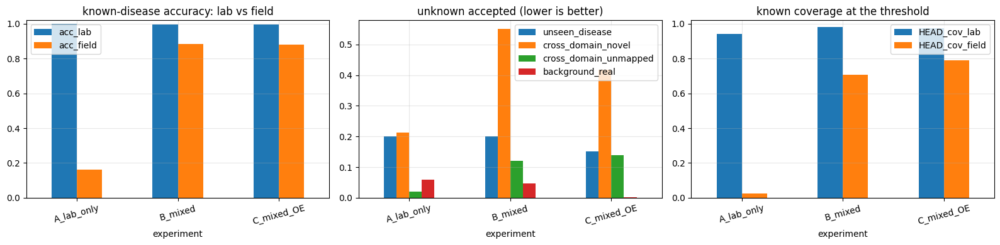


===== A_lab_only: operating points (baseline: lab images only) =====


,method,coverage_lab,coverage_field,selective_acc,FA_pooled,FA@unseen_disease,FA@cross_domain_novel,FA@cross_domain_unmapped,FA@background_real
0,MSP,0.9499,0.0307,0.9984,0.1664,0.2003,0.1595,0.0222,0.0252
3,MaxLogit,0.9425,0.0256,0.9987,0.1725,0.2010,0.2118,0.0211,0.0587
4,kNN,0.9570,0.0020,1.0000,0.1290,0.1600,0.1002,0.0089,0.0000
5,Mahalanobis,0.9506,0.0000,0.9999,0.0593,0.0759,0.0023,0.0000,0.0000
6,MSP+kNN,0.9522,0.0041,1.0000,0.1164,0.1449,0.0797,0.0055,0.0007
7,MSP+Maha,0.9521,0.0031,0.9999,0.0857,0.1089,0.0159,0.0011,0.0000



===== B_mixed: operating points (+ field images of known diseases (train/cal/test)) =====


,method,coverage_lab,coverage_field,selective_acc,FA_pooled,FA@unseen_disease,FA@cross_domain_novel,FA@cross_domain_unmapped,FA@background_real
0,MSP,0.9686,0.7666,0.9964,0.1731,0.1770,0.5581,0.1598,0.0363
3,MaxLogit,0.9814,0.7083,0.9964,0.1892,0.2001,0.5513,0.1199,0.0468
4,kNN,0.9946,0.6151,0.9968,0.4936,0.6050,0.2779,0.1487,0.0084
5,Mahalanobis,0.9939,0.6407,0.9959,0.5418,0.6838,0.0547,0.0844,0.0000
6,MSP+kNN,0.9852,0.6663,0.9987,0.1571,0.1777,0.3417,0.0832,0.0049
7,MSP+Maha,0.9838,0.6581,0.9984,0.1289,0.1497,0.2118,0.0599,0.0028



===== C_mixed_OE: operating points (+ outlier exposure (held-out unseen classes + background groups)) =====


,method,coverage_lab,coverage_field,selective_acc,FA_pooled,FA@unseen_disease,FA@cross_domain_novel,FA@cross_domain_unmapped,FA@background_real
0,MSP,0.9691,0.8025,0.9938,0.1866,0.2044,0.4191,0.1731,0.0014
3,MaxLogit,0.9730,0.7902,0.9933,0.1430,0.1519,0.4169,0.1387,0.0007
4,kNN,0.9947,0.5977,0.9946,0.7383,0.7611,0.4647,0.4107,0.8714
5,Mahalanobis,0.9869,0.6868,0.9921,0.7615,0.7679,0.3986,0.5172,0.9825
6,MSP+kNN,0.9887,0.6510,0.9964,0.1608,0.1871,0.2460,0.0866,0.0000
7,MSP+Maha,0.9842,0.6899,0.9968,0.3057,0.2326,0.2301,0.2164,0.8889


,experiment,method,macroAUROC,FPR95_macro,cov_lab,cov_field,FA_macro,FA@unseen_disease,FA@cross_domain_novel,FA@cross_domain_unmapped,FA@background_real
0,A_lab_only,MSP,0.8987,0.2804,0.9499,0.0307,0.1018,0.2003,0.1595,0.0222,0.0252
1,A_lab_only,MaxLogit,0.8687,0.4212,0.9425,0.0256,0.1232,0.2010,0.2118,0.0211,0.0587
2,A_lab_only,Energy,0.8617,0.4266,0.9443,0.0276,0.1352,0.2046,0.2346,0.0255,0.0762
3,A_lab_only,MSP+kNN,0.9043,0.1987,0.9522,0.0041,0.0577,0.1449,0.0797,0.0055,0.0007
4,A_lab_only,OpenMax,0.8520,0.5166,0.9521,0.9243,0.6185,0.7760,0.4579,0.7636,0.4766
5,A_lab_only,ODIN_canonical,0.7615,0.8908,0.9448,0.4504,0.4212,0.6280,0.4966,0.2786,0.2816
6,B_mixed,MSP,0.9172,0.4206,0.9686,0.7666,0.2328,0.1770,0.5581,0.1598,0.0363
7,B_mixed,MaxLogit,0.9250,0.3818,0.9814,0.7083,0.2295,0.2001,0.5513,0.1199,0.0468
8,B_mixed,Energy,0.9211,0.3833,0.9832,0.7001,0.2419,0.2185,0.5604,0.1243,0.0643
9,B_mixed,MSP+kNN,0.9669,0.1237,0.9852,0.6663,0.1519,0.1777,0.3417,0.0832,0.0049


Same detector, three threshold rules (coverage vs false-accept trade-off):


,experiment,threshold_rule,method,cov_lab,cov_field,FA_macro,FA@unseen_disease,FA@cross_domain_novel,FA@cross_domain_unmapped,FA@background_real
0,A_lab_only,pooled,MSP,0.950,0.031,0.102,0.200,0.159,0.022,0.025
1,A_lab_only,pooled,MaxLogit,0.942,0.026,0.123,0.201,0.212,0.021,0.059
2,A_lab_only,pooled,Energy,0.944,0.028,0.135,0.205,0.235,0.026,0.076
3,A_lab_only,pooled,MSP+kNN,0.952,0.004,0.058,0.145,0.080,0.006,0.001
4,A_lab_only,pooled,OpenMax,0.952,0.924,0.619,0.776,0.458,0.764,0.477
5,A_lab_only,pooled,ODIN_canonical,0.945,0.450,0.421,0.628,0.497,0.279,0.282
6,A_lab_only,balanced,MSP,0.950,0.031,0.102,0.200,0.159,0.022,0.025
7,A_lab_only,balanced,MaxLogit,0.942,0.026,0.123,0.201,0.212,0.021,0.059
8,A_lab_only,balanced,Energy,0.944,0.028,0.135,0.205,0.235,0.026,0.076
9,A_lab_only,balanced,MSP+kNN,0.952,0.004,0.058,0.145,0.080,0.006,0.001



===== PIPELINE PROGRESS (11/16 done) =====


,,stage,status,time,note
0,[OK],1 image cache + hashes,done,10m40s,60960 images cached
1,[OK],2 near-duplicate clusters,done,0m03s,583 multi-image clusters
2,[OK],3 label map,done,0m00s,19 PlantVillage classes are map targets
3,[OK],4 class split,done,0m00s,"27 known, 6/3/2 unseen test/OE/val"
4,[OK],5 role assignment,done,0m01s,24483 train | 12641 unknown test
5,[OK],6 data loaders,done,0m02s,workers=4
6,[OK],7 training A_lab_only,done,29m57s,v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_...
7,[OK],7 training B_mixed,done,31m43s,v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27...
8,[OK],7 training C_mixed_OE,done,31m04s,v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_...
9,[OK],8 pools + detectors + evaluation,done,38m31s,3 experiments


In [23]:
tracker.begin("9 experiment comparison")
comp = pd.concat([RES[e]["summary"] for e in RES], ignore_index=True).set_index("experiment")
comp.to_csv(TABLES / "experiment_comparison.csv")
show_cols = [c for c in ["headline_method", "acc_lab", "acc_field", "ECE_lab", "ECE_field", "MSP_macroAUROC", "HEAD_macroAUROC", "HEAD_cov_lab", "HEAD_cov_field",
                         "HEAD_FA@unseen_disease", "HEAD_FA@cross_domain_novel", "HEAD_FA@background_texture", "HEAD_FA@background_real",
                         "HEAD_FA_macro", "domain_gap_AUROC_MSP"] if c in comp.columns]
print("Same test sets for every row. FA = unknown images wrongly accepted at the threshold for", f"{TARGET_KNOWN_COVERAGE:.0%}", "known coverage.")
display(comp[show_cols].T)

if len(comp) >= 1:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    comp[["acc_lab", "acc_field"]].plot.bar(ax=axes[0], rot=15); axes[0].set_title("known-disease accuracy: lab vs field"); axes[0].set_ylim(0, 1.02)
    fa_cols = [c for c in comp.columns if c.startswith("HEAD_FA@")]
    comp[fa_cols].rename(columns=lambda c: c.replace("HEAD_FA@", "")).plot.bar(ax=axes[1], rot=15); axes[1].set_title("unknown accepted (lower is better)")
    comp[[c for c in ["HEAD_cov_lab", "HEAD_cov_field"] if c in comp.columns]].plot.bar(ax=axes[2], rot=15); axes[2].set_title("known coverage at the threshold"); axes[2].set_ylim(0, 1.02)
    for a in axes: a.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(FIGURES / "experiment_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

for e in RES:
    print(f"\n===== {e}: operating points ({EXPERIMENTS[e]['desc']}) =====")
    op = RES[e]["operating"]
    display(op[op["method"].isin(["MSP", "Mahalanobis", "kNN", "MSP+kNN", "MSP+Maha", RES[e]["summary"].iloc[0]["headline_method"]])].drop_duplicates("method")
            [["method", "coverage_lab", "coverage_field", "selective_acc", "FA_pooled"] + [c for c in op.columns if c.startswith("FA@")]].round(4))
# Fair A/B/C comparison: the SAME detector in every experiment (the validation-selected headline detector differs between experiments).
fixed = [m for m in ["MSP", "MaxLogit", "Energy", "MSP+kNN", "OpenMax", "ODIN_canonical"] if all(m in RES[e]["operating"]["method"].values for e in RES)]
rows = []
for e in RES:
    op_ = RES[e]["operating"].set_index("method"); mac_ = RES[e]["ood_scenario_macro"].set_index("method")
    for m in fixed:
        rows.append({"experiment": e, "method": m, "macroAUROC": mac_.loc[m, "AUROC"], "FPR95_macro": mac_.loc[m, "FPR@95TPR"], "cov_lab": op_.loc[m, "coverage_lab"], "cov_field": op_.loc[m, "coverage_field"],
                     "FA_macro": op_.loc[m, "FA_macro"], **{c: op_.loc[m, c] for c in op_.columns if c.startswith("FA@")}})
same_det = pd.DataFrame(rows); same_det.to_csv(TABLES / "same_detector_comparison.csv", index=False)
display(same_det.round(4))
mode_rows = []
for e in RES:
    for k in RES[e]:
        if not k.startswith("operating_"): continue
        t_ = RES[e][k].set_index("method")
        for m in fixed:
            mode_rows.append({"experiment": e, "threshold_rule": k[len("operating_"):], "method": m, "cov_lab": t_.loc[m, "coverage_lab"], "cov_field": t_.loc[m, "coverage_field"],
                              "FA_macro": t_.loc[m, "FA_macro"], **{c: t_.loc[m, c] for c in t_.columns if c.startswith("FA@")}})
rule_tab = pd.DataFrame(mode_rows); rule_tab.to_csv(TABLES / "threshold_rule_comparison.csv", index=False)
print("Same detector, three threshold rules (coverage vs false-accept trade-off):"); display(rule_tab.round(3))
tracker.end("9 experiment comparison")
tracker.show()

## 14. Corruption study (final experiment)
Blur, JPEG, low resolution, sensor noise, brightness/contrast and occlusion at three severities, applied to the test images.
Thresholds stay at their **clean** values: the question is whether known images are still accepted (coverage) and unknown ones still rejected.
Note that blur / JPEG / low-res are part of the training augmentation, so this measures robustness *after* augmentation, not generalisation to unseen corruption types.

corruption conditions:   0%|          | 0/19 [00:00<?, ?it/s]

clean 0 known_lab:   0%|          | 0/22 [00:00<?, ?it/s]

clean 0 known_field:   0%|          | 0/22 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79b4613498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79b4613498a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

clean 0 unknown:   0%|          | 0/80 [00:00<?, ?it/s]

blur 1 known_lab:   0%|          | 0/22 [00:00<?, ?it/s]

... (56 outputs left out)

occlusion 3 known_field:   0%|          | 0/22 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79b4613498a0>
<function _MultiProcessingDataLoaderIter.__del__ at 0x79b4613498a0>
Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a

occlusion 3 unknown:   0%|          | 0/80 [00:00<?, ?it/s]

Clean reference (MaxLogit): accuracy 0.942 | coverage 0.883 | FA macro 0.179 | AUROC 0.929


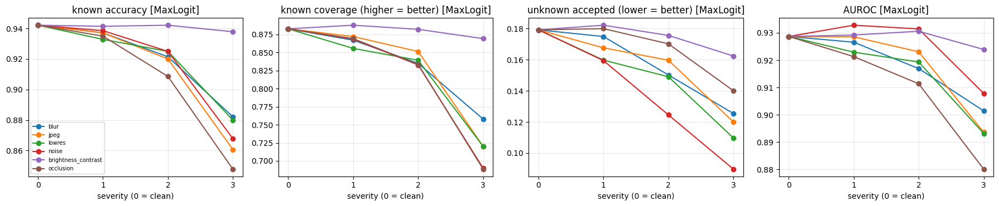

,corruption,severity,method,known_acc,coverage,selective_acc,FA_pooled,FA_macro,AUROC
0,clean,0,MaxLogit,0.9421,0.8829,0.9757,0.1548,0.1792,0.9287
1,blur,3,MaxLogit,0.8821,0.7579,0.9717,0.1119,0.1254,0.9015
2,jpeg,3,MaxLogit,0.8607,0.7200,0.9484,0.1063,0.1200,0.8937
3,lowres,3,MaxLogit,0.8800,0.7200,0.9742,0.0981,0.1097,0.8932
4,noise,3,MaxLogit,0.8679,0.6900,0.9524,0.0776,0.0897,0.9078
5,brightness_contrast,3,MaxLogit,0.9379,0.8693,0.9795,0.1402,0.1624,0.9239
6,occlusion,3,MaxLogit,0.8479,0.6886,0.9346,0.1205,0.1401,0.8801


In [24]:
tracker.begin("10 corruption study")
CORR = None
if RUN_CORRUPTION_STUDY and FINAL_EXPERIMENT in CTX:
    ctx = CTX[FINAL_EXPERIMENT]; fr = ctx.frames
    cap = lambda d: d.sample(min(CORR_MAX_PER_GROUP, len(d)), random_state=0) if len(d) else d
    cf = {"known_lab": cap(fr["known_test_lab"]).reset_index(drop=True), "known_field": cap(fr["known_test_field"]).reset_index(drop=True)}
    ut = fr["test_unknown"]
    cf["unknown"] = pd.concat([cap(ut[ut["scenario"] == s]) for s in SCEN_ORDER if (ut["scenario"] == s).any()], ignore_index=True)
    conds = [(None, 0)] + [(k, s) for k in CORRUPTION_KINDS for s in CORRUPTION_SEVERITIES]
    meths = [m for m in dict.fromkeys(["MSP", ctx.headline, "MSP+kNN"]) if m in ctx.thr]
    rows = []
    for kind, sev in tqdm(conds, desc="corruption conditions", dynamic_ncols=True):
        cor = None if kind is None else (kind, sev); A = {}
        for name, d in cf.items():
            if len(d) == 0: continue
            a = collect_arrays(ctx.model, d, corruption=cor, desc=f"{kind or 'clean'} {sev} {name}")
            score_dict = ctx.scorer.scores(a["L"], a["F"])
            if ctx.odin is not None:
                for mname, (ot, oe) in (("ODIN", (float(ctx.odin["T"]), float(ctx.odin["eps"]))), ("ODIN_canonical", tuple(map(float, ODIN_CANONICAL)))):
                    if mname in meths:
                        score_dict[mname] = odin_multi(ctx.model, d, [ot], [oe], desc=f"{mname} {kind or 'clean'} {sev} {name}", corruption=cor)[(ot, oe)]
            A[name] = (a, score_dict)
        for m in meths:
            thr = ctx.thr[m]; ks = [A[n][1][m] for n in ("known_lab", "known_field") if n in A]; kk = np.concatenate(ks)
            kc = np.concatenate([A[n][0]["L"].argmax(1) == A[n][0]["y"] for n in ("known_lab", "known_field") if n in A])
            us = A["unknown"][1][m]; usc = cf["unknown"]["scenario"].to_numpy()
            rows.append({"corruption": kind or "clean", "severity": sev, "method": m, "known_acc": float(kc.mean()), "coverage": float((kk <= thr).mean()),
                         "selective_acc": float(kc[kk <= thr].mean()) if (kk <= thr).any() else np.nan, "FA_pooled": float((us <= thr).mean()),
                         "FA_macro": float(np.mean([(us[usc == s] <= thr).mean() for s in SCEN_ORDER if (usc == s).any()])), "AUROC": fast_auroc(kk, us)})
    CORR = pd.DataFrame(rows); CORR.to_csv(TABLES / "corruption_study.csv", index=False)
    hm = ctx.headline; ch = CORR[CORR["method"] == hm]
    clean = ch[ch["corruption"] == "clean"].iloc[0]
    print(f"Clean reference ({hm}): accuracy {clean['known_acc']:.3f} | coverage {clean['coverage']:.3f} | FA macro {clean['FA_macro']:.3f} | AUROC {clean['AUROC']:.3f}")
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
    for ax, col, ttl in zip(axes, ["known_acc", "coverage", "FA_macro", "AUROC"], ["known accuracy", "known coverage (higher = better)", "unknown accepted (lower = better)", "AUROC"]):
        for k in CORRUPTION_KINDS:
            d = ch[ch["corruption"] == k].sort_values("severity")
            ax.plot([0] + d["severity"].tolist(), [clean[col]] + d[col].tolist(), "o-", label=k)
        ax.set_title(f"{ttl} [{hm}]"); ax.set_xlabel("severity (0 = clean)"); ax.grid(alpha=0.3); ax.set_xticks([0] + CORRUPTION_SEVERITIES)
    axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(FIGURES / "corruption_study.png", dpi=200, bbox_inches="tight"); plt.show()
    display(ch[ch["severity"].isin([0, max(CORRUPTION_SEVERITIES)])].round(4).reset_index(drop=True))
    tracker.end("10 corruption study", f"{len(conds)} conditions")
else:
    log("Corruption study skipped"); tracker.end("10 corruption study", "skipped")

## 15. Seed study (optional, long)
Set `RUN_SEED_STUDY = True` in the configuration. It re-trains `FINAL_EXPERIMENT` with the seeds in `SEED_STUDY_SEEDS`
(same data protocol) and reports mean ± standard deviation. Finished seeds are cached.

[05:27:42] [v5_3_B_mixed_tf_efficientnetv2_b0_s43_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[05:27:42] [v5_3_B_mixed_tf_efficientnetv2_b0_s43_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


B_mixed head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s43] head  1/2  | loss 1.313 acc 0.700 | val lab 0.9118 field 0.6906 | valNLL 0.4144 | lr 1.0e-03 | 210 img/s | 2m01s | ETA 26m17s  *best*


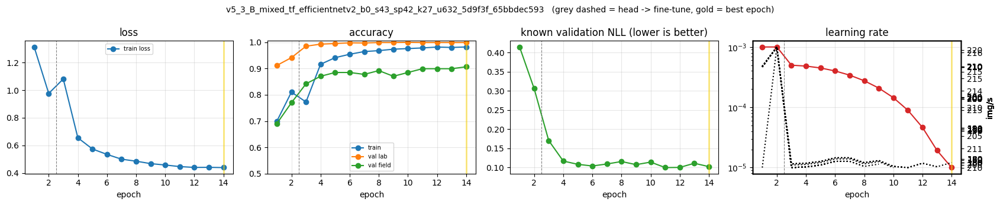

B_mixed head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s43] head  2/2  | loss 0.977 acc 0.810 | val lab 0.9414 field 0.7698 | valNLL 0.3058 | lr 1.0e-03 | 216 img/s | 1m56s | ETA 23m49s  *best*


B_mixed ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s43] ft    1/12 | loss 1.081 acc 0.773 | val lab 0.9849 field 0.8417 | valNLL 0.1704 | lr 5.0e-04 | 178 img/s | 2m21s | ETA 23m10s  *best*


B_mixed ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s43] ft    2/12 | loss 0.655 acc 0.916 | val lab 0.9927 field 0.8705 | valNLL 0.1169 | lr 4.8e-04 | 179 img/s | 2m20s | ETA 21m40s  *best*


... (37 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[06:13:28] [B_mixed] T pooled=0.635 balanced=0.769 (used 0.769) | threshold mode: pooled
[06:13:29] Headline method selected from validation data only: kNN
[06:13:29] Headline detector fixed in advance: MaxLogit (validation would have picked kNN; selection table is exported)
[06:17:11] [v5_3_B_mixed_tf_efficientnetv2_b0_s44_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[06:17:11] [v5_3_B_mixed_tf_efficientnetv2_b0_s44_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


B_mixed head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s44] head  1/2  | loss 1.308 acc 0.702 | val lab 0.9129 field 0.6691 | valNLL 0.4093 | lr 1.0e-03 | 220 img/s | 1m54s | ETA 24m52s  *best*


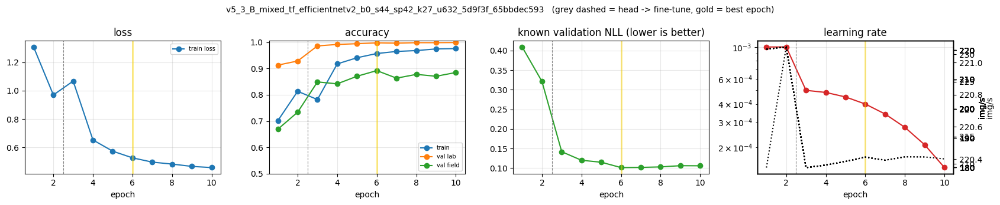

B_mixed head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s44] head  2/2  | loss 0.970 acc 0.813 | val lab 0.9286 field 0.7338 | valNLL 0.3214 | lr 1.0e-03 | 221 img/s | 1m54s | ETA 22m55s  *best*


B_mixed ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s44] ft    1/12 | loss 1.067 acc 0.782 | val lab 0.9860 field 0.8489 | valNLL 0.1419 | lr 5.0e-04 | 180 img/s | 2m19s | ETA 22m33s  *best*


B_mixed ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s44] ft    2/12 | loss 0.654 acc 0.918 | val lab 0.9916 field 0.8417 | valNLL 0.1201 | lr 4.8e-04 | 181 img/s | 2m19s | ETA 21m10s


... (28 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[06:55:22] [B_mixed] T pooled=0.651 balanced=0.806 (used 0.806) | threshold mode: pooled
[06:55:23] Headline method selected from validation data only: MSP+kNN
[06:55:23] Headline detector fixed in advance: MaxLogit (validation would have picked MSP+kNN; selection table is exported)
[06:55:24] [v5_3_B_mixed_tf_efficientnetv2_b0_s45_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[06:55:24] [v5_3_B_mixed_tf_efficientnetv2_b0_s45_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


B_mixed head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s45] head  1/2  | loss 1.305 acc 0.707 | val lab 0.9085 field 0.7266 | valNLL 0.4089 | lr 1.0e-03 | 209 img/s | 2m00s | ETA 26m08s  *best*


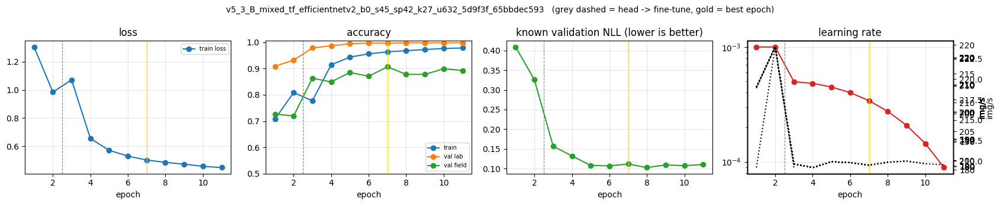

B_mixed head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s45] head  2/2  | loss 0.984 acc 0.808 | val lab 0.9319 field 0.7194 | valNLL 0.3256 | lr 1.0e-03 | 224 img/s | 1m53s | ETA 23m22s  *best*


B_mixed ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s45] ft    1/12 | loss 1.071 acc 0.777 | val lab 0.9782 field 0.8633 | valNLL 0.1570 | lr 5.0e-04 | 181 img/s | 2m19s | ETA 22m47s  *best*


B_mixed ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s45] ft    2/12 | loss 0.656 acc 0.914 | val lab 0.9866 field 0.8489 | valNLL 0.1324 | lr 4.8e-04 | 179 img/s | 2m20s | ETA 21m22s


... (30 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[07:34:43] [B_mixed] T pooled=0.656 balanced=0.816 (used 0.816) | threshold mode: pooled
[07:34:43] Headline method selected from validation data only: MSP+kNN
[07:34:43] Headline detector fixed in advance: MaxLogit (validation would have picked MSP+kNN; selection table is exported)
[07:36:05] [v5_3_B_mixed_tf_efficientnetv2_b0_s46_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[07:36:05] [v5_3_B_mixed_tf_efficientnetv2_b0_s46_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


B_mixed head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s46] head  1/2  | loss 1.306 acc 0.702 | val lab 0.9185 field 0.7050 | valNLL 0.3882 | lr 1.0e-03 | 202 img/s | 2m05s | ETA 27m09s  *best*


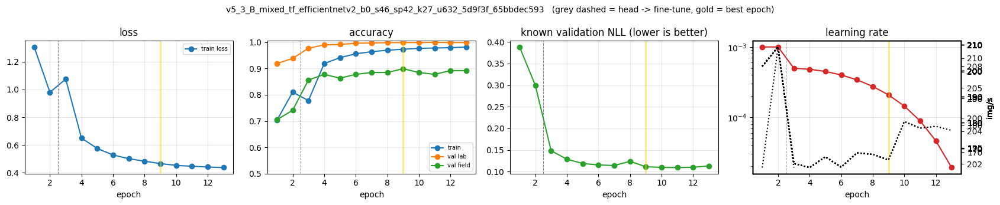

B_mixed head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s46] head  2/2  | loss 0.980 acc 0.810 | val lab 0.9386 field 0.7410 | valNLL 0.2994 | lr 1.0e-03 | 209 img/s | 2m01s | ETA 24m42s  *best*


B_mixed ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s46] ft    1/12 | loss 1.075 acc 0.778 | val lab 0.9771 field 0.8561 | valNLL 0.1484 | lr 5.0e-04 | 164 img/s | 2m32s | ETA 24m26s  *best*


B_mixed ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[B_mixed s46] ft    2/12 | loss 0.650 acc 0.919 | val lab 0.9900 field 0.8777 | valNLL 0.1288 | lr 4.8e-04 | 163 img/s | 2m34s | ETA 23m06s  *best*


... (34 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[08:23:15] [B_mixed] T pooled=0.643 balanced=0.777 (used 0.777) | threshold mode: pooled
[08:23:16] Headline method selected from validation data only: kNN
[08:23:16] Headline detector fixed in advance: MaxLogit (validation would have picked kNN; selection table is exported)
[08:23:38] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s43_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[08:23:38] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s43_sp42_k27_u632_5d9f3f_65bbdec593] outlier exposure: 5489 outlier images (3 disease classes, 4 background groups), lambda=0.5
[08:23:38] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s43_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


C_mixed_OE head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s43] head  1/2  | loss 3.197 acc 0.701 | val lab 0.8962 field 0.7050 | valNLL 0.5264 | lr 1.0e-03 | 137 img/s | 3m02s | ETA 39m29s  *best*


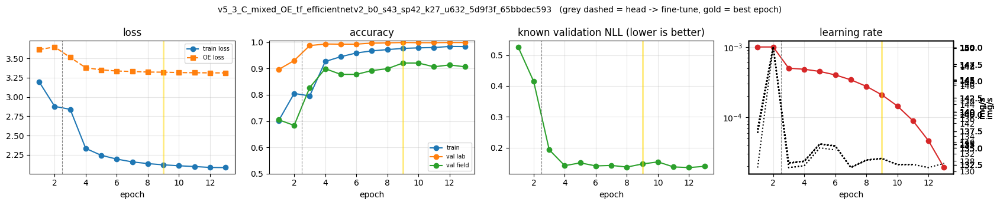

C_mixed_OE head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s43] head  2/2  | loss 2.878 acc 0.805 | val lab 0.9302 field 0.6835 | valNLL 0.4146 | lr 1.0e-03 | 150 img/s | 2m46s | ETA 34m54s  *best*


C_mixed_OE ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s43] ft    1/12 | loss 2.840 acc 0.796 | val lab 0.9872 field 0.8273 | valNLL 0.1930 | lr 5.0e-04 | 132 img/s | 3m09s | ETA 32m53s  *best*


C_mixed_OE ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s43] ft    2/12 | loss 2.333 acc 0.927 | val lab 0.9933 field 0.8993 | valNLL 0.1414 | lr 4.8e-04 | 132 img/s | 3m08s | ETA 30m17s  *best*


... (34 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[09:15:28] [C_mixed_OE] T pooled=0.543 balanced=0.660 (used 0.660) | threshold mode: pooled
[09:15:29] Headline method selected from validation data only: MSP+kNN
[09:15:29] Headline detector fixed in advance: MaxLogit (validation would have picked MSP+kNN; selection table is exported)
[09:17:51] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s44_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[09:17:51] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s44_sp42_k27_u632_5d9f3f_65bbdec593] outlier exposure: 5489 outlier images (3 disease classes, 4 background groups), lambda=0.5
[09:17:51] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s44_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


C_mixed_OE head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s44] head  1/2  | loss 3.192 acc 0.701 | val lab 0.9029 field 0.7122 | valNLL 0.5269 | lr 1.0e-03 | 149 img/s | 2m48s | ETA 36m31s  *best*


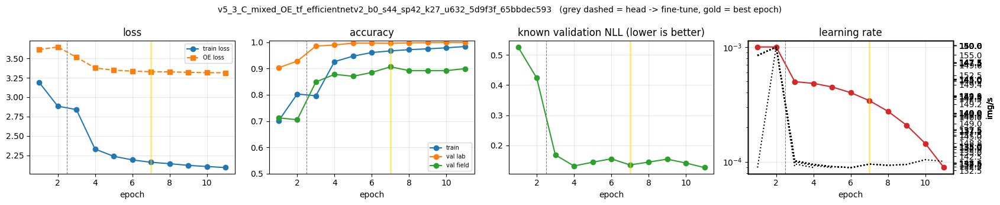

C_mixed_OE head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s44] head  2/2  | loss 2.884 acc 0.803 | val lab 0.9280 field 0.7050 | valNLL 0.4238 | lr 1.0e-03 | 150 img/s | 2m47s | ETA 33m34s  *best*


C_mixed_OE ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s44] ft    1/12 | loss 2.840 acc 0.796 | val lab 0.9855 field 0.8489 | valNLL 0.1678 | lr 5.0e-04 | 133 img/s | 3m07s | ETA 31m59s  *best*


C_mixed_OE ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s44] ft    2/12 | loss 2.330 acc 0.926 | val lab 0.9894 field 0.8777 | valNLL 0.1310 | lr 4.8e-04 | 132 img/s | 3m08s | ETA 29m40s  *best*


... (32 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[10:05:00] [C_mixed_OE] T pooled=0.551 balanced=0.662 (used 0.662) | threshold mode: pooled
[10:05:01] Headline method selected from validation data only: MaxLogit
[10:08:23] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s45_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[10:08:23] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s45_sp42_k27_u632_5d9f3f_65bbdec593] outlier exposure: 5489 outlier images (3 disease classes, 4 background groups), lambda=0.5
[10:08:23] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s45_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


C_mixed_OE head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s45] head  1/2  | loss 3.188 acc 0.702 | val lab 0.9096 field 0.7194 | valNLL 0.5193 | lr 1.0e-03 | 153 img/s | 2m44s | ETA 35m35s  *best*


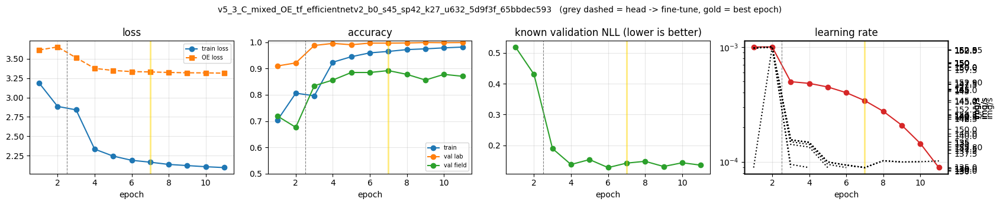

C_mixed_OE head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s45] head  2/2  | loss 2.885 acc 0.806 | val lab 0.9213 field 0.6763 | valNLL 0.4304 | lr 1.0e-03 | 153 img/s | 2m43s | ETA 32m47s


C_mixed_OE ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s45] ft    1/12 | loss 2.841 acc 0.796 | val lab 0.9877 field 0.8345 | valNLL 0.1893 | lr 5.0e-04 | 135 img/s | 3m04s | ETA 31m18s  *best*


C_mixed_OE ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s45] ft    2/12 | loss 2.334 acc 0.924 | val lab 0.9955 field 0.8561 | valNLL 0.1376 | lr 4.8e-04 | 135 img/s | 3m05s | ETA 29m03s  *best*


... (30 outputs left out)

ODIN test_unknown:   0%|          | 0/198 [00:00<?, ?it/s]

[10:57:34] [C_mixed_OE] T pooled=0.591 balanced=0.732 (used 0.732) | threshold mode: pooled
[10:57:35] Headline method selected from validation data only: MSP+kNN
[10:57:35] Headline detector fixed in advance: MaxLogit (validation would have picked MSP+kNN; selection table is exported)
[10:58:37] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s46_sp42_k27_u632_5d9f3f_65bbdec593] mixed-domain training: 23227 lab + 1256 field images, field share per epoch ~ 25%
[10:58:37] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s46_sp42_k27_u632_5d9f3f_65bbdec593] outlier exposure: 5489 outlier images (3 disease classes, 4 background groups), lambda=0.5
[10:58:37] [v5_3_C_mixed_OE_tf_efficientnetv2_b0_s46_sp42_k27_u632_5d9f3f_65bbdec593] training: 2 head + 12 fine-tune epochs, 1530 steps/epoch, batch 16


C_mixed_OE head 1/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s46] head  1/2  | loss 3.189 acc 0.704 | val lab 0.9096 field 0.6978 | valNLL 0.5160 | lr 1.0e-03 | 140 img/s | 2m59s | ETA 38m57s  *best*


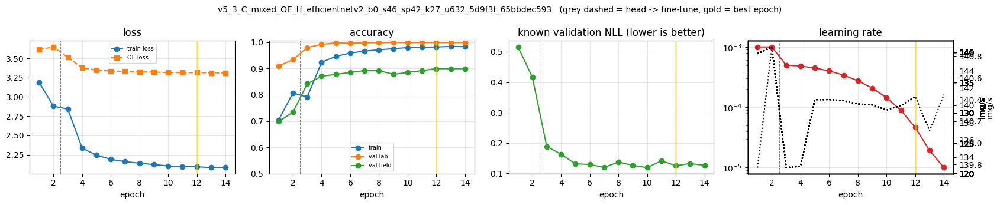

C_mixed_OE head 2/2:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s46] head  2/2  | loss 2.878 acc 0.807 | val lab 0.9336 field 0.7338 | valNLL 0.4160 | lr 1.0e-03 | 141 img/s | 2m57s | ETA 35m43s  *best*


C_mixed_OE ft 1/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s46] ft    1/12 | loss 2.842 acc 0.792 | val lab 0.9799 field 0.8417 | valNLL 0.1884 | lr 5.0e-04 | 121 img/s | 3m26s | ETA 34m25s  *best*


C_mixed_OE ft 2/12:   0%|          | 0/1530 [00:00<?, ?it/s]

[C_mixed_OE s46] ft    2/12 | loss 2.335 acc 0.924 | val lab 0.9916 field 0.8705 | valNLL 0.1628 | lr 4.8e-04 | 121 img/s | 3m25s | ETA 32m02s  *best*


... (37 outputs left out)

[11:59:30] [C_mixed_OE] T pooled=0.576 balanced=0.696 (used 0.696) | threshold mode: pooled
[11:59:31] Headline method selected from validation data only: MaxLogit


experiment                                   B_mixed  C_mixed_OE
T                                      mean   0.7815      0.6852
                                       std    0.0304      0.0300
acc_lab                                mean   0.9968      0.9962
                                       std    0.0014      0.0016
acc_field                              mean   0.8821      0.8856
...                                              ...         ...
MaxLogit@val_youden_FA@background_real std    0.0351      0.0008
domain_gap_AUROC_MSP                   mean   0.6736      0.6397
                                       std    0.0387      0.0293
domain_gap_AUROC_HEAD                  mean   0.7982      0.6878
                                       std    0.0386      0.0368

[164 rows x 2 columns]

Paired OE effect (C - B, same seed):


,detector,metric,n_seeds,mean_C_minus_B,std,seeds_where_OE_better
0,MSP,macroAUROC,5,0.0239,0.0392,3
1,MSP,FA_macro,5,-0.0373,0.0438,4
2,MSP,FA@unseen_disease,5,-0.0068,0.0402,3
3,MSP,FA@cross_domain_novel,5,-0.0756,0.1204,3
4,MSP,FA@background_real,5,-0.0482,0.0209,5
5,MaxLogit,macroAUROC,5,0.0261,0.0390,3
6,MaxLogit,FA_macro,5,-0.0480,0.0369,4
7,MaxLogit,FA@unseen_disease,5,-0.0487,0.0163,5
8,MaxLogit,FA@cross_domain_novel,5,-0.0875,0.1022,4
9,MaxLogit,FA@background_real,5,-0.0519,0.0290,5


In [25]:
tracker.begin("11 seed study")
SEEDS_TAB, OE_EFF = None, None

def oe_effect_table(tab, detectors, exp_b="B_mixed", exp_c="C_mixed_OE"):
    """Paired (same seed) C - B differences for fixed detectors. Negative FA / positive AUROC = OE helps."""
    b, c = tab[tab["experiment"] == exp_b].set_index("seed"), tab[tab["experiment"] == exp_c].set_index("seed")
    seeds = sorted(set(b.index) & set(c.index)); rows = []
    for m in detectors:
        for col, better in ((f"{m}_macroAUROC", "up"), (f"{m}_FA_macro", "down"), (f"{m}_FA@unseen_disease", "down"), (f"{m}_FA@cross_domain_novel", "down"), (f"{m}_FA@background_real", "down")):
            if col not in b.columns or col not in c.columns: continue
            d = (c.loc[seeds, col] - b.loc[seeds, col]).astype(float)
            rows.append({"detector": m, "metric": col[len(m) + 1:], "n_seeds": len(seeds), "mean_C_minus_B": d.mean(), "std": d.std(ddof=1) if len(d) > 1 else np.nan,
                         "seeds_where_OE_better": int((d > 0).sum() if better == "up" else (d < 0).sum())})
    return pd.DataFrame(rows)

if RUN_SEED_STUDY and any(e in CTX for e in SEED_STUDY_EXPERIMENTS):
    rows = []
    for e in SEED_STUDY_EXPERIMENTS:
        if e not in CTX: continue
        rows.append(RES[e]["summary"].iloc[0].to_dict())
        for sd in SEED_STUDY_SEEDS:
            m_, h_, rn_ = train_one_run(e, sd)
            c_ = build_context(e, m_, get_frames(EXPERIMENTS[e]["mix_field"]), rn_, sd)
            r_ = evaluate(c_, EXP_DIR / f"{e}_s{sd}", light=True)
            rows.append(r_["summary"].iloc[0].to_dict())
            del m_, c_; torch.cuda.empty_cache()
    SEEDS_TAB = pd.DataFrame(rows); SEEDS_TAB.to_csv(TABLES / "seed_study.csv", index=False)
    num_cols = [c for c in SEEDS_TAB.select_dtypes("number").columns if c != "seed"]
    display(SEEDS_TAB.groupby("experiment")[num_cols].agg(["mean", "std"]).T.round(4))
    if {"B_mixed", "C_mixed_OE"} <= set(SEEDS_TAB["experiment"]):
        OE_EFF = oe_effect_table(SEEDS_TAB, FIXED_DETECTORS); OE_EFF.to_csv(TABLES / "oe_effect_by_seed.csv", index=False)
        print("Paired OE effect (C - B, same seed):"); display(OE_EFF.round(4))
    tracker.end("11 seed study", f"{len(SEEDS_TAB)} runs")
else:
    log("Seed study skipped (RUN_SEED_STUDY=0)"); tracker.end("11 seed study", "skipped")


## 16. Figures for the final experiment

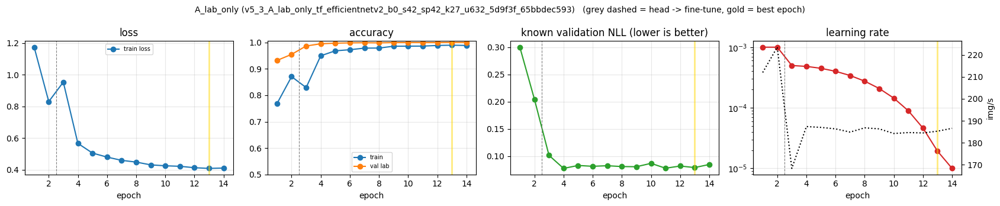

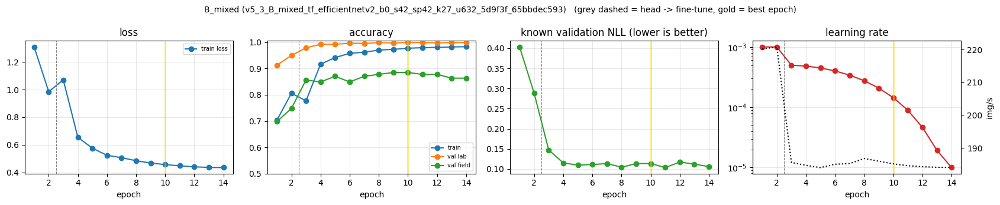

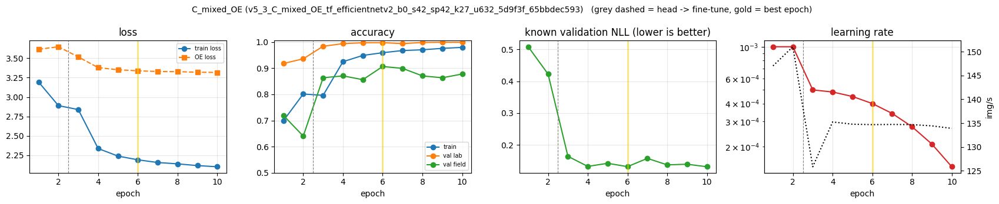

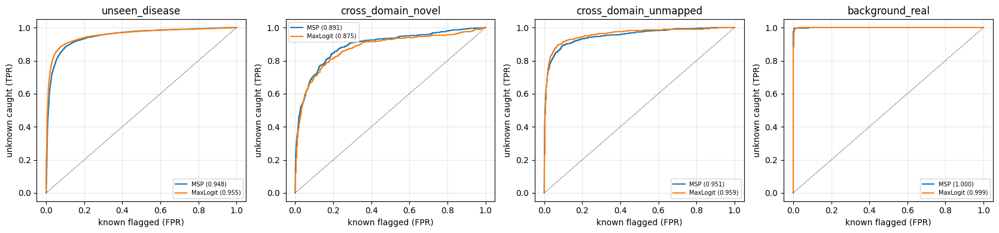

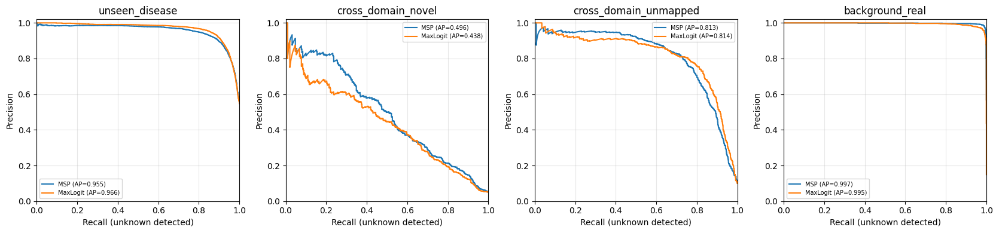

...

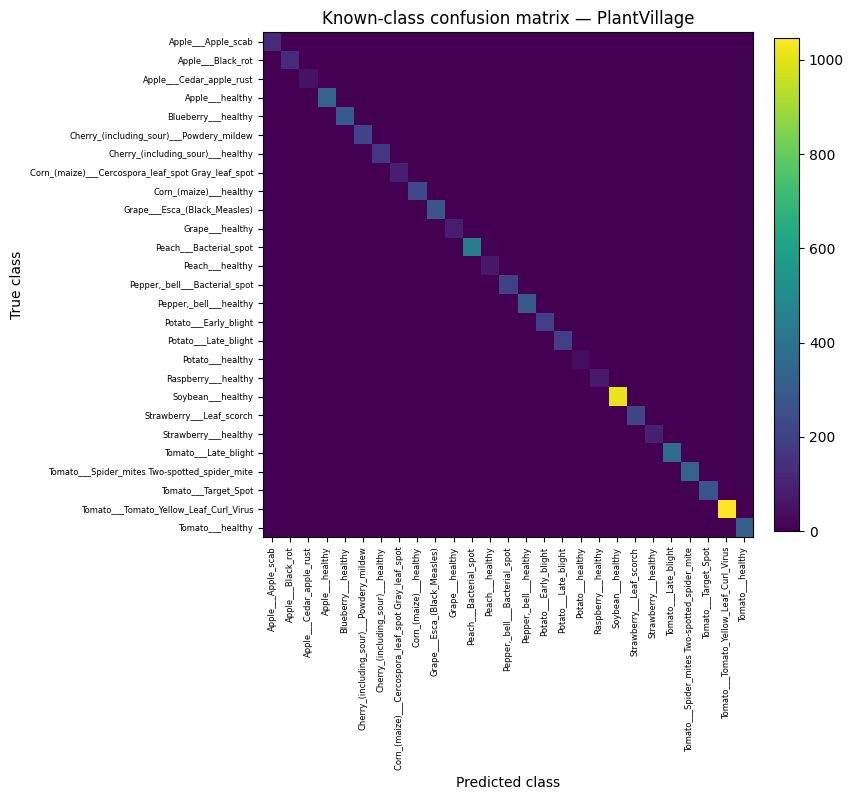

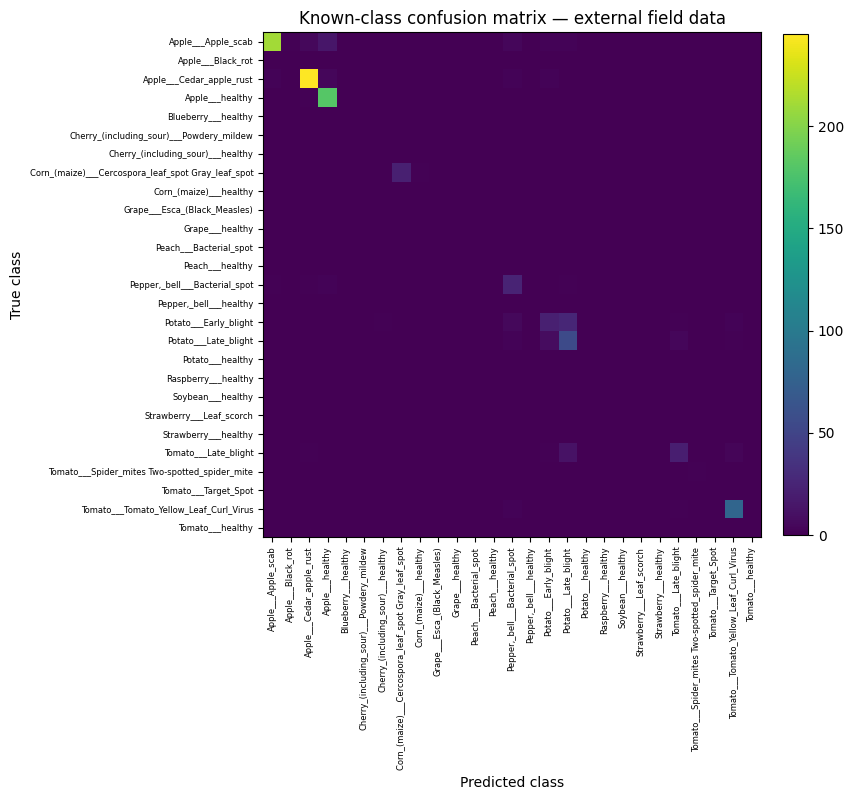

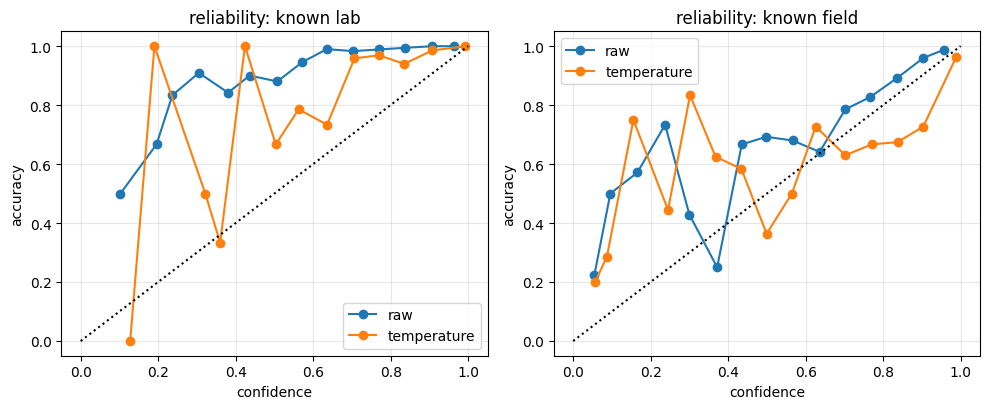

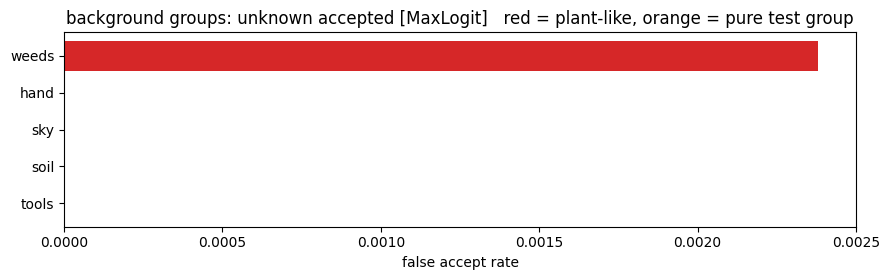

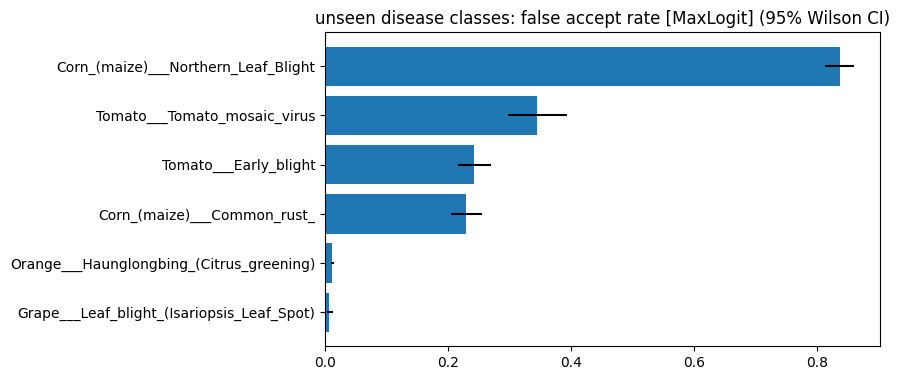

,group,n,false_accepted,FA_rate,FA_lo,FA_hi
10,Corn_(maize)___Northern_Leaf_Blight,982,823,0.8381,0.8137,0.8598
14,Tomato___Tomato_mosaic_virus,369,127,0.3442,0.2975,0.3940
13,Tomato___Early_blight,987,239,0.2421,0.2165,0.2698
9,Corn_(maize)___Common_rust_,1057,242,0.2289,0.2046,0.2552
12,Orange___Haunglongbing_(Citrus_greening),5403,62,0.0115,0.0090,0.0147
11,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),1072,6,0.0056,0.0026,0.0122


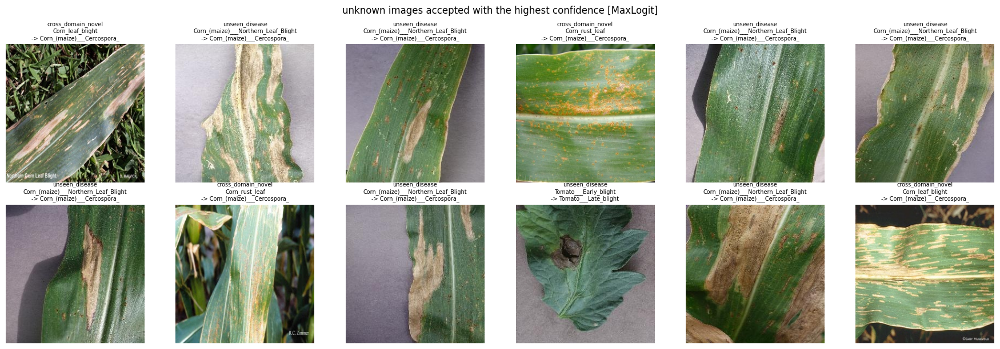

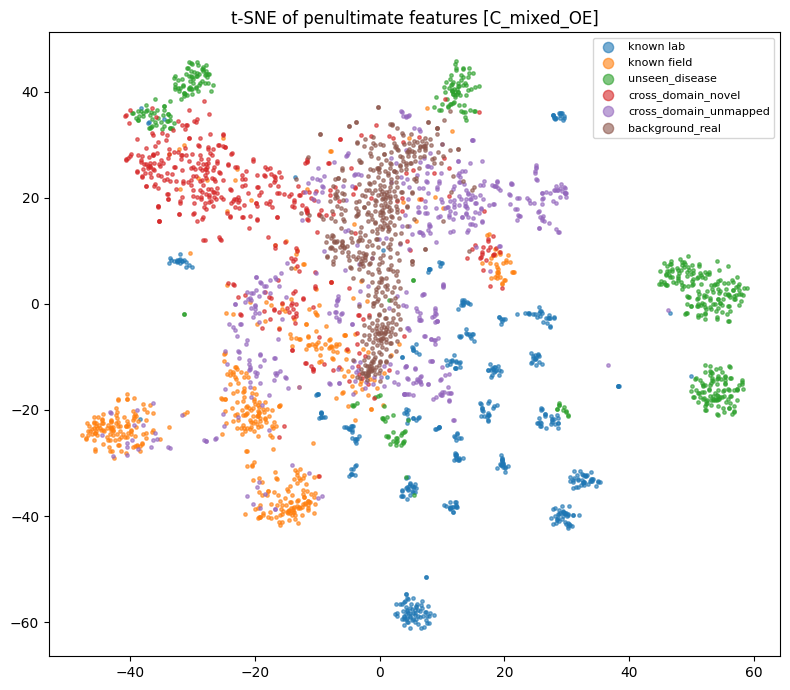

In [26]:
tracker.begin("12 figures")
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
if FINAL_EXPERIMENT in CTX:
    ctx = CTX[FINAL_EXPERIMENT]; R = RES[FINAL_EXPERIMENT]; hm = ctx.headline
    u_frame = ctx.frames["test_unknown"].reset_index(drop=True); u_scen = u_frame["scenario"].to_numpy()
    scen_present = [s for s in SCEN_ORDER if (u_scen == s).any()]
    savefig = lambda fig, name: fig.savefig(FIGURES / name, dpi=200, bbox_inches="tight")

    # 1. training curves of every run
    for e, r in RUNS.items():
        if len(r["hist"]): LivePlot(f"{e} ({r['run_name']})").update(r["hist"].to_dict("records"), best_epoch=int(r["hist"].loc[r["hist"]["crit"].idxmax(), "global_epoch"]))

    # 2. ROC per scenario (known_all vs scenario)
    fig, axes = plt.subplots(1, len(scen_present), figsize=(4.2 * len(scen_present), 4), squeeze=False)
    for ax, sc in zip(axes[0], scen_present):
        for m in dict.fromkeys(["MSP", hm]):
            ks = known_all(ctx, m); us = ctx.S["test_unknown"][m][u_scen == sc]
            fpr, tpr, _ = roc_curve(np.r_[np.zeros(len(ks)), np.ones(len(us))], np.r_[ks, us]); ax.plot(fpr, tpr, label=f"{m} ({fast_auroc(ks, us):.3f})")
        ax.plot([0, 1], [0, 1], "k:", lw=0.8); ax.set_title(sc); ax.set_xlabel("known flagged (FPR)"); ax.set_ylabel("unknown caught (TPR)"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    fig.tight_layout(); savefig(fig, "roc_by_scenario.png"); plt.show()

    # 2b. Precision-recall curves (unknown/OOD is the positive class), reported per scenario.
    fig, axes = plt.subplots(1, len(scen_present), figsize=(4.2 * len(scen_present), 4), squeeze=False)
    for ax, sc in zip(axes[0], scen_present):
        for m in dict.fromkeys(["MSP", hm]):
            ks = known_all(ctx, m); us = ctx.S["test_unknown"][m][u_scen == sc]
            y_true = np.r_[np.zeros(len(ks), dtype=int), np.ones(len(us), dtype=int)]
            score = np.r_[ks, us]
            precision, recall, _ = precision_recall_curve(y_true, score)
            ap = average_precision_score(y_true, score)
            ax.plot(recall, precision, label=f"{m} (AP={ap:.3f})")
        ax.set_title(sc); ax.set_xlabel("Recall (unknown detected)"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
    fig.tight_layout(); savefig(fig, "precision_recall_by_scenario.png"); plt.show()

    # 3. score distributions with the operating threshold
    fig, ax = plt.subplots(figsize=(10, 4)); sc_all = np.concatenate([known_all(ctx, hm), ctx.S["test_unknown"][hm]])
    bins = np.linspace(np.percentile(sc_all, 0.5), np.percentile(sc_all, 99.5), 70)
    ax.hist(ctx.S["known_test_lab"][hm], bins=bins, alpha=0.5, density=True, label="known lab")
    if len(ctx.S["known_test_field"][hm]): ax.hist(ctx.S["known_test_field"][hm], bins=bins, alpha=0.5, density=True, label="known field")
    for sc in scen_present: ax.hist(ctx.S["test_unknown"][hm][u_scen == sc], bins=bins, histtype="step", lw=1.6, density=True, label=sc)
    ax.axvline(ctx.thr[hm], color="k", ls="--", label="threshold"); ax.set_title(f"{hm} score (higher = more unknown)"); ax.legend(fontsize=7); fig.tight_layout(); savefig(fig, "score_distributions.png"); plt.show()

    # 3b. Risk-coverage plot: coverage is the fraction of known images accepted; risk is the error rate among accepted images.
    rc_table = R.get("risk_coverage", pd.DataFrame())
    aurc_table = R.get("aurc", pd.DataFrame())
    if len(rc_table):
        fig, ax = plt.subplots(figsize=(7.5, 5))
        for m in dict.fromkeys(["MSP", hm]):
            d = rc_table[rc_table["method"] == m].sort_values("coverage")
            ar = aurc_table.loc[aurc_table["method"] == m, "AURC"]
            label = f"{m}" + (f" (AURC={float(ar.iloc[0]):.4f})" if len(ar) else "")
            ax.plot(d["coverage"], d["risk"], label=label)
        ax.set_xlabel("Coverage of known test images"); ax.set_ylabel("Selective risk (1 - accuracy among accepted)")
        ax.set_title("Selective prediction: risk versus coverage"); ax.set_xlim(0, 1); ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3); ax.legend(); fig.tight_layout(); savefig(fig, "risk_coverage.png"); plt.show()

    # 3c. Confusion matrices for known lab and known field test data.
    for key, title, filename in [("confusion_matrix_lab", "Known-class confusion matrix — PlantVillage", "confusion_matrix_lab.png"),
                                 ("confusion_matrix_field", "Known-class confusion matrix — external field data", "confusion_matrix_field.png")]:
        cm_df = R.get(key, pd.DataFrame())
        if len(cm_df):
            labels = cm_df["true_class"].astype(str).tolist()
            cm = cm_df.drop(columns=["true_class"]).to_numpy()
            fig, ax = plt.subplots(figsize=(max(8, 0.32 * len(labels)), max(7, 0.30 * len(labels))))
            im = ax.imshow(cm, interpolation="nearest", aspect="auto")
            ax.set_title(title); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
            ax.set_xticks(np.arange(len(labels))); ax.set_yticks(np.arange(len(labels)))
            ax.set_xticklabels(labels, rotation=90, fontsize=6); ax.set_yticklabels(labels, fontsize=6)
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); fig.tight_layout(); savefig(fig, filename); plt.show()

    # 4. reliability diagrams, lab vs field
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, (dom, p) in zip(axes, [("lab", ctx.pools["known_test_lab"]), ("field", ctx.pools["known_test_field"])]):
        if len(p["y"]) == 0: ax.axis("off"); continue
        for nm, pp in [("raw", softmax_np(p["L"])), ("temperature", probs_T(p["L"], ctx.T))]:
            c = calib_curve(pp, p["y"]); ax.plot(c["confidence"], c["accuracy"], "o-", label=nm)
        ax.plot([0, 1], [0, 1], "k:"); ax.set_title(f"reliability: known {dom}"); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(); ax.grid(alpha=0.3)
    fig.tight_layout(); savefig(fig, "reliability_lab_vs_field.png"); plt.show()

    # 5. false accepts by background group and by unseen class
    fa = R["false_accept"]; fa = fa[fa["method"] == hm]
    bgt = fa[fa["kind"] == "bg_group"].sort_values("FA_rate", ascending=False)
    if len(bgt):
        top = bgt.head(25); col = ["tab:red" if b else ("tab:orange" if p else "tab:blue") for b, p in zip(top["plant_like"], top["pure_test_group"])]
        fig, ax = plt.subplots(figsize=(9, 0.28 * len(top) + 1.5)); ax.barh(top["group"][::-1], top["FA_rate"][::-1], color=col[::-1])
        ax.set_title(f"background groups: unknown accepted [{hm}]   red = plant-like, orange = pure test group"); ax.set_xlabel("false accept rate")
        fig.tight_layout(); savefig(fig, "false_accept_background_groups.png"); plt.show()
    uct = fa[fa["kind"] == "unseen_class"].sort_values("FA_rate", ascending=False)
    if len(uct):
        fig, ax = plt.subplots(figsize=(9, 0.4 * len(uct) + 1.5)); ax.barh(uct["group"][::-1], uct["FA_rate"][::-1], xerr=[(uct["FA_rate"] - uct["FA_lo"])[::-1], (uct["FA_hi"] - uct["FA_rate"])[::-1]])
        ax.set_title(f"unseen disease classes: false accept rate [{hm}] (95% Wilson CI)"); fig.tight_layout(); savefig(fig, "false_accept_unseen_classes.png"); plt.show()
        display(uct[["group", "n", "false_accepted", "FA_rate", "FA_lo", "FA_hi"]].round(4))

    # 6. most dangerous false accepts: the unknown images the detector is MOST sure are known
    thr = ctx.thr[hm]; sc_u = ctx.S["test_unknown"][hm]; pred_u = ctx.pools["test_unknown"]["L"].argmax(1)
    order = [i for i in np.argsort(sc_u) if sc_u[i] <= thr][:12]
    if order:
        fig, axes = plt.subplots(2, 6, figsize=(18, 6.2))
        for ax, i in zip(axes.ravel(), order):
            ax.imshow(Image.open(u_frame.loc[i, "load_path"]).convert("RGB")); ax.axis("off")
            ax.set_title(f"{u_scen[i]}\n{u_frame.loc[i, 'bg_group'] or u_frame.loc[i, 'unseen_class'] or u_frame.loc[i, 'label']}\n-> {idx_to_class[int(pred_u[i])][:26]}", fontsize=7)
        for ax in axes.ravel()[len(order):]: ax.axis("off")
        fig.suptitle(f"unknown images accepted with the highest confidence [{hm}]"); fig.tight_layout(); savefig(fig, "worst_false_accepts.png"); plt.show()

    # 7. t-SNE: does the model still separate lab / field / unknown by STYLE?
    if RUN_TSNE:
        from sklearn.manifold import TSNE
        rs = np.random.default_rng(0); parts = []
        for nm, Fm, lab_ in [("known lab", ctx.pools["known_test_lab"]["F"], "known lab"), ("known field", ctx.pools["known_test_field"]["F"], "known field")] + \
                            [(sc, ctx.pools["test_unknown"]["F"][u_scen == sc], sc) for sc in scen_present]:
            if len(Fm): parts.append((lab_, Fm[rs.choice(len(Fm), min(len(Fm), TSNE_MAX_POINTS // 6), replace=False)]))
        X = np.concatenate([p[1] for p in parts]); lab_arr = np.concatenate([[p[0]] * len(p[1]) for p in parts])
        emb = TSNE(n_components=2, init="pca", perplexity=min(30, max(5, len(X) // 10)), random_state=0).fit_transform(X)
        fig, ax = plt.subplots(figsize=(8, 7))
        for nm in dict.fromkeys(lab_arr): ax.scatter(*emb[lab_arr == nm].T, s=6, label=nm, alpha=0.6)
        ax.legend(markerscale=3, fontsize=8); ax.set_title(f"t-SNE of penultimate features [{FINAL_EXPERIMENT}]"); fig.tight_layout(); savefig(fig, "tsne_features.png"); plt.show()
tracker.end("12 figures")

## 17. Deployable bundle and a live demo
`final_bundle.pt` contains the weights, class list, calibration temperature, detector statistics and thresholds.
`OpenSetPredictor.predict(path)` returns **known** (with class and confidence) or **reject** (with the reason score) for a single photo.

[12:02:16] Bundle saved: /kaggle/working/plant_openset_project/results/split42/final_bundle.pt (105 MB) | decision method: MaxLogit


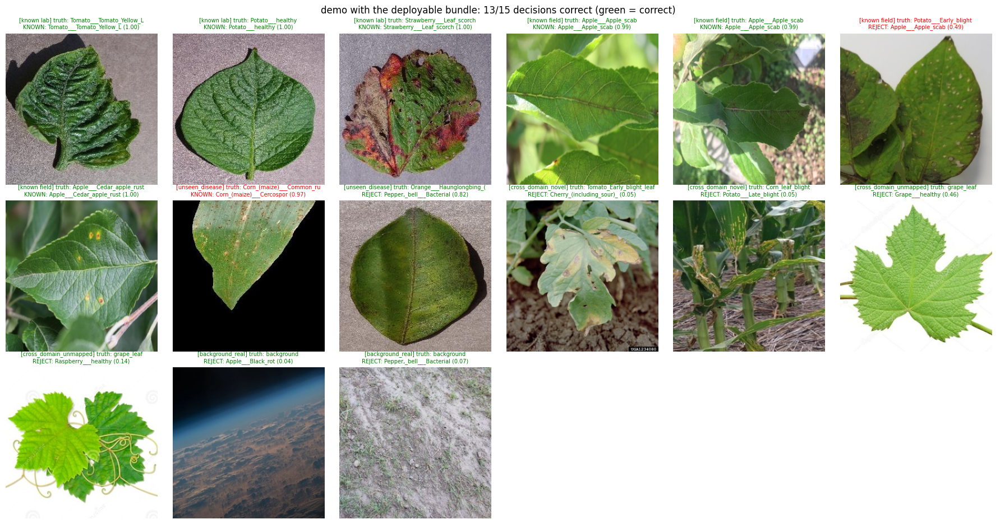

In [27]:
tracker.begin("13 deployable bundle + demo")
BUNDLE_METHODS = ["MSP", "Entropy", "Energy", "MaxLogit", "kNN", "Mahalanobis", "MSP+kNN", "MSP+Maha", "OpenMax", "ODIN"]
class OpenSetPredictor:
    def __init__(self, bundle_path, device=None):
        b = torch.load(bundle_path, map_location="cpu", weights_only=False)
        self.device = device or DEVICE; self.classes = b["classes"]; self.method = b["method"]; self.thr = b["thr"][self.method]
        self.model = build_model(b["backbone"], len(self.classes), pretrained=False); self.model.load_state_dict(b["state_dict"]); self.model.to(self.device).eval()
        self.scorer = OODScorer.from_state(b["scorer"]); self.size = b["image_size"]; self.tfm = build_eval_tfms(self.size); self.cache_size = b["cache_size"]
        self.odin = b.get("odin")
        if self.method == "ODIN" and not self.odin:
            raise ValueError("The bundle selected ODIN but does not contain tuned ODIN parameters.")
    def predict(self, image):
        img = Image.open(image).convert("RGB") if not isinstance(image, Image.Image) else image.convert("RGB")
        img = img.resize((self.cache_size, self.cache_size), Image.BICUBIC)
        x = self.tfm(img).unsqueeze(0).to(self.device)
        if self.method == "ODIN":
            # ODIN requires gradients for its input perturbation; do not wrap this branch in no_grad.
            t_odin = float(self.odin["T"]); eps = float(self.odin["eps"])
            xg = x.detach().requires_grad_(True)
            logits = self.model(xg)
            loss = F.cross_entropy(logits / t_odin, logits.argmax(1))
            grad = torch.autograd.grad(loss, xg, retain_graph=False)[0].sign()
            std = torch.tensor(IMAGENET_STD, device=self.device).view(1, 3, 1, 1)
            with torch.no_grad():
                odin_logits = self.model((xg - eps * grad / std).detach()) if eps > 0 else logits.detach()
                score = float((1.0 - F.softmax(odin_logits.float() / t_odin, dim=1).max(1).values).cpu().item())
                f = self.model.forward_features(x)
                calibrated_p = probs_T(logits.detach().float().cpu().numpy(), self.scorer.T)[0]
                l_np, f_np = logits.detach().float().cpu().numpy(), f.float().cpu().numpy()
        else:
            with torch.no_grad():
                f = self.model.forward_features(x); logits = self.model.classifier_head(f)
                l_np, f_np = logits.float().cpu().numpy(), f.float().cpu().numpy()
                score = float(self.scorer.scores(l_np, f_np)[self.method][0])
                calibrated_p = probs_T(l_np, self.scorer.T)[0]
        top = np.argsort(-calibrated_p)[:3]
        return {"decision": "known" if score <= self.thr else "reject", "class": self.classes[int(top[0])], "confidence": float(calibrated_p[top[0]]),
                "unknown_score": score, "threshold": self.thr, "method": self.method, "top3": [(self.classes[int(i)], float(calibrated_p[i])) for i in top]}

if FINAL_EXPERIMENT in CTX:
    ctx = CTX[FINAL_EXPERIMENT]
    method = ctx.headline if ctx.headline in BUNDLE_METHODS and ctx.headline in ctx.thr else "MSP+kNN"
    if method not in ctx.thr: raise RuntimeError(f"No deployment threshold was calibrated for the selected method: {ctx.headline}")
    bundle_path = RESULTS / "final_bundle.pt"
    torch.save({"state_dict": ctx.model.state_dict(), "backbone": BACKBONE, "classes": known_classes, "image_size": IMAGE_SIZE, "cache_size": CACHE_SIZE,
                "scorer": ctx.scorer.state(), "method": method, "thr": {k: v for k, v in ctx.thr.items() if k in BUNDLE_METHODS}, "odin": ctx.odin, "split_tag": SPLIT_TAG,
                "experiment": FINAL_EXPERIMENT, "run_name": ctx.run_name}, bundle_path)
    log(f"Bundle saved: {bundle_path} ({bundle_path.stat().st_size / 1e6:.0f} MB) | decision method: {method}")
    predictor = OpenSetPredictor(bundle_path)
    rs = np.random.default_rng(1); picks = []
    for nm, fr_, k in [("known lab", ctx.frames["known_test_lab"], 3), ("known field", ctx.frames["known_test_field"], 4)] + \
                       [(s, ctx.frames["test_unknown"][ctx.frames["test_unknown"]["scenario"] == s], 2) for s in SCEN_ORDER]:
        if len(fr_): picks += [(nm, r) for _, r in fr_.sample(min(k, len(fr_)), random_state=int(rs.integers(1e6))).iterrows()]
    fig, axes = plt.subplots(3, 6, figsize=(18, 9.5)); right = 0
    for ax, (nm, r) in zip(axes.ravel(), picks):
        out = predictor.predict(r["orig_path"]); is_known = nm.startswith("known")
        ok = (out["decision"] == "known" and is_known and out["class"] == r["label_eval"]) or (out["decision"] == "reject" and not is_known)
        right += ok; ax.imshow(Image.open(r["load_path"]).convert("RGB")); ax.axis("off")
        ax.set_title(f"[{nm}] truth: {(r['label_eval'] or r['label'])[:24]}\n{out['decision'].upper()}: {out['class'][:24]} ({out['confidence']:.2f})", fontsize=7, color="green" if ok else "red")
    for ax in axes.ravel()[len(picks):]: ax.axis("off")
    fig.suptitle(f"demo with the deployable bundle: {right}/{len(picks)} decisions correct (green = correct)"); fig.tight_layout(); savefig(fig, "demo_predictions.png"); plt.show()
tracker.end("13 deployable bundle + demo")

## 18. Claims check, export, manifest
Automatic pass / fail against explicit thresholds. Edit the thresholds if you want a stricter or looser standard; a **NOT TESTED** is not a pass.

In [28]:
tracker.begin("14 claims check + export")
# NOTE: these are internal target values chosen by the author, not community standards; say so in the paper.
TH = dict(acc_lab=0.99, acc_field=0.85, field_cov_min=0.80, cov_gap_max=0.10, domain_gap_max=0.75,
          FA_unseen=0.10, FA_novel=0.10, FA_unmapped=0.10, FA_bg_texture=0.02, FA_bg_real=0.05,
          corr_cov_drop=0.15, seed_std=0.01, n_unseen_test=6)
claims = []
def claim(name, value, ok, thr):
    claims.append({"claim": name, "value": value if isinstance(value, str) else (round(float(value), 4) if value == value else np.nan), "needs": thr,
                   "status": "NOT TESTED" if ok is None else ("PASS" if ok else "FAIL")})
if FINAL_EXPERIMENT in RES:
    s = RES[FINAL_EXPERIMENT]["summary"].iloc[0]
    claim("protocol: no cluster spans train-like and test roles", "asserted in role assignment", PROTOCOL_OK, "must hold")
    claim("enough unseen-disease test classes", len(unseen_test), len(unseen_test) >= TH["n_unseen_test"], f">= {TH['n_unseen_test']}")
    claim("outlier exposure was actually used", int(len(get_frames(True)["oe_train"])), EXPERIMENTS[FINAL_EXPERIMENT]["oe"] and len(get_frames(True)["oe_train"]) > 0, "OE images > 0")
    claim("known accuracy, lab images", s["acc_lab"], s["acc_lab"] >= TH["acc_lab"], f">= {TH['acc_lab']}")
    claim("known accuracy, FIELD images", s["acc_field"], s["acc_field"] >= TH["acc_field"] if s["acc_field"] == s["acc_field"] else None, f">= {TH['acc_field']}")
    claim("field coverage at threshold", s["HEAD_cov_field"], s["HEAD_cov_field"] >= TH["field_cov_min"] if s["HEAD_cov_field"] == s["HEAD_cov_field"] else None, f">= {TH['field_cov_min']}")
    claim("coverage gap lab vs field", abs(s["HEAD_cov_lab"] - s["HEAD_cov_field"]), abs(s["HEAD_cov_lab"] - s["HEAD_cov_field"]) <= TH["cov_gap_max"] if s["HEAD_cov_field"] == s["HEAD_cov_field"] else None, f"<= {TH['cov_gap_max']}")
    if "domain_gap_AUROC_HEAD" in s: claim("domain-gap AUROC (0.5 = style invisible)", s["domain_gap_AUROC_HEAD"], s["domain_gap_AUROC_HEAD"] <= TH["domain_gap_max"], f"<= {TH['domain_gap_max']}")
    for sc, key in [("unseen_disease", "FA_unseen"), ("cross_domain_novel", "FA_novel"),
                    ("cross_domain_unmapped", "FA_unmapped"), ("background_texture", "FA_bg_texture"),
                    ("background_real", "FA_bg_real")]:
        v = s.get(f"HEAD_FA@{sc}", np.nan); claim(f"false accept: {sc}", v, (v <= TH[key]) if v == v else None, f"<= {TH[key]}")
    if "A_lab_only" in RES and "B_mixed" in RES:
        a, b = RES["A_lab_only"]["summary"].iloc[0], RES["B_mixed"]["summary"].iloc[0]
        claim("field training raises field accuracy (B - A)", b["acc_field"] - a["acc_field"], (b["acc_field"] - a["acc_field"]) > 0.10, "> +0.10")
    if "B_mixed" in RES and "C_mixed_OE" in RES:
        ob_, oc_ = RES["B_mixed"]["operating"].set_index("method"), RES["C_mixed_OE"]["operating"].set_index("method")
        for _m in ("MSP", "MaxLogit"):      # SAME detector in B and C (headline detectors differ between experiments)
            if _m in ob_.index and _m in oc_.index:
                d_ = float(oc_.loc[_m, "FA_macro"] - ob_.loc[_m, "FA_macro"])
                claim(f"OE lowers macro false-accept, same detector {_m} (C - B)", d_, d_ < 0, "< 0")
    if CORR is not None:
        ch = CORR[(CORR["method"] == CTX[FINAL_EXPERIMENT].headline)]; cl = ch[ch["corruption"] == "clean"]["coverage"].iloc[0]
        worst = (cl - ch[ch["severity"] == max(CORRUPTION_SEVERITIES)]["coverage"]).max()
        claim("coverage drop under worst severity-3 corruption", worst, worst <= TH["corr_cov_drop"], f"<= {TH['corr_cov_drop']}")
    else:
        claim("corruption robustness", "not run", None, "")
    if SEEDS_TAB is not None and len(SEEDS_TAB) > 1:
        _st = SEEDS_TAB[SEEDS_TAB["experiment"] == FINAL_EXPERIMENT]
        sd = _st["HEAD_macroAUROC"].std(ddof=1); claim(f"seed stability: std of macro AUROC (headline, {FINAL_EXPERIMENT})", sd, sd <= TH["seed_std"], f"<= {TH['seed_std']}")
        sd_msp = _st["MSP_macroAUROC"].std(ddof=1)
        claim("seed stability: std of macro AUROC (fixed detector MSP)", sd_msp, sd_msp <= TH["seed_std"], f"<= {TH['seed_std']}")
        if OE_EFF is not None:
            for _m in FIXED_DETECTORS:
                _r = OE_EFF[(OE_EFF["detector"] == _m) & (OE_EFF["metric"] == "FA@unseen_disease")]
                if len(_r): claim(f"OE lowers unseen-disease false-accept, paired over seeds ({_m})", float(_r["mean_C_minus_B"].iloc[0]), float(_r["mean_C_minus_B"].iloc[0]) < 0 and int(_r["seeds_where_OE_better"].iloc[0]) == int(_r["n_seeds"].iloc[0]), "mean < 0 in every seed")
    else:
        claim("seed stability", "not run", None, "")
claims_df = pd.DataFrame(claims); claims_df.to_csv(TABLES / "claims_check.csv", index=False)
display(claims_df)
print(claims_df["status"].value_counts().to_dict())

# ---- Excel export of everything ----
xlsx = RESULTS / "all_results_v7.xlsx"
with pd.ExcelWriter(xlsx, engine="openpyxl") as xw:
    claims_df.to_excel(xw, sheet_name="claims", index=False)
    comp.reset_index().to_excel(xw, sheet_name="experiment_comparison", index=False)
    cls_table.to_excel(xw, sheet_name="class_split", index=False); role_tab.to_excel(xw, sheet_name="roles_by_scenario")
    for e, R in RES.items():
        for k, v in R.items(): v.to_excel(xw, sheet_name=f"{e[:1]}_{k}"[:31], index=False)
    if "same_det" in globals(): same_det.to_excel(xw, sheet_name="same_detector", index=False)
    if CORR is not None: CORR.to_excel(xw, sheet_name="corruption", index=False)
    if SEEDS_TAB is not None: SEEDS_TAB.to_excel(xw, sheet_name="seeds", index=False)
    if OE_EFF is not None: OE_EFF.to_excel(xw, sheet_name="oe_effect_by_seed", index=False)
    if "rule_tab" in globals(): rule_tab.to_excel(xw, sheet_name="threshold_rules", index=False)
log(f"Excel written: {xlsx}")

# ---- manifest + short auto report ----
cfg_snapshot = {k: globals()[k] for k in CONFIG_NAMES if isinstance(globals()[k], (int, float, str, bool, list, tuple, dict))}
save_json({"created": datetime.datetime.now().isoformat(timespec="seconds"), "device": str(DEVICE), "torch": torch.__version__, "split_tag": SPLIT_TAG,
           "runs": {e: r["run_name"] for e, r in RUNS.items()}, "n_images": int(len(D)), "roles": D["role"].value_counts().to_dict(),
           "known_classes": known_classes, "unseen": {"test": unseen_test, "oe": unseen_oe, "val": unseen_val}, "config": cfg_snapshot,
           "tracker": tracker.state}, RESULTS / "run_manifest.json")
with open(RESULTS / "AUTO_REPORT.md", "w", encoding="utf-8") as f:
    f.write(f"# Auto report ({datetime.datetime.now():%Y-%m-%d %H:%M})\n\nSplit: {SPLIT_TAG}; known classes {N_CLASSES}; unseen test/OE/val {len(unseen_test)}/{len(unseen_oe)}/{len(unseen_val)}\n\n")
    f.write("## Experiment comparison\n\n```\n" + comp[show_cols].T.round(4).to_string() + "\n```\n\n")
    if FINAL_EXPERIMENT in RES:
        rr = RES[FINAL_EXPERIMENT]
        if "classification" in rr:
            f.write("## Known-class classification metrics\n\n```\n" + rr["classification"].round(4).to_string(index=False) + "\n```\n\n")
        if "ood_scenario_macro" in rr:
            f.write("## OOD detector comparison\n\n```\n" + rr["ood_scenario_macro"].round(4).to_string(index=False) + "\n```\n\n")
        if "aurc" in rr:
            f.write("## Selective prediction AURC\n\n```\n" + rr["aurc"].round(5).to_string(index=False) + "\n```\n\n")
    f.write("## Claims check\n\n```\n" + claims_df.to_string(index=False) + "\n```\n")
log(f"Manifest and AUTO_REPORT.md written to {RESULTS}")
tracker.end("14 claims check + export")
tracker.show()
print(f"\nFinished. Key outputs are in {RESULTS}:\n  AUTO_REPORT.md  all_results_v7.xlsx  final_bundle.pt  figures/  tables/  (checkpoints/ and logs/ are in {ROOT})")

,claim,value,needs,status
0,protocol: no cluster spans train-like and test...,asserted in role assignment,must hold,PASS
1,enough unseen-disease test classes,6.0,>= 6,PASS
2,outlier exposure was actually used,5489.0,OE images > 0,PASS
3,"known accuracy, lab images",0.9957,>= 0.99,PASS
4,"known accuracy, FIELD images",0.8813,>= 0.85,PASS
5,field coverage at threshold,0.7902,>= 0.8,FAIL
6,coverage gap lab vs field,0.1829,<= 0.1,FAIL
7,domain-gap AUROC (0.5 = style invisible),0.6433,<= 0.75,PASS
8,false accept: unseen_disease,0.1519,<= 0.1,FAIL
9,false accept: cross_domain_novel,0.4169,<= 0.1,FAIL


{'PASS': 11, 'FAIL': 9, 'NOT TESTED': 1}
[12:02:52] Excel written: /kaggle/working/plant_openset_project/results/split42/all_results_v7.xlsx
[12:02:52] Manifest and AUTO_REPORT.md written to /kaggle/working/plant_openset_project/results/split42

===== PIPELINE PROGRESS (16/16 done) =====


,,stage,status,time,note
0,[OK],1 image cache + hashes,done,10m40s,60960 images cached
1,[OK],2 near-duplicate clusters,done,0m03s,583 multi-image clusters
2,[OK],3 label map,done,0m00s,19 PlantVillage classes are map targets
3,[OK],4 class split,done,0m00s,"27 known, 6/3/2 unseen test/OE/val"
4,[OK],5 role assignment,done,0m01s,24483 train | 12641 unknown test
5,[OK],6 data loaders,done,0m02s,workers=4
6,[OK],7 training A_lab_only,done,29m57s,v5_3_A_lab_only_tf_efficientnetv2_b0_s42_sp42_...
7,[OK],7 training B_mixed,done,31m43s,v5_3_B_mixed_tf_efficientnetv2_b0_s42_sp42_k27...
8,[OK],7 training C_mixed_OE,done,31m04s,v5_3_C_mixed_OE_tf_efficientnetv2_b0_s42_sp42_...
9,[OK],8 pools + detectors + evaluation,done,38m31s,3 experiments



Finished. Key outputs are in /kaggle/working/plant_openset_project/results/split42:
  AUTO_REPORT.md  all_results_v7.xlsx  final_bundle.pt  figures/  tables/  (checkpoints/ and logs/ are in /kaggle/working/plant_openset_project)


In [29]:
# 19. Multi-split aggregation (run after >= 2 values of SPLIT_SEED have finished)
import glob
rows = []
for f in sorted(glob.glob(str(ROOT / "results" / "split*" / "tables" / "experiment_comparison.csv"))):
    t = pd.read_csv(f); t["split_seed"] = Path(f).parts[-3].replace("split", ""); rows.append(t)
if len(rows) >= 2:
    allsp = pd.concat(rows, ignore_index=True)
    cols = [c for c in ["acc_lab", "acc_field", "macro_F1_lab", "macro_F1_field", "ECE_lab", "ECE_field", "MSP_macroAUROC", "HEAD_macroAUROC",
                        "HEAD_cov_lab", "HEAD_cov_field", "HEAD_FA@unseen_disease", "HEAD_FA@cross_domain_novel", "HEAD_FA_macro", "MaxLogit_macroAUROC", "MaxLogit_macroFPR95"] if c in allsp.columns]
    agg = allsp.groupby("experiment")[cols].agg(["mean", "std"]).round(4)
    agg.to_csv(ROOT / "results" / "multi_split_summary.csv"); display(agg)
    print(f"{allsp['split_seed'].nunique()} class splits aggregated. Report mean +/- std across splits.")
else:
    print("Only one split finished so far. Re-run the notebook with another SPLIT_SEED (environment variable), then run this cell again.")


Only one split finished so far. Re-run the notebook with another SPLIT_SEED (environment variable), then run this cell again.
